In [38]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

from catboost import CatBoostClassifier, Pool

import torch
from torch.utils.data import Dataset, DataLoader

import joblib

import glob
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv("Data/data_kern_ratios_04_11.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3027 entries, 0 to 3026
Data columns (total 55 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3027 non-null   float64
 1   Al                        3027 non-null   float64
 2   Si                        3027 non-null   float64
 3   P                         3027 non-null   float64
 4   S                         3027 non-null   float64
 5   K                         3027 non-null   float64
 6   Ca                        3027 non-null   float64
 7   Ti                        3027 non-null   float64
 8   Mn                        3027 non-null   float64
 9   Fe                        3027 non-null   float64
 10  Ni                        3027 non-null   float64
 11  Cu                        3027 non-null   float64
 12  Zn                        3027 non-null   float64
 13  Se                        3027 non-null   float64
 14  Rb      

In [4]:
df['Strat'].value_counts().sort_index()

Strat
0     448
1     156
2     182
3     267
4     232
5     133
6     131
7     194
8     365
9     469
10    267
11    183
Name: count, dtype: int64

In [5]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

**Расчет скользящих градиентов Δxi = xi - xi-1 по каждой скважине (сортировка по Depth)**

In [6]:
# Сортировка df по скважине и глубине
df_sorted = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

# Для каждого признака разность с предыдущей пробой в той же скважине
gradient_features = []
for col in features:
    grad_col = f'dΔ_{col}'
    df_sorted[grad_col] = df_sorted.groupby('Well')[col].diff()
    gradient_features.append(grad_col)

# Исходный порядок
df = df_sorted

print(f"Добавлено градиентных признаков: {len(gradient_features)}")

Добавлено градиентных признаков: 49


In [7]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', 'P_above_LOD', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(S

In [8]:
features = ['dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2380 проб, Val: 647 проб
F1 macro (train): 0.9971
F1 macro (val):   0.4981
Gap (train-val):  0.4990

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.7944    0.6746    0.7296       126
           1     0.4655    0.5294    0.4954        51
           2     0.3529    0.2609    0.3000        46
           3     0.4667    0.6806    0.5537        72
           4     0.4595    0.3778    0.4146        45
           5     0.2000    0.5000    0.2857         6
           6     0.4800    0.5714    0.5217        21
           7     0.6800    0.3036    0.4198        56
           8     0.3176    0.5510    0.4030        49
           9     0.7284    0.6860    0.7066        86
          10     0.7500    0.5538    0.6372        65
          11     0.4815    0.5417    0.5098        24

    accuracy                    

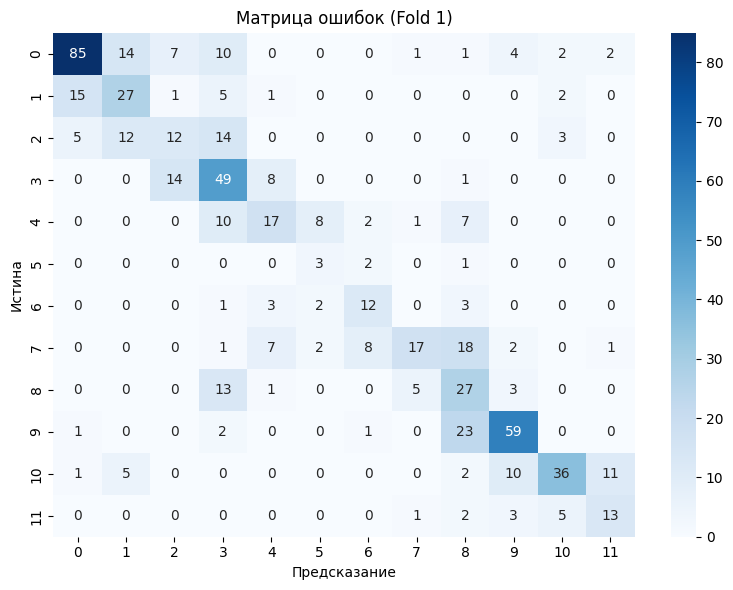

Fold 2
  Train wells: ['A1', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A2', 'C2', 'C7']
  Train: 2369 проб, Val: 658 проб
F1 macro (train): 0.9964
F1 macro (val):   0.6099
Gap (train-val):  0.3866

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8537    0.8333    0.8434        84
           1     0.3333    0.4211    0.3721        19
           2     0.5610    0.5227    0.5412        44
           3     0.7619    0.7273    0.7442        66
           4     0.6824    0.7733    0.7250        75
           5     0.2692    0.2059    0.2333        34
           6     0.5294    0.5625    0.5455        32
           7     0.4615    0.3243    0.3810        37
           8     0.5889    0.6092    0.5989        87
           9     0.7500    0.7190    0.7342       121
          10     0.5957    0.8000    0.6829        35
          11     0.9167    0.9167    0.9167        24

    accuracy                    

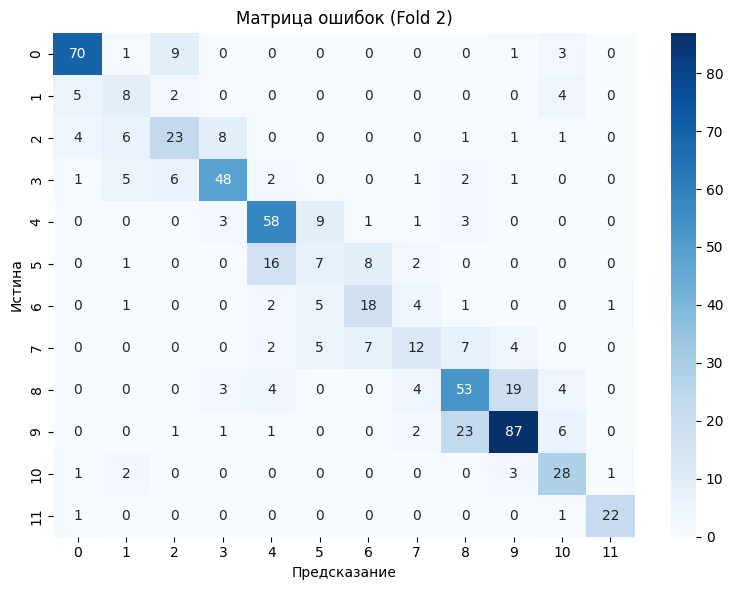

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2428 проб, Val: 599 проб
F1 macro (train): 0.9971
F1 macro (val):   0.5833
Gap (train-val):  0.4138

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8824    0.9600    0.9195       125
           1     0.6154    0.4444    0.5161        36
           2     0.7143    0.6250    0.6667        32
           3     0.4884    0.7000    0.5753        30
           4     0.5750    0.6389    0.6053        36
           5     0.4444    0.1111    0.1778        36
           6     0.4815    0.3939    0.4333        33
           7     0.4074    0.2750    0.3284        40
           8     0.5625    0.5114    0.5357        88
           9     0.5652    0.8333    0.6736        78
          10     0.8250    0.7333    0.7765        45
          11     0.6786    0.9500    0.7917        20

    accuracy                    

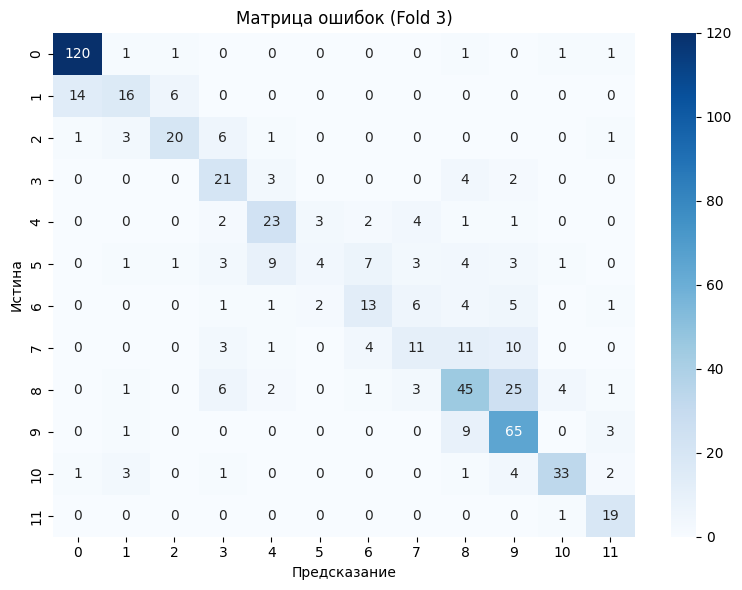

Fold 4
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'E1']
  Val wells:   ['B1', 'C3', 'D1']
  Train: 2465 проб, Val: 562 проб
F1 macro (train): 0.9967
F1 macro (val):   0.5607
Gap (train-val):  0.4359

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.8144    0.9186    0.8634        86
           1     0.5714    0.3529    0.4364        34
           2     0.4773    0.5676    0.5185        37
           3     0.7885    0.6508    0.7130        63
           4     0.6667    0.7500    0.7059        48
           5     0.3636    0.1143    0.1739        35
           6     0.4348    0.4348    0.4348        23
           7     0.3333    0.2632    0.2941        38
           8     0.3913    0.2951    0.3364        61
           9     0.5566    0.9365    0.6982        63
          10     0.7556    0.7907    0.7727        43
          11     0.7576    0.8065    0.7812        31

    accuracy                    

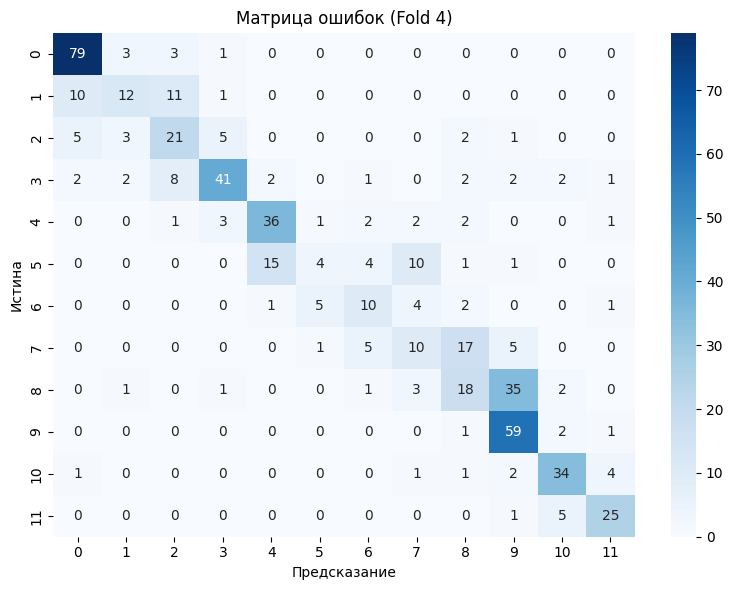

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2466 проб, Val: 561 проб
F1 macro (train): 0.9971
F1 macro (val):   0.4531
Gap (train-val):  0.5440

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.3095    0.9630    0.4685        27
           1     0.5000    0.3750    0.4286        16
           2     0.6316    0.5217    0.5714        23
           3     0.6667    0.7222    0.6933        36
           4     0.3902    0.5714    0.4638        28
           5     0.0714    0.0455    0.0556        22
           6     0.4211    0.3636    0.3902        22
           7     0.2917    0.3043    0.2979        23
           8     0.5057    0.5500    0.5269        80
           9     0.5691    0.5785    0.5738       121
          10     0.6364    0.6203    0.6282        79
          11     0.8182    0.2143    0.3396        84

    accuracy                    

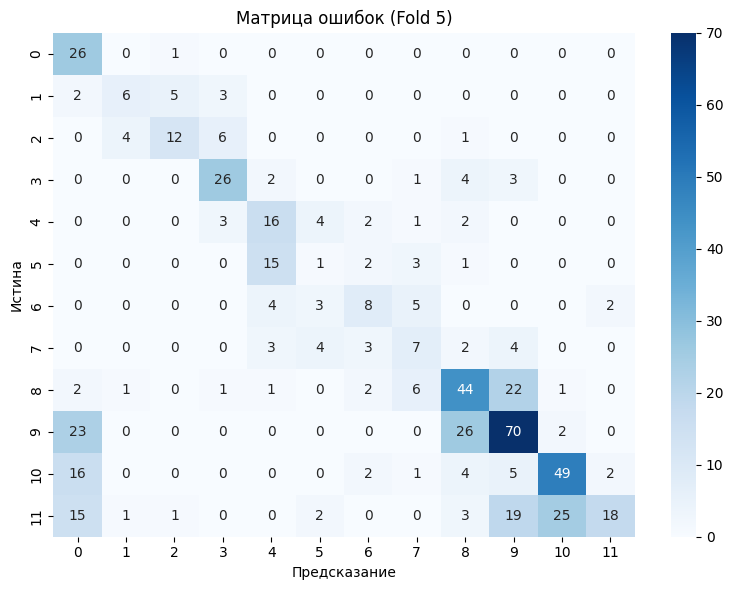

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4981
  Fold 2: F1_macro = 0.6099
  Fold 3: F1_macro = 0.5833
  Fold 4: F1_macro = 0.5607
  Fold 5: F1_macro = 0.4531

  Средний F1 macro: 0.5410 ± 0.0574

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.7510    0.8482    0.7966       448
           1     0.4894    0.4423    0.4646       156
           2     0.5301    0.4835    0.5057       182
           3     0.6126    0.6929    0.6503       267
           4     0.5837    0.6466    0.6135       232
           5     0.2533    0.1429    0.1827       133
           6     0.4766    0.4656    0.4710       131
           7     0.4318    0.2938    0.3497       194
           8     0.4820    0.5123    0.4967       365
           9     0.6285    0.7249    0.6733       469
          10     0.7004    0.6742    0.6870       267
          11     0.7239    0.5301    0.6120       183

    accuracy                         0.5989      

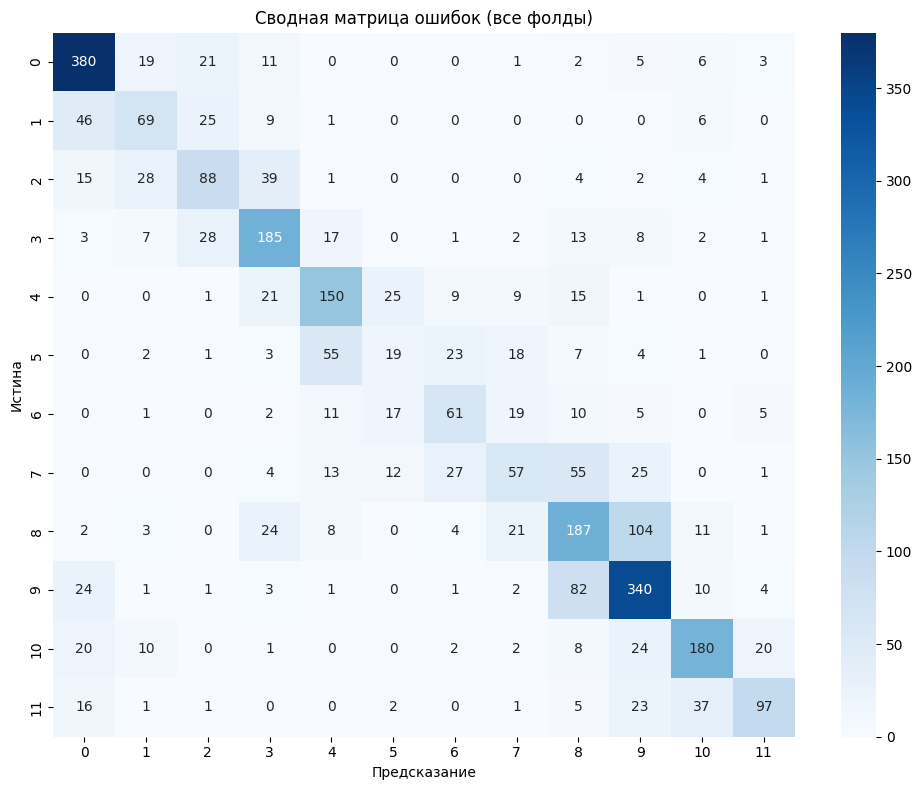

/tmp/ipykernel_18299/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to excl

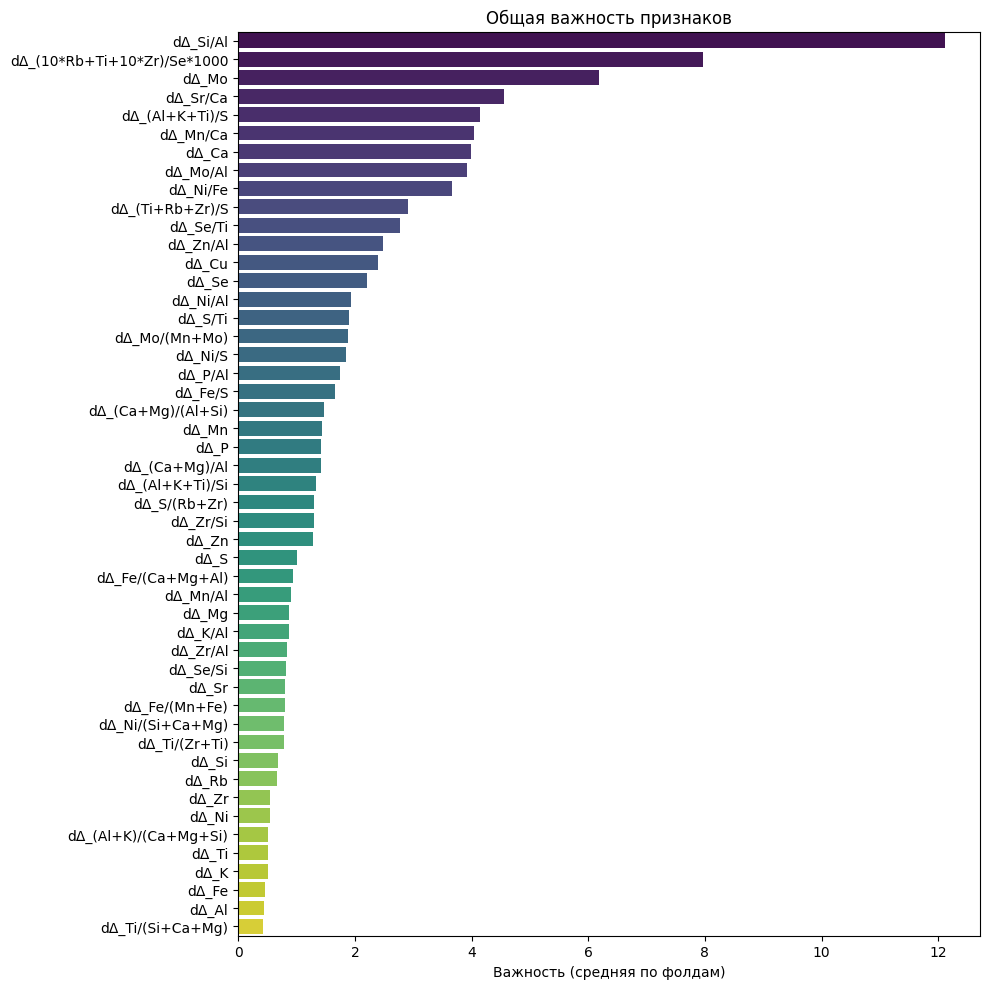

In [9]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Создание относительных градиентов rΔxi = xi / (xi-1 + epsilon)**

In [10]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

In [11]:
df = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

rgrad_features = []
for col in features:
    rgrad_col = f'rΔ_{col}'
    prev = df.groupby('Well')[col].shift(1)
    epsilon = df[col].median() * 0.01
    df[rgrad_col] = df[col] / (prev + epsilon)
    rgrad_features.append(rgrad_col)

print(f"Добавлено в df: {len(rgrad_features)} признаков")
print(f"Всего колонок: {len(df.columns)}")


Добавлено в df: 49 признаков
Всего колонок: 153


In [12]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', 'P_above_LOD', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(S

In [13]:
df

,Mg,Al,Si,P,S,K,Ca,Ti,Mn,Fe,...,rΔ_(Al+K+Ti)/Si,rΔ_(Al+K+Ti)/S,rΔ_(Ti+Rb+Zr)/S,rΔ_S/Ti,rΔ_Ni/Al,rΔ_Zn/Al,rΔ_Se/Si,rΔ_(Ca+Mg)/Al,rΔ_Se/Ti,rΔ_(10*Rb+Ti+10*Zr)/Se*1000
0,1.681623,5.706609,20.809375,0.000253,4.883089,0.358961,0.191912,0.192320,0.002664,2.455414,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.115326,4.681748,15.206337,0.000253,7.612235,0.274933,0.806966,0.159650,0.010551,4.272748,...,1.109444,0.518041,0.524705,1.865017,3.237942,5.727204,2.547699,1.877056,2.232775,0.429490
2,1.715452,4.620812,16.875374,0.000253,7.701370,0.243583,0.304632,0.155271,0.019363,4.095088,...,0.877435,0.947365,0.927322,1.036428,0.706369,0.199441,0.378171,0.695673,0.429975,2.143036
3,1.872067,5.503601,18.376529,0.000253,6.194391,0.398233,0.265514,0.173688,0.003095,3.032062,...,1.102044,1.469002,1.370100,0.716503,1.253908,1.507201,5.512075,0.879927,5.343186,0.195208
4,1.586948,4.797547,16.439092,0.000253,7.773937,0.291996,0.365831,0.165617,0.001955,4.114941,...,0.959528,0.678240,0.736549,1.309713,0.628004,0.602808,0.382185,1.036712,0.358216,2.548480
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3022,1.278100,8.616273,28.388951,0.007900,2.830361,2.901873,1.764976,0.510543,0.043224,3.233368,...,1.044690,0.378767,0.353761,2.600844,1.985757,0.181877,4.375933,0.565396,2.332458,0.064177
3023,1.309000,8.910452,26.883048,0.000253,5.503497,2.993462,0.962944,0.492751,0.045489,4.833295,...,1.081824,0.528044,0.494874,1.952872,1.274371,3.893828,2.175305,0.713409,1.819262,0.402545
3024,1.554100,8.413048,28.777198,0.023300,3.578398,2.912097,1.042116,0.470768,0.037091,3.431198,...,0.884029,1.453200,1.463576,0.670044,0.714024,1.166582,0.365757,1.190558,0.380384,2.321708
3025,0.941500,7.412025,30.434881,0.086501,3.803724,2.449646,1.119981,0.389820,0.033599,3.716377,...,0.816666,0.813669,0.770178,1.254743,0.405323,0.240794,1.943966,0.889094,2.165678,0.330498


**Сохзранения датасета со всеми новыми признаками**

In [14]:
#df.to_csv('Data/data_kern_ALLratios_16_10.csv', index=False)

#print(f"сохранено: ML_for_geochemistry/Data/data_kern_ALLratios_16_10.csv")
#print(f"проб: {len(df)}")
#print(f"колонок: {len(df.columns)}")

In [15]:
features = ['rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 'rΔ_K', 'rΔ_Ca', 
            'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 
            'rΔ_Rb', 'rΔ_Sr', 'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 
            'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 
            'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 
            'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 
            'rΔ_(Ti+Rb+Zr)/S', 'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 
            'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2380 проб, Val: 647 проб
F1 macro (train): 0.9961
F1 macro (val):   0.3757
Gap (train-val):  0.6204

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.6226    0.5238    0.5690       126
           1     0.5172    0.2941    0.3750        51
           2     0.2500    0.0870    0.1290        46
           3     0.4429    0.4306    0.4366        72
           4     0.3077    0.2667    0.2857        45
           5     0.1200    0.5000    0.1935         6
           6     0.3810    0.3810    0.3810        21
           7     0.4500    0.1607    0.2368        56
           8     0.2614    0.4694    0.3358        49
           9     0.4173    0.6744    0.5156        86
          10     0.4697    0.4769    0.4733        65
          11     0.5357    0.6250    0.5769        24

    accuracy                    

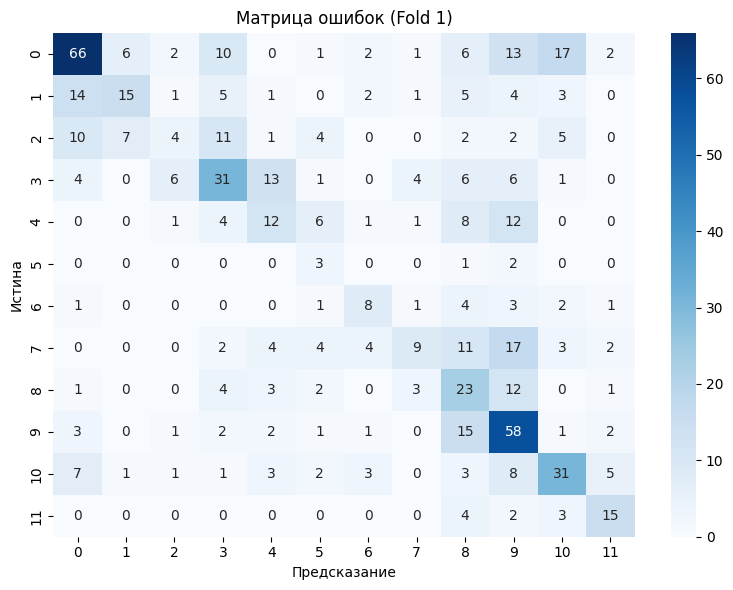

Fold 2
  Train wells: ['A1', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A2', 'C2', 'C7']
  Train: 2369 проб, Val: 658 проб
F1 macro (train): 0.9953
F1 macro (val):   0.4840
Gap (train-val):  0.5114

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.6667    0.7143    0.6897        84
           1     0.2581    0.4211    0.3200        19
           2     0.4468    0.4773    0.4615        44
           3     0.5577    0.4394    0.4915        66
           4     0.5974    0.6133    0.6053        75
           5     0.2500    0.1765    0.2069        34
           6     0.4286    0.3750    0.4000        32
           7     0.3913    0.2432    0.3000        37
           8     0.4762    0.4598    0.4678        87
           9     0.5906    0.6198    0.6048       121
          10     0.3962    0.6000    0.4773        35
          11     0.8182    0.7500    0.7826        24

    accuracy                    

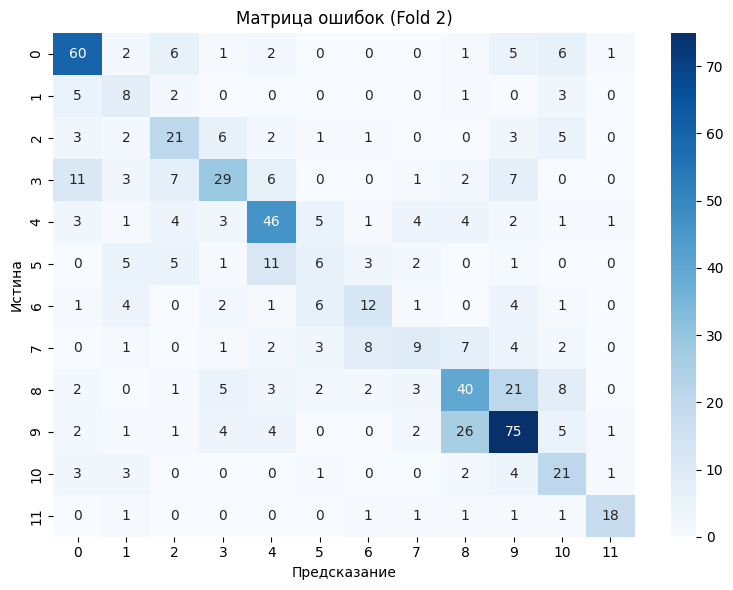

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2428 проб, Val: 599 проб
F1 macro (train): 0.9940
F1 macro (val):   0.4220
Gap (train-val):  0.5720

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8487    0.8080    0.8279       125
           1     0.5455    0.3333    0.4138        36
           2     0.5000    0.4062    0.4483        32
           3     0.4074    0.3667    0.3860        30
           4     0.4667    0.5833    0.5185        36
           5     0.0000    0.0000    0.0000        36
           6     0.1053    0.0606    0.0769        33
           7     0.2683    0.2750    0.2716        40
           8     0.4545    0.5114    0.4813        88
           9     0.3750    0.5385    0.4421        78
          10     0.6000    0.6667    0.6316        45
          11     0.4545    0.7500    0.5660        20

    accuracy                    

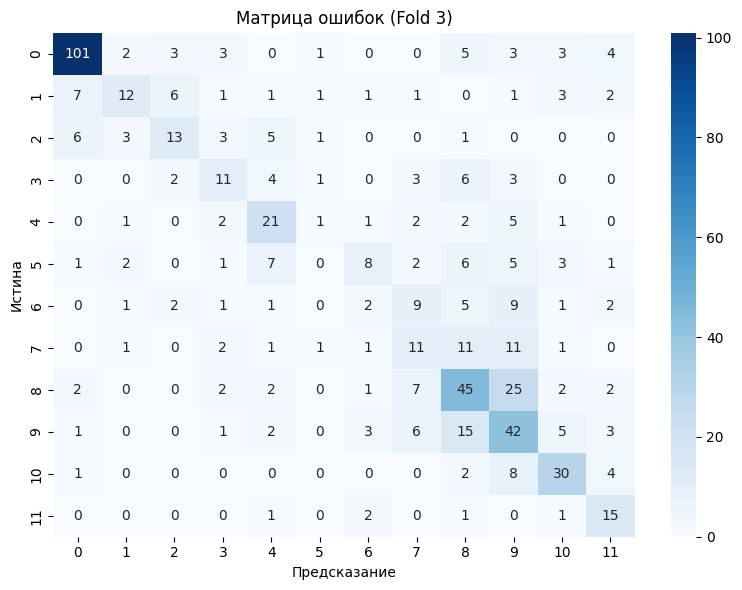

Fold 4
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'E1']
  Val wells:   ['B1', 'C3', 'D1']
  Train: 2465 проб, Val: 562 проб
F1 macro (train): 0.9930
F1 macro (val):   0.4332
Gap (train-val):  0.5598

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.7471    0.7558    0.7514        86
           1     0.3529    0.3529    0.3529        34
           2     0.4000    0.4324    0.4156        37
           3     0.6098    0.3968    0.4808        63
           4     0.4754    0.6042    0.5321        48
           5     0.4000    0.1143    0.1778        35
           6     0.2400    0.2609    0.2500        23
           7     0.3571    0.1316    0.1923        38
           8     0.3214    0.2951    0.3077        61
           9     0.4545    0.7937    0.5780        63
          10     0.5517    0.7442    0.6337        43
          11     0.5769    0.4839    0.5263        31

    accuracy                    

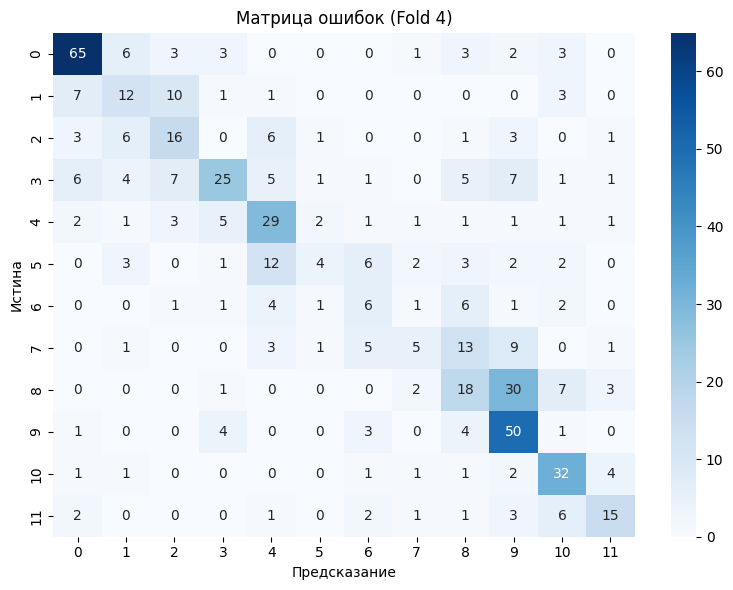

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2466 проб, Val: 561 проб
F1 macro (train): 0.9953
F1 macro (val):   0.2813
Gap (train-val):  0.7139

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.1729    0.8519    0.2875        27
           1     0.4167    0.3125    0.3571        16
           2     0.5455    0.2609    0.3529        23
           3     0.4828    0.3889    0.4308        36
           4     0.1667    0.2500    0.2000        28
           5     0.0000    0.0000    0.0000        22
           6     0.2857    0.2727    0.2791        22
           7     0.1250    0.1304    0.1277        23
           8     0.3939    0.4875    0.4358        80
           9     0.3445    0.3388    0.3417       121
          10     0.5532    0.3291    0.4127        79
          11     0.7778    0.0833    0.1505        84

    accuracy                    

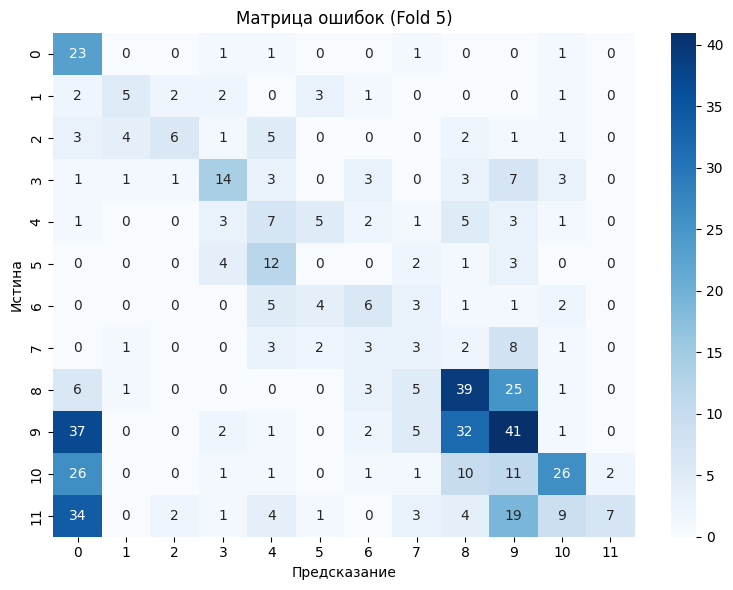

Результаты кросс-валидации
  Fold 1: F1_macro = 0.3757
  Fold 2: F1_macro = 0.4840
  Fold 3: F1_macro = 0.4220
  Fold 4: F1_macro = 0.4332
  Fold 5: F1_macro = 0.2813

  Средний F1 macro: 0.3992 ± 0.0683

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.5888    0.7031    0.6409       448
           1     0.4062    0.3333    0.3662       156
           2     0.4286    0.3297    0.3727       182
           3     0.5023    0.4120    0.4527       267
           4     0.4356    0.4957    0.4637       232
           5     0.1625    0.0977    0.1221       133
           6     0.2982    0.2595    0.2776       131
           7     0.3033    0.1907    0.2342       194
           8     0.3873    0.4521    0.4172       365
           9     0.4382    0.5672    0.4944       469
          10     0.5109    0.5243    0.5176       267
          11     0.5932    0.3825    0.4651       183

    accuracy                         0.4549      

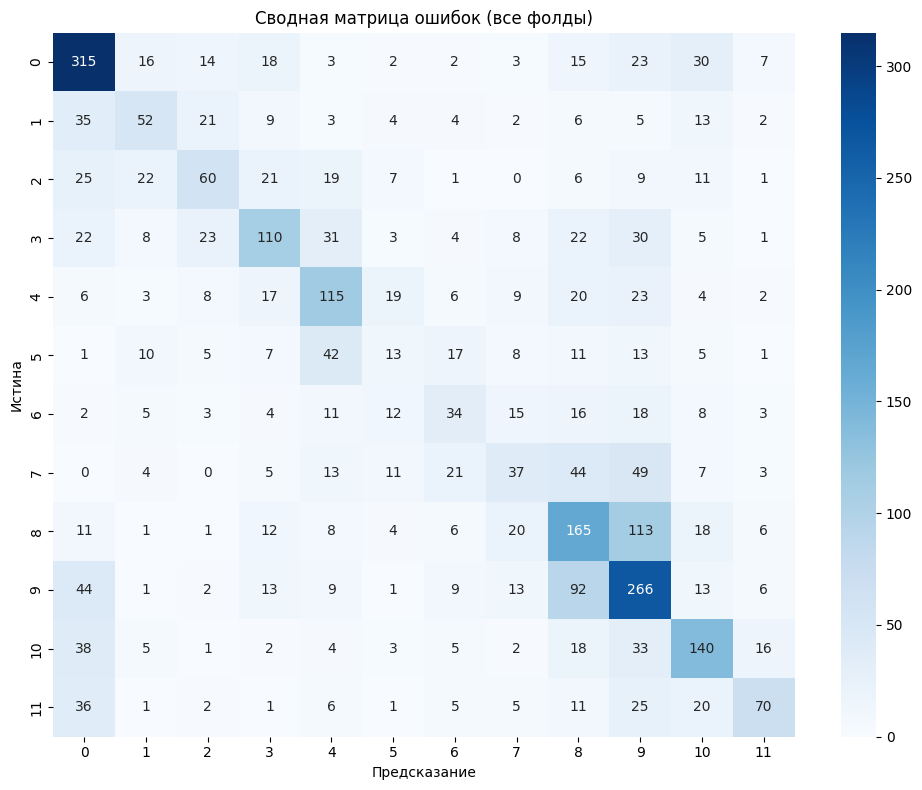

/tmp/ipykernel_18299/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to excl

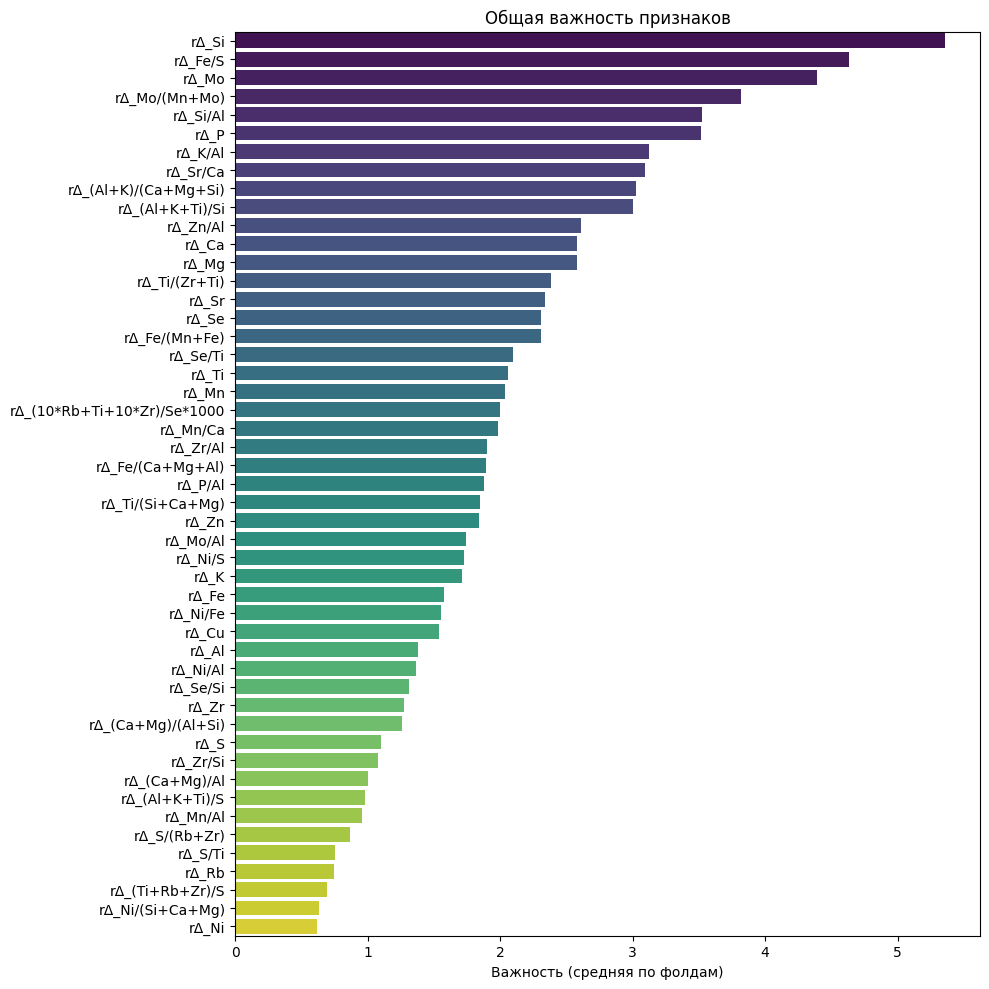

In [16]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

In [17]:
features = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 
            'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 
            'Mo', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 
            'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 
            'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 
            'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', 
            '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 
            'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 
            'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 
            'rΔ_K', 'rΔ_Ca', 'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 'rΔ_Rb', 'rΔ_Sr', 
            'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 
            'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 'rΔ_(Ti+Rb+Zr)/S', 
            'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

In [18]:
print(len(features))

147


Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2380 проб, Val: 647 проб
F1 macro (train): 0.9984
F1 macro (val):   0.5590
Gap (train-val):  0.4394

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9432    0.6587    0.7757       126
           1     0.6111    0.4314    0.5057        51
           2     0.3182    0.6087    0.4179        46
           3     0.5248    0.7361    0.6127        72
           4     0.5918    0.6444    0.6170        45
           5     0.3000    0.5000    0.3750         6
           6     0.4583    0.5238    0.4889        21
           7     0.7083    0.3036    0.4250        56
           8     0.3467    0.5306    0.4194        49
           9     0.7111    0.7442    0.7273        86
          10     0.8667    0.6000    0.7091        65
          11     0.7647    0.5417    0.6341        24

    accuracy                    

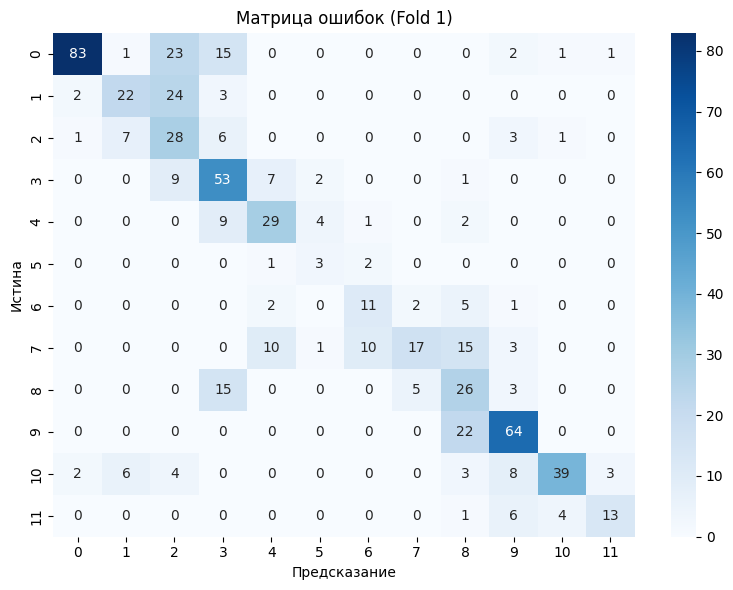

Fold 2
  Train wells: ['A1', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A2', 'C2', 'C7']
  Train: 2369 проб, Val: 658 проб
F1 macro (train): 0.9985
F1 macro (val):   0.6998
Gap (train-val):  0.2987

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9221    0.8452    0.8820        84
           1     0.4583    0.5789    0.5116        19
           2     0.5600    0.6364    0.5957        44
           3     0.8644    0.7727    0.8160        66
           4     0.6863    0.9333    0.7910        75
           5     0.5652    0.3824    0.4561        34
           6     0.5161    0.5000    0.5079        32
           7     0.5833    0.3784    0.4590        37
           8     0.7126    0.7126    0.7126        87
           9     0.8443    0.8512    0.8477       121
          10     0.8378    0.8857    0.8611        35
          11     1.0000    0.9167    0.9565        24

    accuracy                    

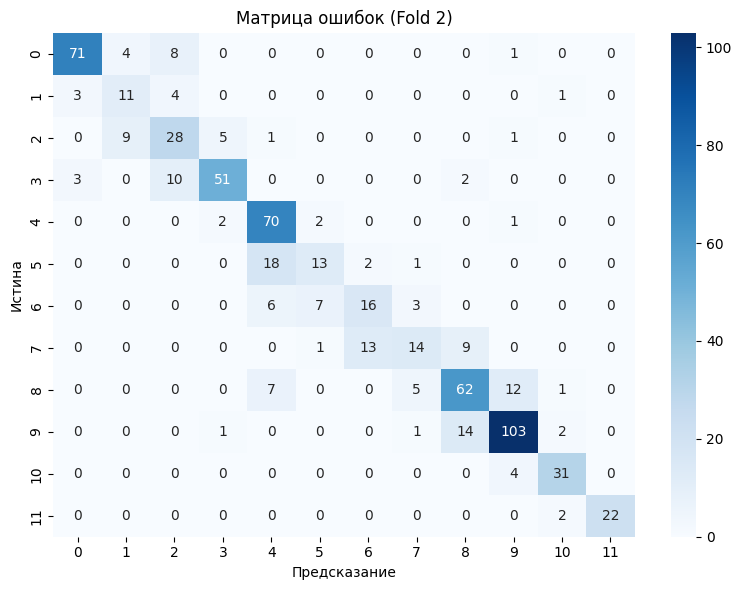

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2428 проб, Val: 599 проб
F1 macro (train): 0.9980
F1 macro (val):   0.6559
Gap (train-val):  0.3421

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9462    0.9840    0.9647       125
           1     0.8519    0.6389    0.7302        36
           2     0.7037    0.5938    0.6441        32
           3     0.7188    0.7667    0.7419        30
           4     0.6216    0.6389    0.6301        36
           5     0.4000    0.2222    0.2857        36
           6     0.2941    0.1515    0.2000        33
           7     0.3750    0.3000    0.3333        40
           8     0.6083    0.8295    0.7019        88
           9     0.7500    0.8462    0.7952        78
          10     0.8723    0.9111    0.8913        45
          11     0.9091    1.0000    0.9524        20

    accuracy                    

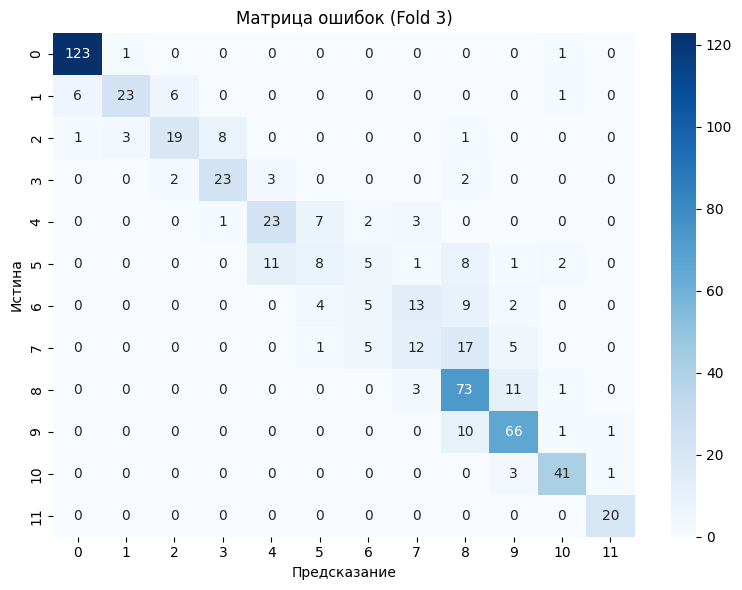

Fold 4
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'E1']
  Val wells:   ['B1', 'C3', 'D1']
  Train: 2465 проб, Val: 562 проб
F1 macro (train): 0.9982
F1 macro (val):   0.6008
Gap (train-val):  0.3974

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9412    0.9302    0.9357        86
           1     0.5714    0.4706    0.5161        34
           2     0.4038    0.5676    0.4719        37
           3     0.7593    0.6508    0.7009        63
           4     0.7037    0.7917    0.7451        48
           5     0.3636    0.1143    0.1739        35
           6     0.2857    0.3478    0.3137        23
           7     0.4815    0.3421    0.4000        38
           8     0.5091    0.4590    0.4828        61
           9     0.6146    0.9365    0.7421        63
          10     0.8605    0.8605    0.8605        43
          11     0.8966    0.8387    0.8667        31

    accuracy                    

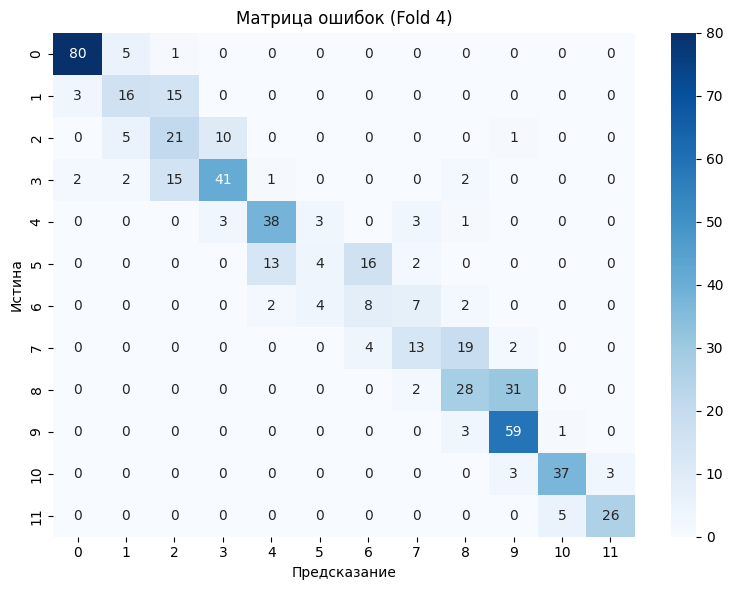

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2466 проб, Val: 561 проб
F1 macro (train): 0.9964
F1 macro (val):   0.5719
Gap (train-val):  0.4245

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.6585    1.0000    0.7941        27
           1     0.7143    0.3125    0.4348        16
           2     0.6250    0.6522    0.6383        23
           3     0.8158    0.8611    0.8378        36
           4     0.4894    0.8214    0.6133        28
           5     0.2000    0.1364    0.1622        22
           6     0.5238    0.5000    0.5116        22
           7     0.1538    0.1739    0.1633        23
           8     0.5844    0.5625    0.5732        80
           9     0.7154    0.7686    0.7410       121
          10     0.7033    0.8101    0.7529        79
          11     0.9318    0.4881    0.6406        84

    accuracy                    

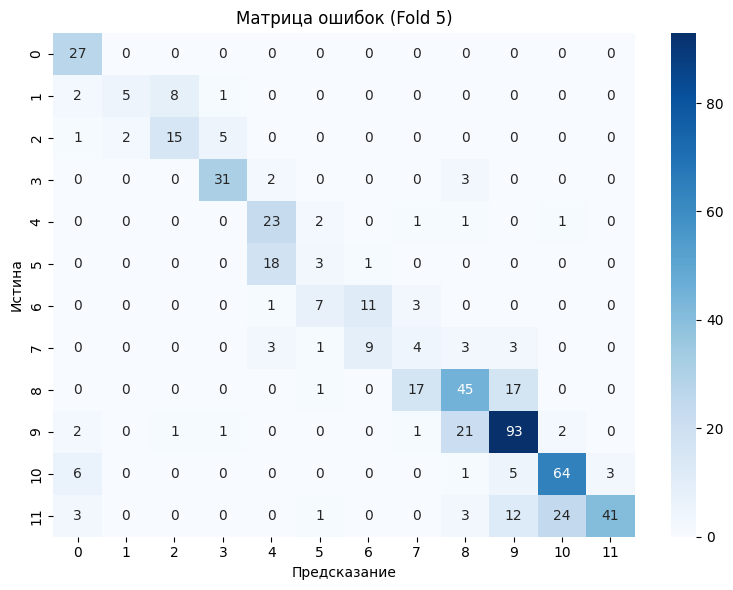

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5590
  Fold 2: F1_macro = 0.6998
  Fold 3: F1_macro = 0.6559
  Fold 4: F1_macro = 0.6008
  Fold 5: F1_macro = 0.5719

  Средний F1 macro: 0.6175 ± 0.0530

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9121    0.8571    0.8838       448
           1     0.6311    0.4936    0.5540       156
           2     0.4606    0.6099    0.5248       182
           3     0.7007    0.7453    0.7223       267
           4     0.6332    0.7888    0.7025       232
           5     0.3924    0.2331    0.2925       133
           6     0.4215    0.3893    0.4048       131
           7     0.4511    0.3093    0.3670       194
           8     0.5652    0.6411    0.6008       365
           9     0.7319    0.8209    0.7739       469
          10     0.8061    0.7940    0.8000       267
          11     0.9104    0.6667    0.7697       183

    accuracy                         0.6769      

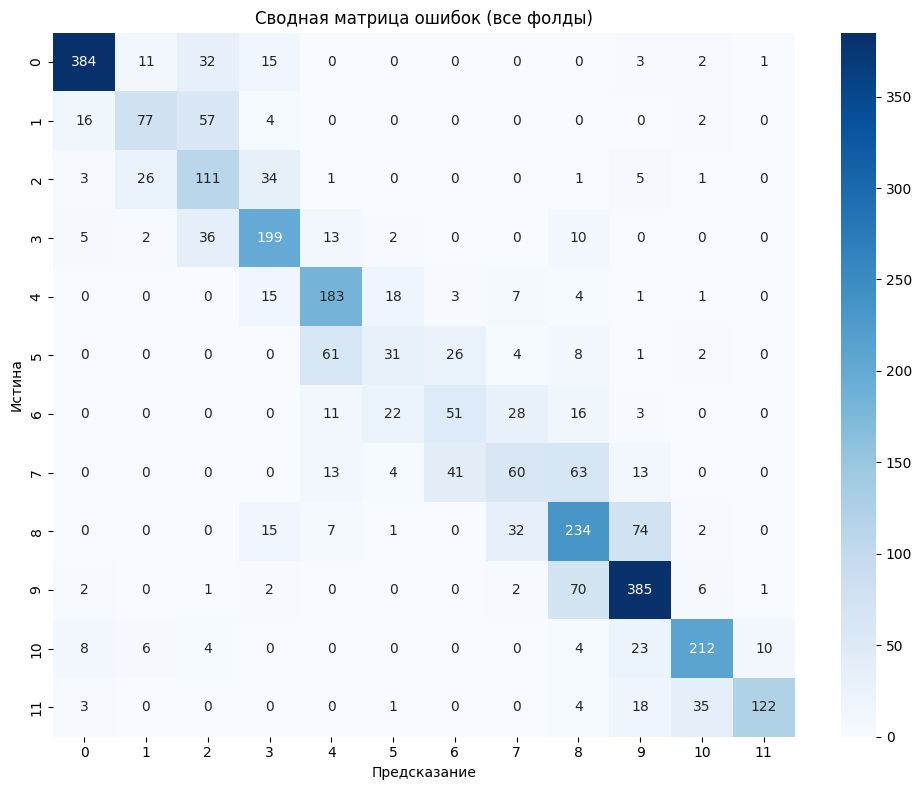

/tmp/ipykernel_18299/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to excl

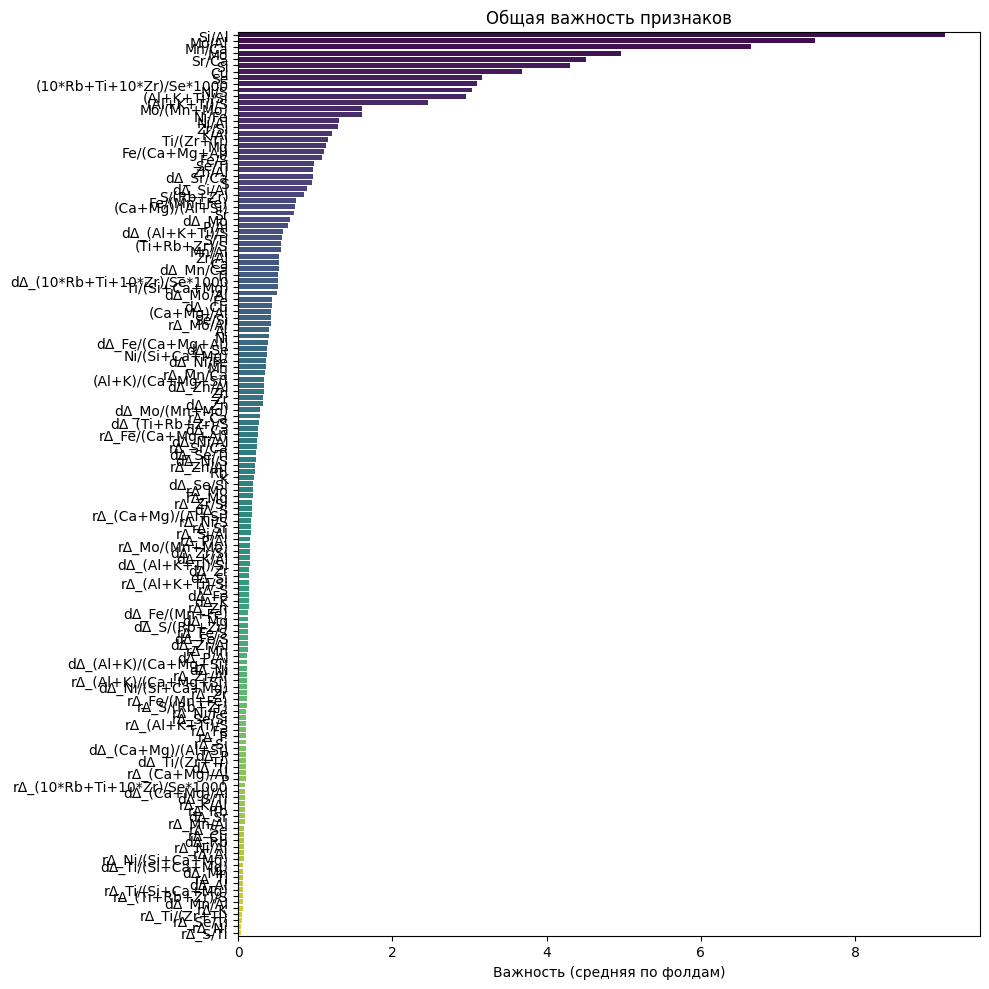

In [19]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

In [20]:
def permutation_importance_custom(model, X_val, y_val, 
                                   features_list, n_repeats=3, 
                                   random_state=42):
    rng = np.random.RandomState(random_state)
    baseline = f1_score(y_val, model.predict(X_val), average='macro')
    print(f"Baseline F1 macro: {baseline:.4f}\n")
    
    results = []
    for i, col in enumerate(features_list):
        scores = []
        for _ in range(n_repeats):
            X_permuted = X_val.copy()
            X_permuted.iloc[:, i] = rng.permutation(X_permuted.iloc[:, i].values)
            score = f1_score(y_val, model.predict(X_permuted), average='macro')
            scores.append(score)
        drop = baseline - np.mean(scores)
        results.append((col, drop, np.std(scores)))
        if (i + 1) % 10 == 0:
            print(f"Processed {i+1}/{len(features_list)}")
    
    results.sort(key=lambda x: x[1], reverse=True)
    return results

perm_results = permutation_importance_custom(
    model, X_vl, y_vl, 
    features_list=X_vl.columns.tolist(),
    n_repeats=3
)

print(f"\n{'Признак':<45} {'Drop F1':>10} {'Std':>8}")

for col, drop, std in perm_results[:30]:
    print(f"{col:<45} {drop:>10.4f} {std:>8.4f}")

# Признаки с drop <= 0 — можно удалить
useless = [(col, drop) for col, drop, std in perm_results if drop <= 0]
print(f"\nБесполезных признаков (drop <= 0): {len(useless)}")


Baseline F1 macro: 0.5719

Processed 10/147
Processed 20/147
Processed 30/147
Processed 40/147
Processed 50/147
Processed 60/147
Processed 70/147
Processed 80/147
Processed 90/147
Processed 100/147
Processed 110/147
Processed 120/147
Processed 130/147
Processed 140/147

Признак                                          Drop F1      Std
Mo/Al                                             0.0401   0.0066
Sr/Ca                                             0.0356   0.0057
Si/Al                                             0.0288   0.0077
Si                                                0.0231   0.0031
Mo                                                0.0188   0.0041
Mn/Ca                                             0.0182   0.0088
Ni/Fe                                             0.0159   0.0006
P/Al                                              0.0135   0.0043
Fe/(Ca+Mg+Al)                                     0.0123   0.0030
(Al+K+Ti)/S                                       0.0120   0.0025
Ni/

**Отбор признаков с permutation_importance**

**n_folds_useful >= 3**

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2380 проб, Val: 647 проб
F1 macro (train): 0.9984
F1 macro (val):   0.5590
Gap (train-val):  0.4394

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9432    0.6587    0.7757       126
           1     0.6111    0.4314    0.5057        51
           2     0.3182    0.6087    0.4179        46
           3     0.5248    0.7361    0.6127        72
           4     0.5918    0.6444    0.6170        45
           5     0.3000    0.5000    0.3750         6
           6     0.4583    0.5238    0.4889        21
           7     0.7083    0.3036    0.4250        56
           8     0.3467    0.5306    0.4194        49
           9     0.7111    0.7442    0.7273        86
          10     0.8667    0.6000    0.7091        65
          11     0.7647    0.5417    0.6341        24

    accuracy                    

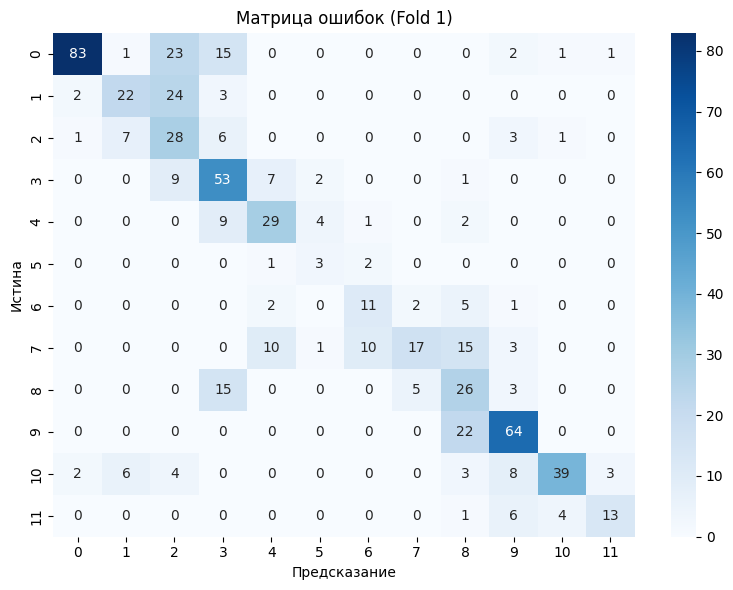

Fold 2
  Train wells: ['A1', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A2', 'C2', 'C7']
  Train: 2369 проб, Val: 658 проб
F1 macro (train): 0.9985
F1 macro (val):   0.6998
Gap (train-val):  0.2987

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9221    0.8452    0.8820        84
           1     0.4583    0.5789    0.5116        19
           2     0.5600    0.6364    0.5957        44
           3     0.8644    0.7727    0.8160        66
           4     0.6863    0.9333    0.7910        75
           5     0.5652    0.3824    0.4561        34
           6     0.5161    0.5000    0.5079        32
           7     0.5833    0.3784    0.4590        37
           8     0.7126    0.7126    0.7126        87
           9     0.8443    0.8512    0.8477       121
          10     0.8378    0.8857    0.8611        35
          11     1.0000    0.9167    0.9565        24

    accuracy                    

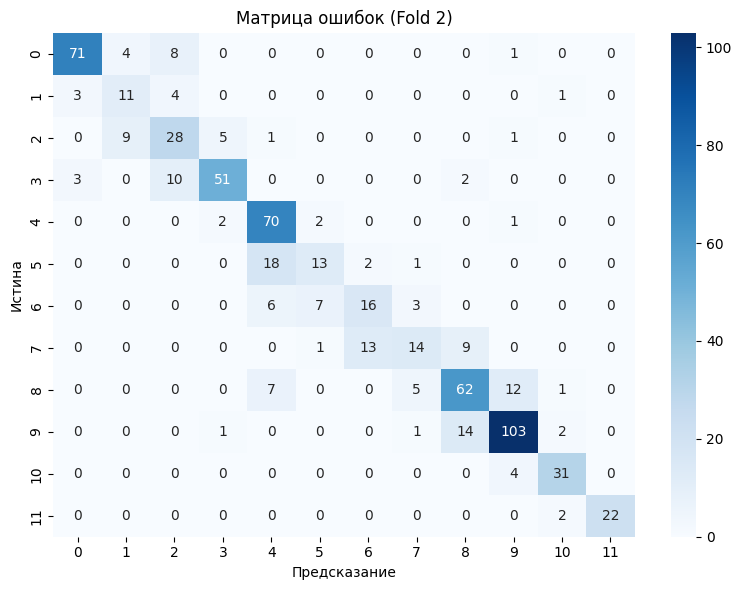

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2428 проб, Val: 599 проб
F1 macro (train): 0.9980
F1 macro (val):   0.6559
Gap (train-val):  0.3421

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9462    0.9840    0.9647       125
           1     0.8519    0.6389    0.7302        36
           2     0.7037    0.5938    0.6441        32
           3     0.7188    0.7667    0.7419        30
           4     0.6216    0.6389    0.6301        36
           5     0.4000    0.2222    0.2857        36
           6     0.2941    0.1515    0.2000        33
           7     0.3750    0.3000    0.3333        40
           8     0.6083    0.8295    0.7019        88
           9     0.7500    0.8462    0.7952        78
          10     0.8723    0.9111    0.8913        45
          11     0.9091    1.0000    0.9524        20

    accuracy                    

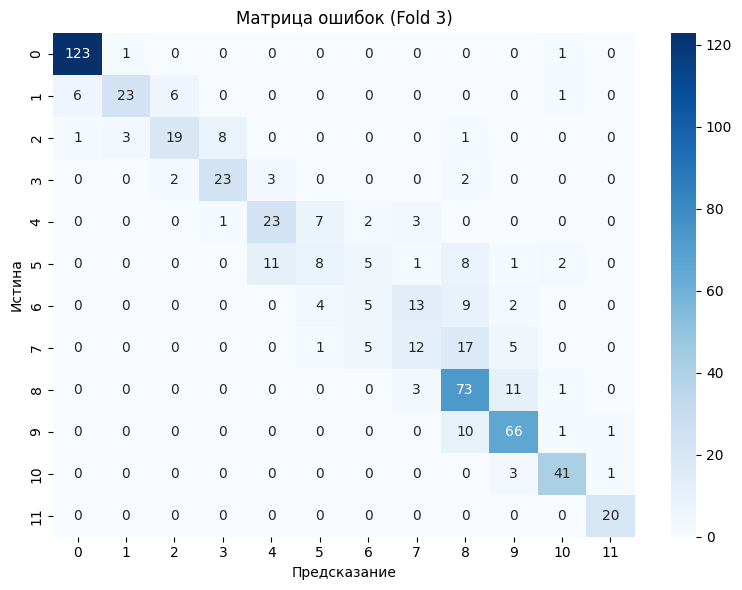

Fold 4
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'E1']
  Val wells:   ['B1', 'C3', 'D1']
  Train: 2465 проб, Val: 562 проб
F1 macro (train): 0.9982
F1 macro (val):   0.6008
Gap (train-val):  0.3974

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9412    0.9302    0.9357        86
           1     0.5714    0.4706    0.5161        34
           2     0.4038    0.5676    0.4719        37
           3     0.7593    0.6508    0.7009        63
           4     0.7037    0.7917    0.7451        48
           5     0.3636    0.1143    0.1739        35
           6     0.2857    0.3478    0.3137        23
           7     0.4815    0.3421    0.4000        38
           8     0.5091    0.4590    0.4828        61
           9     0.6146    0.9365    0.7421        63
          10     0.8605    0.8605    0.8605        43
          11     0.8966    0.8387    0.8667        31

    accuracy                    

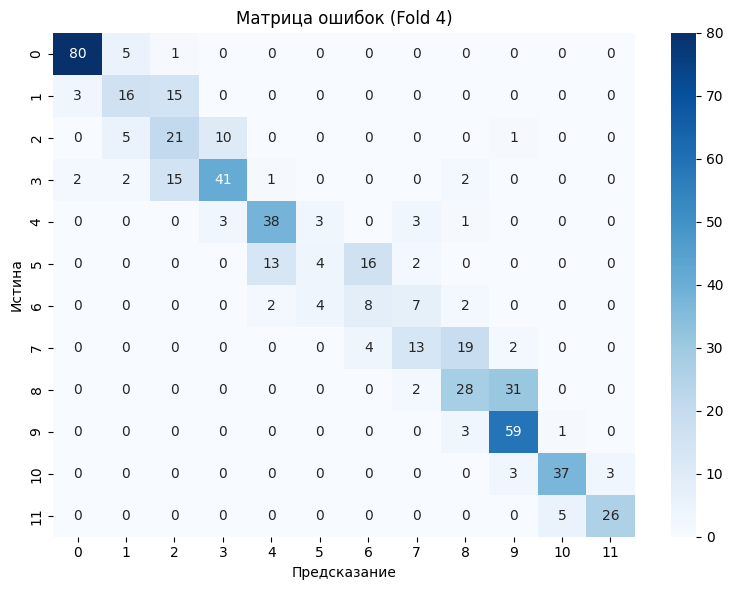

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2466 проб, Val: 561 проб
F1 macro (train): 0.9964
F1 macro (val):   0.5719
Gap (train-val):  0.4245

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.6585    1.0000    0.7941        27
           1     0.7143    0.3125    0.4348        16
           2     0.6250    0.6522    0.6383        23
           3     0.8158    0.8611    0.8378        36
           4     0.4894    0.8214    0.6133        28
           5     0.2000    0.1364    0.1622        22
           6     0.5238    0.5000    0.5116        22
           7     0.1538    0.1739    0.1633        23
           8     0.5844    0.5625    0.5732        80
           9     0.7154    0.7686    0.7410       121
          10     0.7033    0.8101    0.7529        79
          11     0.9318    0.4881    0.6406        84

    accuracy                    

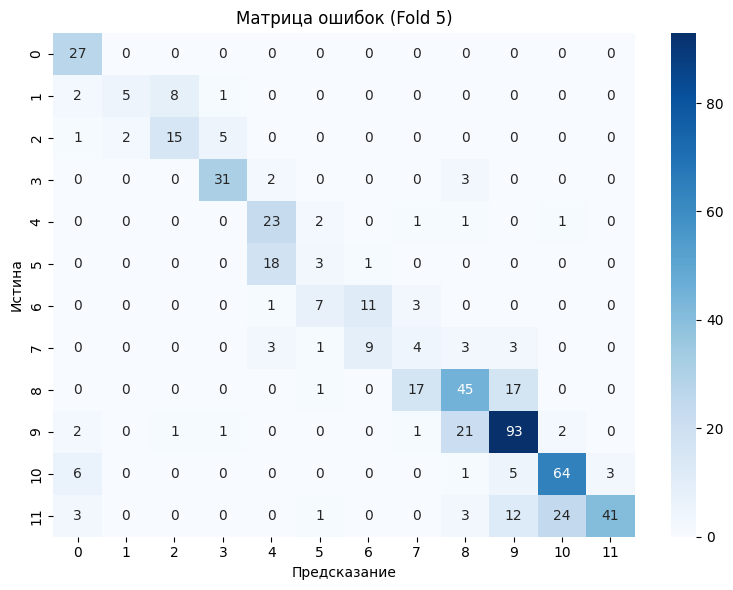

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5590
  Fold 2: F1_macro = 0.6998
  Fold 3: F1_macro = 0.6559
  Fold 4: F1_macro = 0.6008
  Fold 5: F1_macro = 0.5719

  Средний F1 macro: 0.6175 ± 0.0530

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9121    0.8571    0.8838       448
           1     0.6311    0.4936    0.5540       156
           2     0.4606    0.6099    0.5248       182
           3     0.7007    0.7453    0.7223       267
           4     0.6332    0.7888    0.7025       232
           5     0.3924    0.2331    0.2925       133
           6     0.4215    0.3893    0.4048       131
           7     0.4511    0.3093    0.3670       194
           8     0.5652    0.6411    0.6008       365
           9     0.7319    0.8209    0.7739       469
          10     0.8061    0.7940    0.8000       267
          11     0.9104    0.6667    0.7697       183

    accuracy                         0.6769      

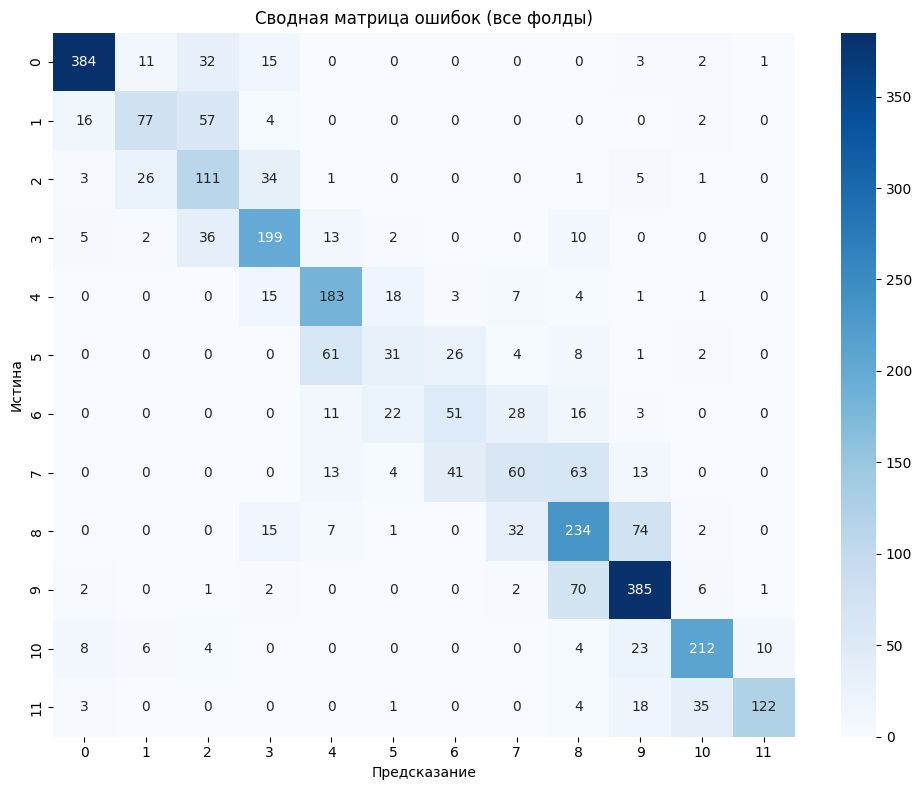

/tmp/ipykernel_18299/2617838196.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to excl

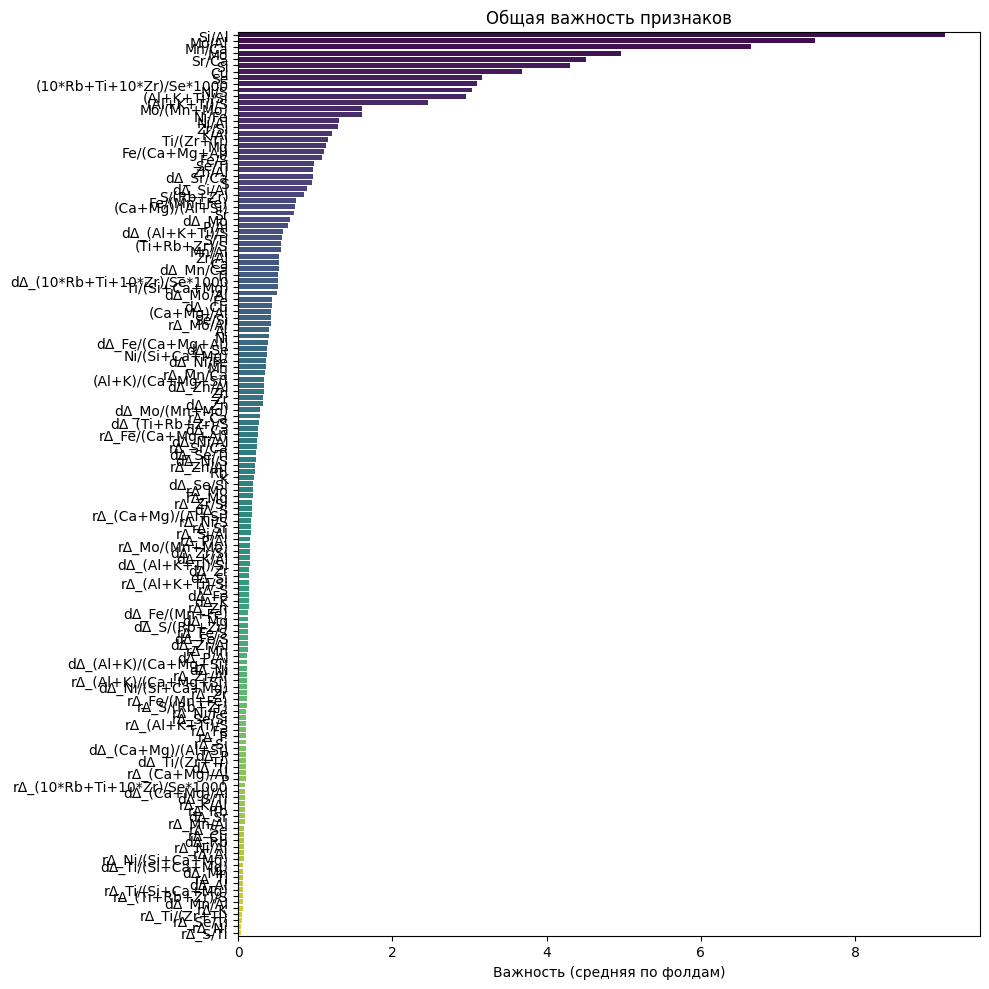


Permutation Importance (агрегировано по 5 фолдам)
Полезных на >=4 фолдах: 67 из 147

Топ:
                    feature  n_folds_useful  mean_drop  std_drop
                      Mo/Al               5   0.032770  0.016269
                      Si/Al               5   0.031414  0.004808
                      Sr/Ca               5   0.029256  0.010054
                      Mn/Ca               5   0.027624  0.015344
                         Mo               5   0.023190  0.020841
                         Si               5   0.015066  0.005410
                       P/Al               5   0.007565  0.003136
                   dΔ_Si/Al               5   0.005555  0.003501
           dΔ_Fe/(Ca+Mg+Al)               5   0.005023  0.004506
              rΔ_Mo/(Mn+Mo)               5   0.004796  0.002228
                   dΔ_Sr/Ca               5   0.004158  0.002787
                   rΔ_Mo/Al               5   0.003739  0.002952
                         Fe               5   0.003346  0.001885

/tmp/ipykernel_18299/2617838196.py:176: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='mean_drop', y='feature', data=top30, palette='rocket')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings

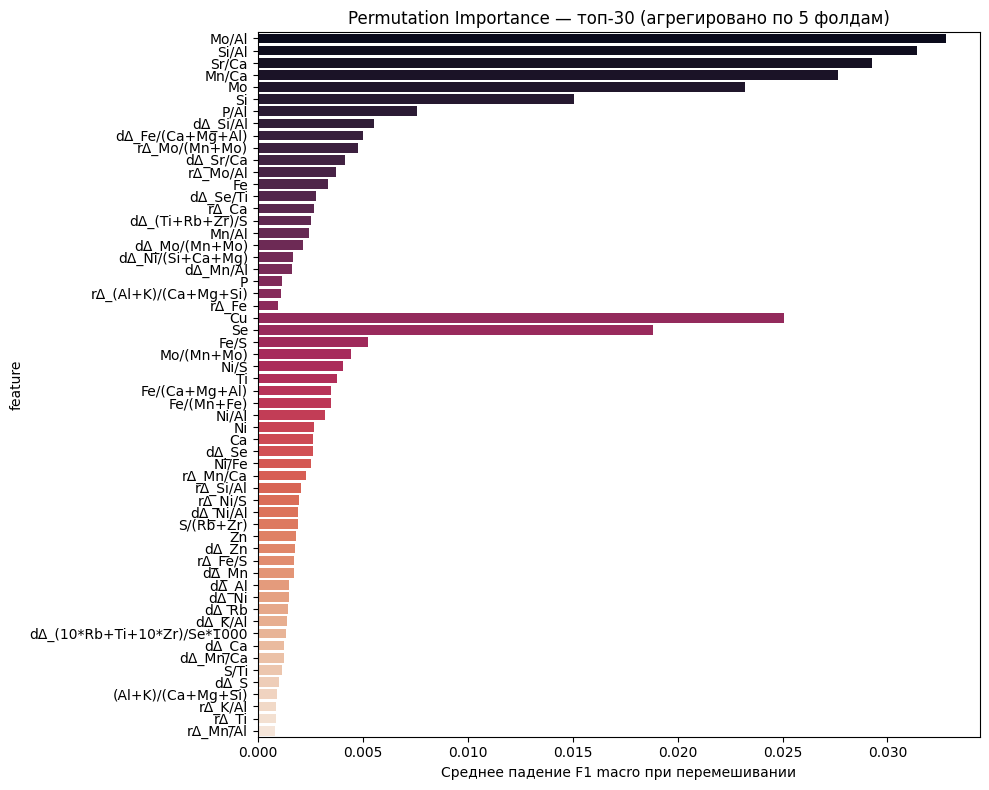


Стабильных признаков: 67
['Mo/Al', 'Si/Al', 'Sr/Ca', 'Mn/Ca', 'Mo', 'Si', 'P/Al', 'dΔ_Si/Al', 'dΔ_Fe/(Ca+Mg+Al)', 'rΔ_Mo/(Mn+Mo)', 'dΔ_Sr/Ca', 'rΔ_Mo/Al', 'Fe', 'dΔ_Se/Ti', 'rΔ_Ca', 'dΔ_(Ti+Rb+Zr)/S', 'Mn/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Mn/Al', 'P', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Fe', 'Cu', 'Se', 'Fe/S', 'Mo/(Mn+Mo)', 'Ni/S', 'Ti', 'Fe/(Ca+Mg+Al)', 'Fe/(Mn+Fe)', 'Ni/Al', 'Ni', 'Ca', 'dΔ_Se', 'Ni/Fe', 'rΔ_Mn/Ca', 'rΔ_Si/Al', 'rΔ_Ni/S', 'dΔ_Ni/Al', 'S/(Rb+Zr)', 'Zn', 'dΔ_Zn', 'rΔ_Fe/S', 'dΔ_Mn', 'dΔ_Al', 'dΔ_Ni', 'dΔ_Rb', 'dΔ_K/Al', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Ca', 'dΔ_Mn/Ca', 'S/Ti', 'dΔ_S', '(Al+K)/(Ca+Mg+Si)', 'rΔ_K/Al', 'rΔ_Ti', 'rΔ_Mn/Al', 'dΔ_Si', 'rΔ_Ni/Fe', 'rΔ_(Al+K+Ti)/S', 'rΔ_Ni', 'rΔ_Zn', 'rΔ_Mg', 'rΔ_K', 'dΔ_Zr/Si', 'dΔ_Fe/S']


In [21]:
from sklearn.metrics import f1_score
import numpy as np

X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []
importance_all = []

# Накопитель для permutation importance
perm_all = []  # список dict: {feature: drop_f1} для каждого фолда

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    shap_per_class = shap_values[:, :, :-1]
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Permutation importance для текущего фолда
    rng = np.random.RandomState(42)
    perm_results = {}
    for i, col in enumerate(X_vl.columns):
        scores = []
        for _ in range(3):
            X_perm = X_vl.copy()
            X_perm.iloc[:, i] = rng.permutation(X_perm.iloc[:, i].values)
            scores.append(f1_score(y_vl, model.predict(X_perm), average='macro'))
        perm_results[col] = f1_val - np.mean(scores)
    perm_all.append(perm_results)
    print(f"  Permutation importance посчитан для {len(perm_results)} признаков")

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

# ── Permutation Importance: агрегация по фолдам ──
n_folds = len(perm_all)
# min_folds_useful = n_folds // 2 + 1  # больше половины фолдов
min_folds_useful = 4
perm_summary = pd.DataFrame({
    'feature': features,
    'n_folds_useful': [sum(1 for res in perm_all if res[col] > 0) for col in features],
    'mean_drop': [np.mean([res[col] for res in perm_all]) for col in features],
    'std_drop': [np.std([res[col] for res in perm_all]) for col in features]
}).sort_values(['n_folds_useful', 'mean_drop'], ascending=[False, False])

print(f"\nPermutation Importance (агрегировано по {n_folds} фолдам)")
print(f"Полезных на >={min_folds_useful} фолдах: "
      f"{(perm_summary['n_folds_useful'] >= min_folds_useful).sum()} из {len(features)}")
print(f"\nТоп:")
print(perm_summary.head(58).to_string(index=False))

print(f"\nБесполезные на всех фолдах (n_folds_useful=0): "
      f"{(perm_summary['n_folds_useful'] == 0).sum()}")

# Топ-30 permutation importance
plt.figure(figsize=(10, 8))
top30 = perm_summary.head(58)
sns.barplot(x='mean_drop', y='feature', data=top30, palette='rocket')
plt.xlabel('Среднее падение F1 macro при перемешивании')
plt.title(f'Permutation Importance — топ-30 (агрегировано по {n_folds} фолдам)')
plt.tight_layout()
plt.show()

# Список стабильных признаков
stable_features = perm_summary[perm_summary['n_folds_useful'] >= min_folds_useful]['feature'].tolist()
print(f"\nСтабильных признаков: {len(stable_features)}")
print(stable_features)


**Жесткий отбор признаков n_folds_useful >= 4**

Признаков до отбора: 147
Признаков после жёсткого отбора (>= 4 фолдов): 67
Fold 1
  Train: 2380 проб, Val: 647 проб
  F1 macro (train): 0.9976
  F1 macro (val):   0.5556
  Gap:              0.4420
Fold 2
  Train: 2369 проб, Val: 658 проб
  F1 macro (train): 0.9986
  F1 macro (val):   0.6949
  Gap:              0.3036
Fold 3
  Train: 2428 проб, Val: 599 проб
  F1 macro (train): 0.9993
  F1 macro (val):   0.6565
  Gap:              0.3428
Fold 4
  Train: 2465 проб, Val: 562 проб
  F1 macro (train): 0.9973
  F1 macro (val):   0.6436
  Gap:              0.3537
Fold 5
  Train: 2466 проб, Val: 561 проб
  F1 macro (train): 0.9975
  F1 macro (val):   0.5476
  Gap:              0.4499
Результаты жёсткого отбора (>= 4 фолдов, 67 признаков)
  Средний F1 macro: 0.6197 ± 0.0581

Сводный Classification Report:
              precision    recall  f1-score   support

           0     0.8991    0.8549    0.8764       448
           1     0.6739    0.5962    0.6327       156
           2     0.4795    0.

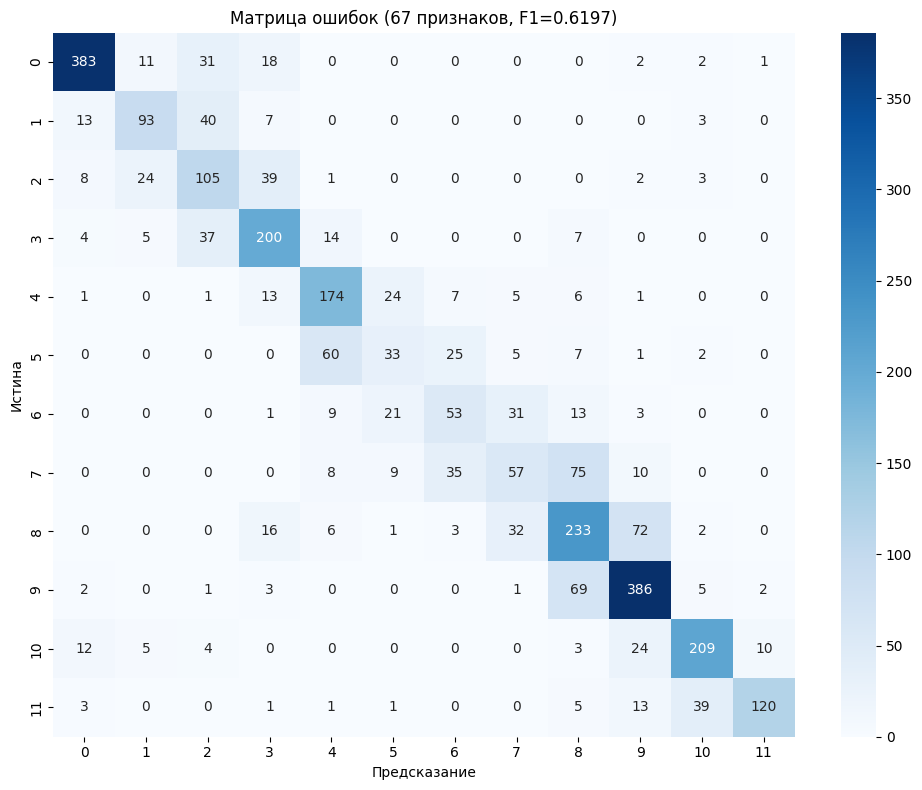

In [22]:
# Жёсткий отбор: только n_folds_useful >= 4
strict_features = perm_summary[perm_summary['n_folds_useful'] >= 4]['feature'].tolist()

print(f"Признаков до отбора: {len(features)}")
print(f"Признаков после жёсткого отбора (>= 4 фолдов): {len(strict_features)}")

# Перезапускаем кросс-валидацию на отобранных признаках
X = df[strict_features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_strict = []
all_preds_strict = []
all_true_strict = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]

    print(f"Fold {fold}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()

    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores_strict.append(f1_val)
    all_preds_strict.extend(y_pred)
    all_true_strict.extend(y_vl.values)

    print(f"  F1 macro (train): {f1_train:.4f}")
    print(f"  F1 macro (val):   {f1_val:.4f}")
    print(f"  Gap:              {gap:.4f}")

print(f"Результаты жёсткого отбора (>= 4 фолдов, {len(strict_features)} признаков)")
print(f"  Средний F1 macro: {np.mean(fold_scores_strict):.4f} ± {np.std(fold_scores_strict):.4f}")
print(f"\nСводный Classification Report:")
print(classification_report(all_true_strict, all_preds_strict, digits=4))

plt.figure(figsize=(10, 8))
cm_strict = confusion_matrix(all_true_strict, all_preds_strict)
sns.heatmap(cm_strict, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title(f'Матрица ошибок ({len(strict_features)} признаков, F1={np.mean(fold_scores_strict):.4f})')
plt.tight_layout()
plt.show()


In [23]:
strict_features

['Mo/Al',
 'Si/Al',
 'Sr/Ca',
 'Mn/Ca',
 'Mo',
 'Si',
 'P/Al',
 'dΔ_Si/Al',
 'dΔ_Fe/(Ca+Mg+Al)',
 'rΔ_Mo/(Mn+Mo)',
 'dΔ_Sr/Ca',
 'rΔ_Mo/Al',
 'Fe',
 'dΔ_Se/Ti',
 'rΔ_Ca',
 'dΔ_(Ti+Rb+Zr)/S',
 'Mn/Al',
 'dΔ_Mo/(Mn+Mo)',
 'dΔ_Ni/(Si+Ca+Mg)',
 'dΔ_Mn/Al',
 'P',
 'rΔ_(Al+K)/(Ca+Mg+Si)',
 'rΔ_Fe',
 'Cu',
 'Se',
 'Fe/S',
 'Mo/(Mn+Mo)',
 'Ni/S',
 'Ti',
 'Fe/(Ca+Mg+Al)',
 'Fe/(Mn+Fe)',
 'Ni/Al',
 'Ni',
 'Ca',
 'dΔ_Se',
 'Ni/Fe',
 'rΔ_Mn/Ca',
 'rΔ_Si/Al',
 'rΔ_Ni/S',
 'dΔ_Ni/Al',
 'S/(Rb+Zr)',
 'Zn',
 'dΔ_Zn',
 'rΔ_Fe/S',
 'dΔ_Mn',
 'dΔ_Al',
 'dΔ_Ni',
 'dΔ_Rb',
 'dΔ_K/Al',
 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000',
 'dΔ_Ca',
 'dΔ_Mn/Ca',
 'S/Ti',
 'dΔ_S',
 '(Al+K)/(Ca+Mg+Si)',
 'rΔ_K/Al',
 'rΔ_Ti',
 'rΔ_Mn/Al',
 'dΔ_Si',
 'rΔ_Ni/Fe',
 'rΔ_(Al+K+Ti)/S',
 'rΔ_Ni',
 'rΔ_Zn',
 'rΔ_Mg',
 'rΔ_K',
 'dΔ_Zr/Si',
 'dΔ_Fe/S']

**Построение корреляционной матрицы признаков**

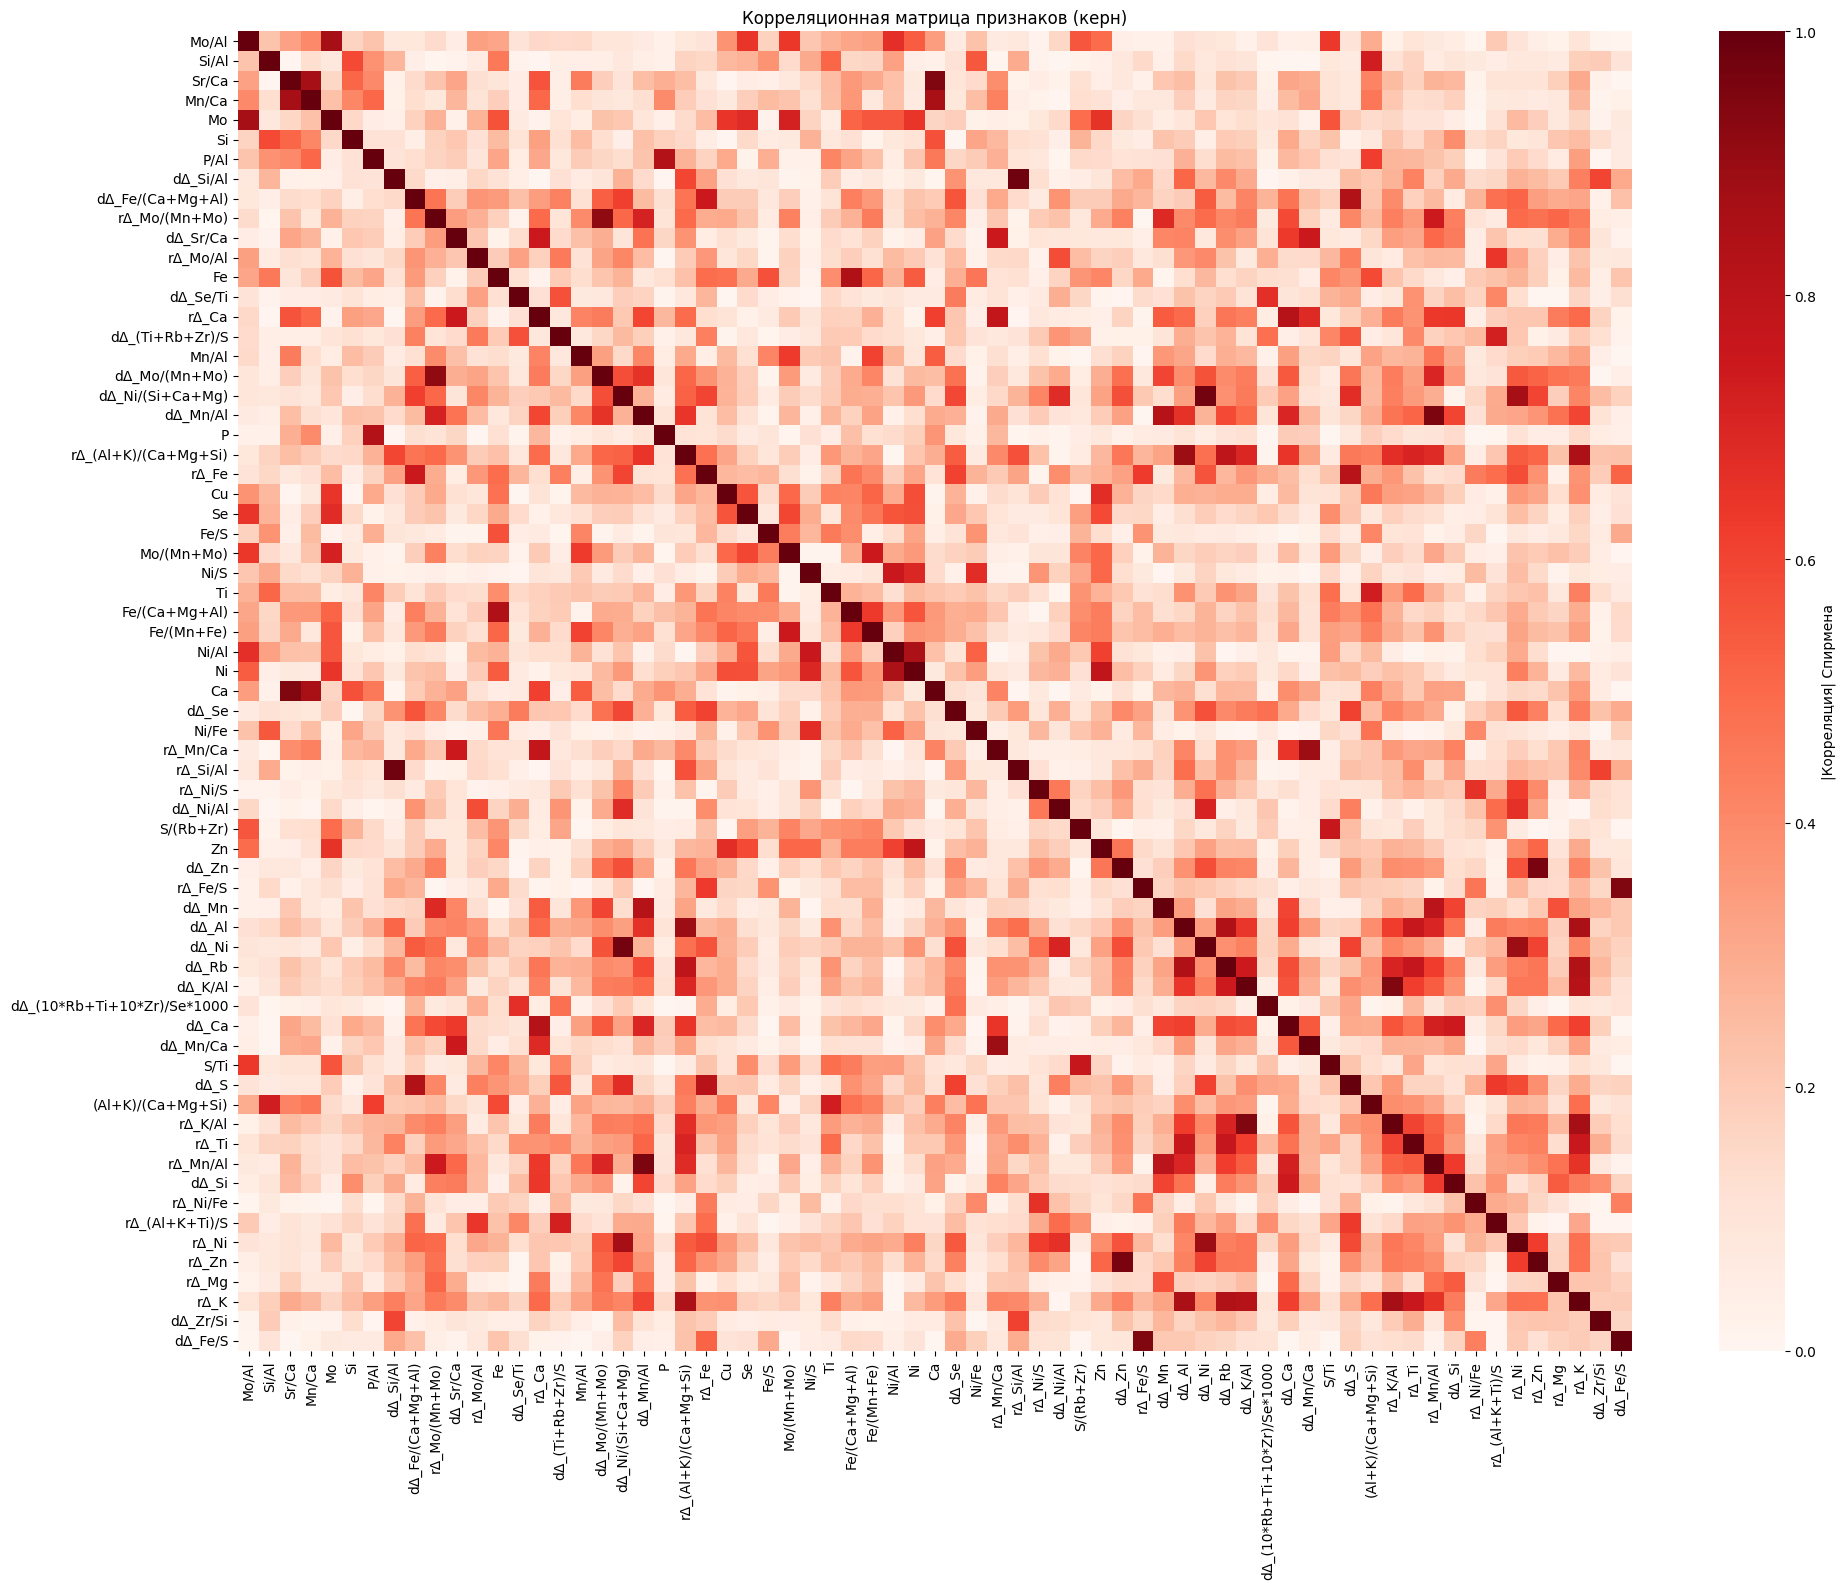

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Выбираем признаки (те, что прошли Permutation Importance)
features_to_check = perm_summary[perm_summary['n_folds_useful'] >= 4]['feature'].tolist()

# Корреляционная матрица (Спирмен — устойчив к выбросам)
corr_matrix = df[features_to_check].corr(method='spearman').abs()

# Визуализация
plt.figure(figsize=(20, 16))
sns.heatmap(corr_matrix, cmap='Reds', vmin=0, vmax=1,
            xticklabels=True, yticklabels=True,
            cbar_kws={'label': '|Корреляция| Спирмена'})
plt.title('Корреляционная матрица признаков (керн)')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=100)
plt.show()

**Viterbi-постобработка**

In [25]:
from collections import Counter

X = df[strict_features]
y = df['Strat']
groups = df['Well']

# Оценка transition matrix по тренировочным данным
def build_transition_matrix(y_train, wells_train, n_classes=12):
    """Считаем переходы между классами по глубине внутри каждой скважины"""
    trans = np.ones((n_classes, n_classes))  # Laplace smoothing
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    # Нормализуем строки
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans

# Оценка начальных распределений
def build_start_probs(y_train, wells_train, n_classes=12):
    """Какой класс чаще всего встречается первым в скважине"""
    start = np.ones(n_classes)  # Laplace
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

# Viterbi-декодирование для одной скважины
def viterbi_decode(probs_well, trans_mat, start_probs):
    """
    probs_well: (n_samples, n_classes) — вероятности от CatBoost
    Возвращает наиболее правдоподобную последовательность классов
    """
    n_samples, n_classes = probs_well.shape
    
    # Логарифмируем для численной устойчивости
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    # Viterbi: dp[t, j] = max вероятность пути, заканчивающегося в классе j на шаге t
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    
    # Инициализация
    dp[0] = log_start + log_emission[0]
    
    # Рекурсия
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    # Backtrack
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    
    return path

# Полный пайплайн с Viterbi
fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_raw = []
fold_scores_viterbi = []
all_preds_raw = []
all_preds_viterbi = []
all_true = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    wells_tr, wells_vl = groups.iloc[train_idx], groups.iloc[val_idx]
    
    # Обучаем CatBoost
    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
    
    # Сырые предсказания
    y_pred_raw = model.predict(X_vl).ravel()
    
    # Вероятности для Viterbi
    probs = model.predict_proba(X_vl)
    
    # Строим HMM по тренировочным данным
    trans_mat = build_transition_matrix(y_tr, wells_tr)
    start_probs = build_start_probs(y_tr, wells_tr)
    
    # Viterbi для каждой скважины отдельно
    y_pred_viterbi = np.zeros(len(y_vl), dtype=int)
    for well in wells_vl.unique():
        well_mask = (wells_vl == well).values
        if well_mask.sum() == 0:
            continue
        probs_well = probs[well_mask]
        path = viterbi_decode(probs_well, trans_mat, start_probs)
        y_pred_viterbi[well_mask] = path
    
    f1_raw = f1_score(y_vl, y_pred_raw, average='macro')
    f1_vit = f1_score(y_vl, y_pred_viterbi, average='macro')
    
    fold_scores_raw.append(f1_raw)
    fold_scores_viterbi.append(f1_vit)
    all_preds_raw.extend(y_pred_raw)
    all_preds_viterbi.extend(y_pred_viterbi)
    all_true.extend(y_vl.values)
    
    print(f"Fold {fold}: F1 raw={f1_raw:.4f} → F1 Viterbi={f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}%)")

print(f"Средний F1 raw:    {np.mean(fold_scores_raw):.4f} ± {np.std(fold_scores_raw):.4f}")
print(f"Средний F1 Viterbi: {np.mean(fold_scores_viterbi):.4f} ± {np.std(fold_scores_viterbi):.4f}")

print(f"\nClassification Report (Viterbi):")
print(classification_report(all_true, all_preds_viterbi, digits=4))


Fold 1: F1 raw=0.5556 → F1 Viterbi=0.6849 (+12.9%)
Fold 2: F1 raw=0.6949 → F1 Viterbi=0.7806 (+8.6%)
Fold 3: F1 raw=0.6637 → F1 Viterbi=0.7374 (+7.4%)
Fold 4: F1 raw=0.6436 → F1 Viterbi=0.6586 (+1.5%)
Fold 5: F1 raw=0.5476 → F1 Viterbi=0.5800 (+3.2%)
Средний F1 raw:    0.6211 ± 0.0591
Средний F1 Viterbi: 0.6883 ± 0.0686

Classification Report (Viterbi):
              precision    recall  f1-score   support

           0     0.9635    0.8839    0.9220       448
           1     0.8390    0.6346    0.7226       156
           2     0.5849    0.6813    0.6294       182
           3     0.7752    0.8914    0.8293       267
           4     0.7276    0.9440    0.8218       232
           5     0.4359    0.1278    0.1977       133
           6     0.5591    0.5420    0.5504       131
           7     0.5847    0.3557    0.4423       194
           8     0.6156    0.7808    0.6884       365
           9     0.8295    0.9126    0.8690       469
          10     0.7476    0.8876    0.8116      

**С оптимизированной матрицей переходов**

In [26]:
from collections import Counter
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, classification_report
from catboost import CatBoostClassifier

X = df[strict_features]
y = df['Strat']
groups = df['Well']

# Сбалансированная матрица переходов
def build_balanced_transition_matrix(n_classes=12,
                                      diag=0.85,
                                      neighbor=1.0,
                                      down_bias=0.5):
    """
    Сбалансированная матрица переходов для шлама.
    - diag: вероятность остаться в том же классе.
    - neighbor: базовая вероятность перехода к соседнему классу.
    - down_bias: доля "вниз" (0.5 = симметрично, >0.5 = приоритет вниз).
    """
    trans = np.zeros((n_classes, n_classes))
    
    for i in range(n_classes):
        trans[i, i] = diag
        if i > 0:
            trans[i, i-1] = neighbor * down_bias        # вниз
        if i < n_classes - 1:
            trans[i, i+1] = neighbor * (1 - down_bias)  # вверх
    
    # Нормализуем строки
    row_sums = trans.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    trans = trans / row_sums
    return trans

# Start probs
def build_start_probs(y_train, wells_train, n_classes=12):
    """Какой класс чаще всего встречается первым в скважине"""
    start = np.ones(n_classes)  # Laplace
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

# Viterbi
def viterbi_decode(probs_well, trans_mat, start_probs):
    """
    probs_well: (n_samples, n_classes) — вероятности от CatBoost
    Возвращает наиболее правдоподобную последовательность классов
    """
    n_samples, n_classes = probs_well.shape
    
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    
    dp[0] = log_start + log_emission[0]
    
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    
    return path

# Пайплайн с Viterbi
fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

# Параметры сбалансированной матрицы (лучшая комбинация)
BALANCED_DIAG = 0.85
BALANCED_NEIGHBOR = 1.0
BALANCED_DOWN_BIAS = 0.5

gkf = GroupKFold(n_splits=5)

fold_scores_raw = []
fold_scores_viterbi = []
all_preds_raw = []
all_preds_viterbi = []
all_true = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    wells_tr, wells_vl = groups.iloc[train_idx], groups.iloc[val_idx]
    
    # Обучаем CatBoost (без изменений)
    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
    
    # Сырые предсказания (без изменений)
    y_pred_raw = model.predict(X_vl).ravel()
    
    # Вероятности для Viterbi (без изменений)
    probs = model.predict_proba(X_vl)
    
    # === ИЗМЕНЕНИЕ: сбалансированная матрица вместо строгой ===
    trans_mat = build_balanced_transition_matrix(
        n_classes=12,
        diag=BALANCED_DIAG,
        neighbor=BALANCED_NEIGHBOR,
        down_bias=BALANCED_DOWN_BIAS
    )
    # Начальные вероятности по-прежнему строятся по керну
    start_probs = build_start_probs(y_tr, wells_tr)
    
    # Viterbi для каждой скважины отдельно (без изменений)
    y_pred_viterbi = np.zeros(len(y_vl), dtype=int)
    for well in wells_vl.unique():
        well_mask = (wells_vl == well).values
        if well_mask.sum() == 0:
            continue
        probs_well = probs[well_mask]
        path = viterbi_decode(probs_well, trans_mat, start_probs)
        y_pred_viterbi[well_mask] = path
    
    f1_raw = f1_score(y_vl, y_pred_raw, average='macro')
    f1_vit = f1_score(y_vl, y_pred_viterbi, average='macro')
    
    fold_scores_raw.append(f1_raw)
    fold_scores_viterbi.append(f1_vit)
    all_preds_raw.extend(y_pred_raw)
    all_preds_viterbi.extend(y_pred_viterbi)
    all_true.extend(y_vl.values)
    
    print(f"Fold {fold}: F1 raw={f1_raw:.4f} → F1 Viterbi={f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}%)")

print(f"\nСредний F1 raw:    {np.mean(fold_scores_raw):.4f} ± {np.std(fold_scores_raw):.4f}")
print(f"Средний F1 Viterbi: {np.mean(fold_scores_viterbi):.4f} ± {np.std(fold_scores_viterbi):.4f}")

print(f"\nClassification Report (Viterbi):")
print(classification_report(all_true, all_preds_viterbi, digits=4))

Fold 1: F1 raw=0.5556 → F1 Viterbi=0.6220 (+6.6%)
Fold 2: F1 raw=0.6949 → F1 Viterbi=0.7636 (+6.9%)
Fold 3: F1 raw=0.6565 → F1 Viterbi=0.6937 (+3.7%)
Fold 4: F1 raw=0.6436 → F1 Viterbi=0.6920 (+4.8%)
Fold 5: F1 raw=0.5476 → F1 Viterbi=0.6308 (+8.3%)

Средний F1 raw:    0.6197 ± 0.0581
Средний F1 Viterbi: 0.6804 ± 0.0512

Classification Report (Viterbi):
              precision    recall  f1-score   support

           0     0.9504    0.8549    0.9001       448
           1     0.7557    0.6346    0.6899       156
           2     0.5219    0.6538    0.5805       182
           3     0.7320    0.7978    0.7634       267
           4     0.7645    0.8534    0.8065       232
           5     0.5287    0.3459    0.4182       133
           6     0.4727    0.3969    0.4315       131
           7     0.4452    0.3351    0.3824       194
           8     0.6111    0.7233    0.6625       365
           9     0.7965    0.8763    0.8345       469
          10     0.8597    0.8951    0.8771      

**CV на интерполированном керне**

*Функция пересчета признаков*

In [27]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

In [28]:
def compute_features(df, elements, suffix=None):
    """
    Пересчитывает strict_features из колонок {el}_{suffix}.
    """
    df = df.copy()
    
    # Сырые элементы
    for el in elements:
        if suffix is None:
            # Без суффикса (керн)
            pass  # колонки уже есть
        else:
            # С суффиксом
            df[el] = df[f'{el}_{suffix}']
    
    # Соотношения (все, что есть в strict_features)
    df['Mo/Al'] = df['Mo'] / df['Al']
    df['Si/Al'] = df['Si'] / df['Al']
    df['Sr/Ca'] = df['Sr'] / df['Ca']
    df['Mn/Ca'] = df['Mn'] / df['Ca']
    df['P/Al'] = df['P'] / df['Al']
    df['Mn/Al'] = df['Mn'] / df['Al']
    df['Fe/S'] = df['Fe'] / df['S']
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'])
    df['Ni/S'] = df['Ni'] / df['S']
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'])
    df['Fe/(Mn+Fe)'] = df['Fe'] / (df['Mn'] + df['Fe'])
    df['Ni/Al'] = df['Ni'] / df['Al']
    df['Ni/Fe'] = df['Ni'] / df['Fe']
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'])
    df['S/Ti'] = df['S'] / df['Ti']
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'])
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'])
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / df['Se'] * 1000
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / df['S']
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'])
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'])
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / df['S']
    df['K/Al'] = df['K'] / df['Al']
    df['Zr/Si'] = df['Zr'] / df['Si']
    df['Se/Ti'] = df['Se'] / df['Ti']
    
    # dΔ и rΔ (по скважинам)
    d_delta_features = [f for f in strict_features if f.startswith('dΔ_')]
    r_delta_features = [f for f in strict_features if f.startswith('rΔ_')]
    
    for well in df['Well'].unique():
        mask = df['Well'] == well
        df_well = df[mask].sort_values('Depth').reset_index(drop=True)
        
        for feat in d_delta_features:
            base = feat.replace('dΔ_', '')
            if base in df_well.columns:
                df.loc[mask, feat] = df_well[base].diff().fillna(0).values
        
        for feat in r_delta_features:
            base = feat.replace('rΔ_', '')
            if base in df_well.columns:
                prev = df_well[base].shift(1)
                df.loc[mask, feat] = (df_well[base] / prev).fillna(1).values
    
    return df

In [29]:
# Загрузка интерполированного керна
df_kern = pd.read_csv("Data/data_kern_interpolated_0-05m_gap04.csv")

In [30]:
df_kern_feat = compute_features(df_kern, elements) 
df_kern_feat = df_kern_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_kern_feat['Strat'] = df_kern_feat['Strat'].astype(int)

Fold 1
  Train: 6647 проб, Val: 1466 проб
  F1 macro (train): 0.9965
  F1 macro (val):   0.5751
  Gap:              0.4213
Fold 2
  Train: 6502 проб, Val: 1611 проб
  F1 macro (train): 0.9968
  F1 macro (val):   0.7462
  Gap:              0.2506
Fold 3
  Train: 6419 проб, Val: 1694 проб
  F1 macro (train): 0.9960
  F1 macro (val):   0.6748
  Gap:              0.3213
Fold 4
  Train: 6446 проб, Val: 1667 проб
  F1 macro (train): 0.9969
  F1 macro (val):   0.5577
  Gap:              0.4392
Fold 5
  Train: 6438 проб, Val: 1675 проб
  F1 macro (train): 0.9959
  F1 macro (val):   0.6721
  Gap:              0.3238
  Средний F1 macro: 0.6452 ± 0.0698

Сводный Classification Report:
              precision    recall  f1-score   support

           0     0.9243    0.8856    0.9046      1268
           1     0.6849    0.5793    0.6277       454
           2     0.4779    0.5935    0.5295       492
           3     0.7201    0.7811    0.7493       731
           4     0.6961    0.7485    0.7214   

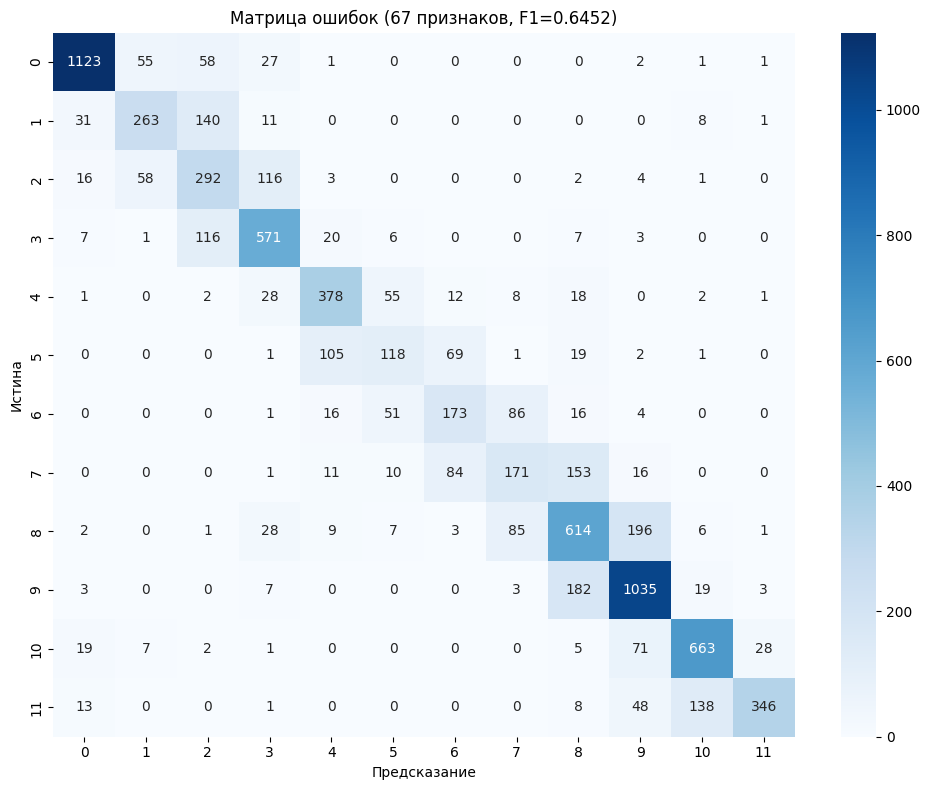

In [31]:
X = df_kern_feat[strict_features]
y = df_kern_feat['Strat']
groups = df_kern_feat['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_strict = []
all_preds_strict = []
all_true_strict = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]

    print(f"Fold {fold}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()

    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores_strict.append(f1_val)
    all_preds_strict.extend(y_pred)
    all_true_strict.extend(y_vl.values)

    print(f"  F1 macro (train): {f1_train:.4f}")
    print(f"  F1 macro (val):   {f1_val:.4f}")
    print(f"  Gap:              {gap:.4f}")

print(f"  Средний F1 macro: {np.mean(fold_scores_strict):.4f} ± {np.std(fold_scores_strict):.4f}")
print(f"\nСводный Classification Report:")
print(classification_report(all_true_strict, all_preds_strict, digits=4))

plt.figure(figsize=(10, 8))
cm_strict = confusion_matrix(all_true_strict, all_preds_strict)
sns.heatmap(cm_strict, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title(f'Матрица ошибок ({len(strict_features)} признаков, F1={np.mean(fold_scores_strict):.4f})')
plt.tight_layout()
plt.show()

**+Viterbi**

In [32]:
X = df_kern_feat[strict_features]
y = df_kern_feat['Strat']
groups = df_kern_feat['Well']

# Оценка transition matrix по тренировочным данным
def build_transition_matrix(y_train, wells_train, n_classes=12):
    """Считаем переходы между классами по глубине внутри каждой скважины"""
    trans = np.ones((n_classes, n_classes))  # Laplace smoothing
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    # Нормализуем строки
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans

# Оценка начальных распределений
def build_start_probs(y_train, wells_train, n_classes=12):
    """Какой класс чаще всего встречается первым в скважине"""
    start = np.ones(n_classes)  # Laplace
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

# Viterbi-декодирование для одной скважины
def viterbi_decode(probs_well, trans_mat, start_probs):
    """
    probs_well: (n_samples, n_classes) — вероятности от CatBoost
    Возвращает наиболее правдоподобную последовательность классов
    """
    n_samples, n_classes = probs_well.shape
    
    # Логарифмируем для численной устойчивости
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    # Viterbi: dp[t, j] = max вероятность пути, заканчивающегося в классе j на шаге t
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    
    # Инициализация
    dp[0] = log_start + log_emission[0]
    
    # Рекурсия
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    # Backtrack
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    
    return path

# Полный пайплайн с Viterbi
fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_raw = []
fold_scores_viterbi = []
all_preds_raw = []
all_preds_viterbi = []
all_true = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    wells_tr, wells_vl = groups.iloc[train_idx], groups.iloc[val_idx]
    
    # Обучаем CatBoost
    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
    
    # Сырые предсказания
    y_pred_raw = model.predict(X_vl).ravel()
    
    # Вероятности для Viterbi
    probs = model.predict_proba(X_vl)
    
    # Строим HMM по тренировочным данным
    trans_mat = build_transition_matrix(y_tr, wells_tr)
    start_probs = build_start_probs(y_tr, wells_tr)
    
    # Viterbi для каждой скважины отдельно
    y_pred_viterbi = np.zeros(len(y_vl), dtype=int)
    for well in wells_vl.unique():
        well_mask = (wells_vl == well).values
        if well_mask.sum() == 0:
            continue
        probs_well = probs[well_mask]
        path = viterbi_decode(probs_well, trans_mat, start_probs)
        y_pred_viterbi[well_mask] = path
    
    f1_raw = f1_score(y_vl, y_pred_raw, average='macro')
    f1_vit = f1_score(y_vl, y_pred_viterbi, average='macro')
    
    fold_scores_raw.append(f1_raw)
    fold_scores_viterbi.append(f1_vit)
    all_preds_raw.extend(y_pred_raw)
    all_preds_viterbi.extend(y_pred_viterbi)
    all_true.extend(y_vl.values)
    
    print(f"Fold {fold}: F1 raw={f1_raw:.4f} → F1 Viterbi={f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}%)")

print(f"Средний F1 raw:    {np.mean(fold_scores_raw):.4f} ± {np.std(fold_scores_raw):.4f}")
print(f"Средний F1 Viterbi: {np.mean(fold_scores_viterbi):.4f} ± {np.std(fold_scores_viterbi):.4f}")

print(f"\nClassification Report (Viterbi):")
print(classification_report(all_true, all_preds_viterbi, digits=4))

Fold 1: F1 raw=0.5751 → F1 Viterbi=0.6132 (+3.8%)
Fold 2: F1 raw=0.7462 → F1 Viterbi=0.8175 (+7.1%)
Fold 3: F1 raw=0.6748 → F1 Viterbi=0.7093 (+3.5%)
Fold 4: F1 raw=0.5577 → F1 Viterbi=0.5608 (+0.3%)
Fold 5: F1 raw=0.6721 → F1 Viterbi=0.7522 (+8.0%)
Средний F1 raw:    0.6452 ± 0.0698
Средний F1 Viterbi: 0.6906 ± 0.0928

Classification Report (Viterbi):
              precision    recall  f1-score   support

           0     0.9536    0.9235    0.9383      1268
           1     0.8077    0.6013    0.6894       454
           2     0.5069    0.6748    0.5789       492
           3     0.7853    0.8304    0.8072       731
           4     0.7337    0.8673    0.7949       505
           5     0.6290    0.3703    0.4661       316
           6     0.5510    0.5764    0.5634       347
           7     0.5556    0.4596    0.5031       446
           8     0.6909    0.6996    0.6952       952
           9     0.7853    0.8850    0.8321      1252
          10     0.7862    0.8731    0.8274       

**CatBoost обучается на керне (train-скважины), тестируется на синтетическом шламе (val-скважины)**

Сценарий: w=0.5 м, σ=0.0
  F1 raw:     0.6470 ± 0.0705
  F1 Viterbi: 0.6810 ± 0.0807
  Прирост:    +3.4 п.п.
Сценарий: w=0.5 м, σ=0.1
  F1 raw:     0.5393 ± 0.0798
  F1 Viterbi: 0.5774 ± 0.1078
  Прирост:    +3.8 п.п.
Сценарий: w=0.5 м, σ=0.3
  F1 raw:     0.4437 ± 0.0615
  F1 Viterbi: 0.4572 ± 0.0775
  Прирост:    +1.3 п.п.
Сценарий: w=0.5 м, σ=0.5
  F1 raw:     0.3851 ± 0.0534
  F1 Viterbi: 0.3976 ± 0.0845
  Прирост:    +1.3 п.п.
Сценарий: w=1.0 м, σ=0.0
  F1 raw:     0.6294 ± 0.0647
  F1 Viterbi: 0.6245 ± 0.0719
  Прирост:    -0.5 п.п.
Сценарий: w=1.0 м, σ=0.1
  F1 raw:     0.5365 ± 0.0634
  F1 Viterbi: 0.5541 ± 0.1078
  Прирост:    +1.8 п.п.
Сценарий: w=1.0 м, σ=0.3
  F1 raw:     0.4471 ± 0.0544
  F1 Viterbi: 0.4591 ± 0.0672
  Прирост:    +1.2 п.п.
Сценарий: w=1.0 м, σ=0.5
  F1 raw:     0.3928 ± 0.0505
  F1 Viterbi: 0.4066 ± 0.0787
  Прирост:    +1.4 п.п.
Сценарий: w=2.0 м, σ=0.0
  F1 raw:     0.5641 ± 0.0657
  F1 Viterbi: 0.5490 ± 0.0953
  Прирост:    -1.5 п.п.
Сценарий: w=2.0 м, 

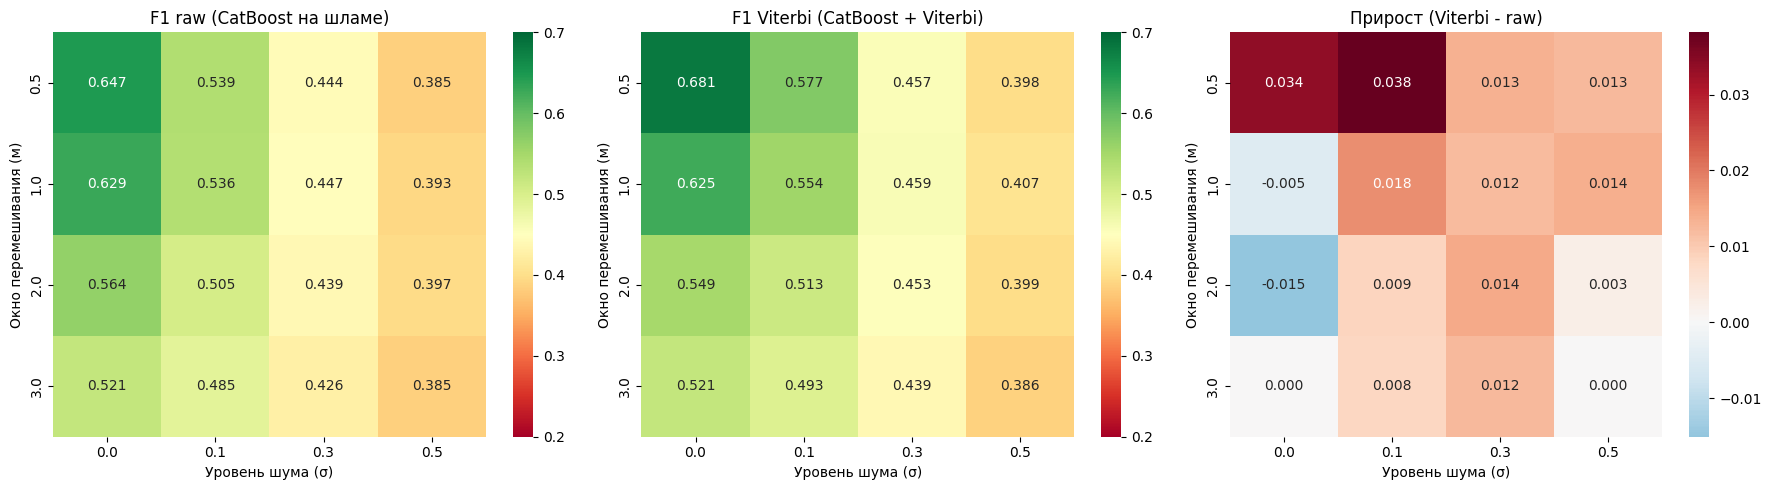

In [33]:
df_kern = pd.read_csv("Data/data_kern_interpolated_0-05m_gap04.csv")
df_kern_feat = compute_features(df_kern, elements)
df_kern_feat = df_kern_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_kern_feat['Strat'] = df_kern_feat['Strat'].astype(int)

# VITERBI (сглаженная матрица)
def build_transition_matrix(y_train, wells_train, n_classes=12):
    trans = np.ones((n_classes, n_classes))  # Laplace smoothing
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans

def build_start_probs(y_train, wells_train, n_classes=12):
    start = np.ones(n_classes)
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

def viterbi_decode(probs_well, trans_mat, start_probs):
    n_samples, n_classes = probs_well.shape
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    dp[0] = log_start + log_emission[0]
    
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    return path

# ГИПЕРПАРАМЕТРЫ
fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}

windows = [0.5, 1.0, 2.0, 3.0]
noise_levels = [0.0, 0.1, 0.3, 0.5]

# Фиксированное разбиение по скважинам (5 фолдов)
gkf = GroupKFold(n_splits=5)
folds = list(gkf.split(df_kern_feat, groups=df_kern_feat['Well']))

all_results = []

for window_m in windows:
    for noise_level in noise_levels:
        # Определяем суффикс для имени файла
        suffix = 'no_noise' if noise_level == 0.0 else f's{noise_level}'
        
        print(f"Сценарий: w={window_m} м, σ={noise_level}")
        
        # Загрузка шлама для ЭТОГО сценария
        if noise_level == 0.0:
            df_slag = pd.read_csv(f"Result/Synthetic_slag_06_11/synthetic_slag_w{window_m}_no_noise.csv")
        else:
            df_slag = pd.read_csv(f"Result/Synthetic_slag_06_11/synthetic_slag_w{window_m}_s{noise_level}.csv")
        
        # Признаки для шлама
        df_slag_feat = compute_features(df_slag, elements, suffix='slag')
        df_slag_feat = df_slag_feat.dropna(subset=['Strat']).reset_index(drop=True)
        df_slag_feat['Strat'] = df_slag_feat['Strat'].astype(int)
        
        # 5-фолдовая CV
        fold_scores_raw = []
        fold_scores_viterbi = []
        
        for fold, (train_idx, val_idx) in enumerate(folds, 1):
            train_wells = df_kern_feat.iloc[train_idx]['Well'].unique()
            val_wells = df_kern_feat.iloc[val_idx]['Well'].unique()
            
            # Train: КЕРН (train-скважины)
            df_train = df_kern_feat[df_kern_feat['Well'].isin(train_wells)]
            X_tr = df_train[strict_features]
            y_tr = df_train['Strat']
            wells_tr = df_train['Well']
            
            # Val: ШЛАМ (val-скважины)
            df_val = df_slag_feat[df_slag_feat['Well'].isin(val_wells)]
            X_vl = df_val[strict_features]
            y_vl = df_val['Strat']
            wells_vl = df_val['Well']
            
            # Обучение CatBoost на КЕРНЕ
            model = CatBoostClassifier(**fixed_params)
            model.fit(X_tr, y_tr)
            
            # Сырые предсказания
            y_pred_raw = model.predict(X_vl).ravel()
            f1_raw = f1_score(y_vl, y_pred_raw, average='macro')
            
            # Viterbi
            probs = model.predict_proba(X_vl)
            trans_mat = build_transition_matrix(y_tr, wells_tr)
            start_probs = build_start_probs(y_tr, wells_tr)
            
            y_pred_vit = np.zeros(len(y_vl), dtype=int)
            for well in wells_vl.unique():
                mask = (wells_vl == well).values
                if mask.sum() == 0:
                    continue
                y_pred_vit[mask] = viterbi_decode(probs[mask], trans_mat, start_probs)
            
            f1_vit = f1_score(y_vl, y_pred_vit, average='macro')
            
            fold_scores_raw.append(f1_raw)
            fold_scores_viterbi.append(f1_vit)
        
        # Средние по фолдам
        mean_raw = np.mean(fold_scores_raw)
        std_raw = np.std(fold_scores_raw)
        mean_vit = np.mean(fold_scores_viterbi)
        std_vit = np.std(fold_scores_viterbi)
        
        print(f"  F1 raw:     {mean_raw:.4f} ± {std_raw:.4f}")
        print(f"  F1 Viterbi: {mean_vit:.4f} ± {std_vit:.4f}")
        print(f"  Прирост:    {(mean_vit - mean_raw)*100:+.1f} п.п.")
        
        # Сохранение
        all_results.append({
            'window': window_m,
            'noise': noise_level,
            'f1_raw_mean': mean_raw,
            'f1_raw_std': std_raw,
            'f1_vit_mean': mean_vit,
            'f1_vit_std': std_vit,
            'improvement': mean_vit - mean_raw,
        })

# ИТОГОВАЯ ТАБЛИЦА
df_results = pd.DataFrame(all_results)
df_results.to_csv('Result/CatBoost_slag_5fold_all_scenarios.csv', index=False)

print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ (CatBoost на керне → тест на шламе)")

# Pivot: F1 raw
pivot_raw = df_results.pivot_table(index='window', columns='noise', values='f1_raw_mean').round(4)
print("\nF1 raw (среднее по 5 фолдам):")
print(pivot_raw)

# Pivot: F1 Viterbi
pivot_vit = df_results.pivot_table(index='window', columns='noise', values='f1_vit_mean').round(4)
print("\nF1 Viterbi (среднее по 5 фолдам):")
print(pivot_vit)

# Pivot: прирост
pivot_imp = df_results.pivot_table(index='window', columns='noise', values='improvement').round(4)
print("\nПрирост (Viterbi - raw):")
print(pivot_imp)

# ВИЗУАЛИЗАЦИЯ (тепловые карты)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# F1 raw
sns.heatmap(pivot_raw, annot=True, fmt='.3f', cmap='RdYlGn', ax=axes[0], vmin=0.2, vmax=0.7)
axes[0].set_title('F1 raw (CatBoost на шламе)')
axes[0].set_xlabel('Уровень шума (σ)')
axes[0].set_ylabel('Окно перемешивания (м)')

# F1 Viterbi
sns.heatmap(pivot_vit, annot=True, fmt='.3f', cmap='RdYlGn', ax=axes[1], vmin=0.2, vmax=0.7)
axes[1].set_title('F1 Viterbi (CatBoost + Viterbi)')
axes[1].set_xlabel('Уровень шума (σ)')
axes[1].set_ylabel('Окно перемешивания (м)')

# Прирост
sns.heatmap(pivot_imp, annot=True, fmt='.3f', cmap='RdBu_r', ax=axes[2], center=0)
axes[2].set_title('Прирост (Viterbi - raw)')
axes[2].set_xlabel('Уровень шума (σ)')
axes[2].set_ylabel('Окно перемешивания (м)')

plt.tight_layout()
plt.savefig('Result/CatBoost_slag_5fold_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

**CatBoost обучается на реальном шламе (train-скважины), тестируется на реальном шламе (val-скважины)**

Реальный шлам: 8644 проб
Скважины: ['A10_slag', 'A1_slag', 'A2_slag', 'A3_slag', 'A4_slag', 'A5_slag', 'A6_slag', 'A7_slag', 'A8_slag', 'A9_slag', 'B1_slag', 'B2_slag', 'C1_slag', 'C2_slag', 'C3_slag', 'C4_slag', 'C5_slag', 'C6_slag', 'C7_slag', 'C8_slag', 'C9_slag']
Все strict_features вычислены.

Fold 1: train=['A10_slag', 'A1_slag', 'A2_slag', 'A3_slag', 'A5_slag', 'A6_slag', 'A7_slag', 'A9_slag', 'B1_slag', 'B2_slag', 'C1_slag', 'C2_slag', 'C3_slag', 'C4_slag', 'C5_slag', 'C6_slag'], val=['A4_slag', 'A8_slag', 'C7_slag', 'C8_slag', 'C9_slag']
  Train: 6612 проб, Val: 2032 проб
  F1 raw=0.7439, F1 Viterbi=0.7553 (+1.1%)

  Classification Report (Fold 1, RAW):
              precision    recall  f1-score   support

           2     1.0000    0.7059    0.8276        17
           3     0.9577    0.9867    0.9720       826
           4     0.8495    0.9093    0.8784       540
           5     0.4324    0.1455    0.2177       110
           6     0.5814    0.5435    0.5618        46
    

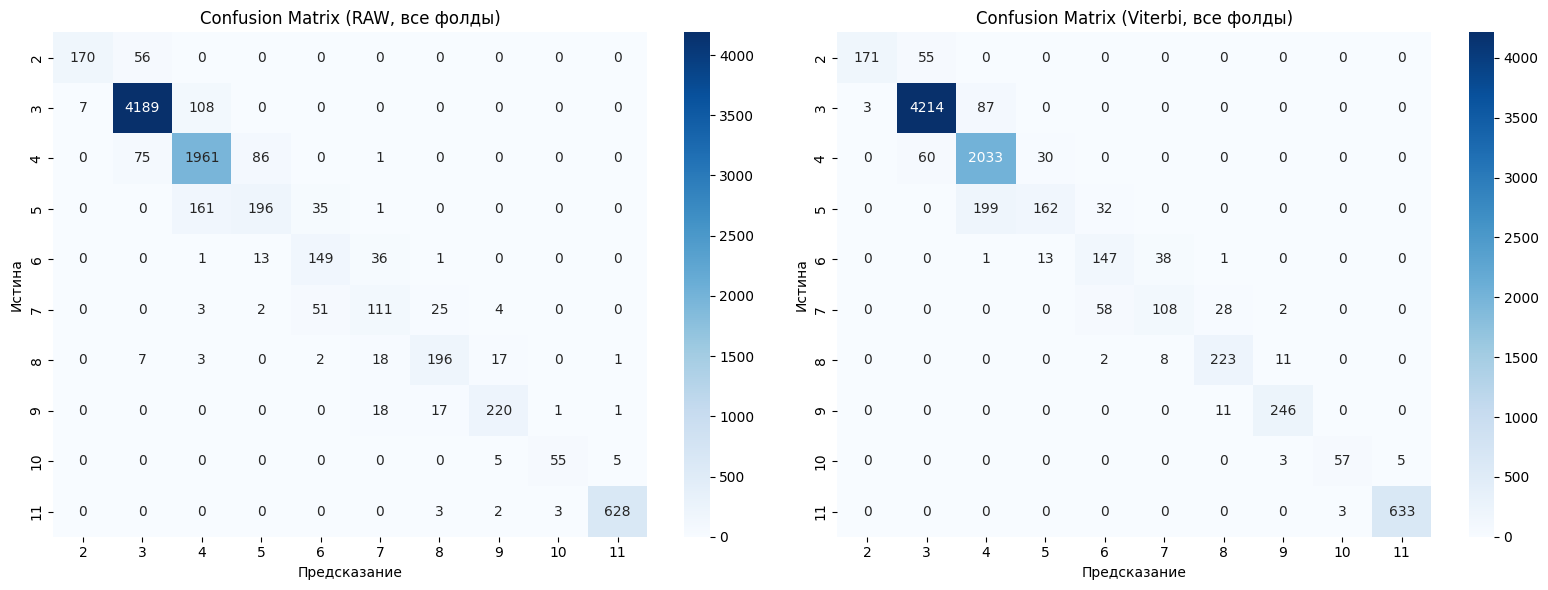

In [34]:
df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})

print(f"Реальный шлам: {len(df_real)} проб")
print(f"Скважины: {sorted(df_real['Well'].unique())}")

# ПРИЗНАКИ
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

strict_features = ['Mo/Al', 'Si/Al', 'Sr/Ca', 'Mn/Ca', 'Mo', 'Si', 'P/Al',
                   'dΔ_Si/Al', 'dΔ_Fe/(Ca+Mg+Al)', 'rΔ_Mo/(Mn+Mo)', 'dΔ_Sr/Ca',
                   'rΔ_Mo/Al', 'Fe', 'dΔ_Se/Ti', 'rΔ_Ca', 'dΔ_(Ti+Rb+Zr)/S',
                   'Mn/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Mn/Al',
                   'P', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Fe', 'Cu', 'Se', 'Fe/S',
                   'Mo/(Mn+Mo)', 'Ni/S', 'Ti', 'Fe/(Ca+Mg+Al)', 'Fe/(Mn+Fe)',
                   'Ni/Al', 'Ni', 'Ca', 'dΔ_Se', 'Ni/Fe', 'rΔ_Mn/Ca',
                   'rΔ_Si/Al', 'rΔ_Ni/S', 'dΔ_Ni/Al', 'S/(Rb+Zr)', 'Zn',
                   'dΔ_Zn', 'rΔ_Fe/S', 'dΔ_Mn', 'dΔ_Al', 'dΔ_Ni', 'dΔ_Rb',
                   'dΔ_K/Al', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Ca',
                   'dΔ_Mn/Ca', 'S/Ti', 'dΔ_S', '(Al+K)/(Ca+Mg+Si)',
                   'rΔ_K/Al', 'rΔ_Ti', 'rΔ_Mn/Al', 'dΔ_Si', 'rΔ_Ni/Fe',
                   'rΔ_(Al+K+Ti)/S', 'rΔ_Ni', 'rΔ_Zn', 'rΔ_Mg', 'rΔ_K',
                   'dΔ_Zr/Si', 'dΔ_Fe/S']

df_real_feat = compute_features(df_real, elements, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

missing = [f for f in strict_features if f not in df_real_feat.columns]
if missing:
    print(f"ВНИМАНИЕ: не вычислены признаки: {missing}")
else:
    print("Все strict_features вычислены.")

# VITERBI
def build_transition_matrix(y_train, wells_train, n_classes=12):
    trans = np.ones((n_classes, n_classes))
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans

def build_start_probs(y_train, wells_train, n_classes=12):
    start = np.ones(n_classes)
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

def viterbi_decode(probs_well, trans_mat, start_probs):
    n_samples, n_classes_probs = probs_well.shape
    n_classes = trans_mat.shape[0]
    
    if n_classes_probs < n_classes:
        probs_full = np.zeros((n_samples, n_classes))
        probs_full[:, :n_classes_probs] = probs_well
        probs_well = probs_full
    elif n_classes_probs > n_classes:
        probs_well = probs_well[:, :n_classes]
    
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    dp[0] = log_start + log_emission[0]
    
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    return path

# ГИПЕРПАРАМЕТРЫ
fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}


# 5-ФОЛДОВАЯ CV НА РЕАЛЬНОМ ШЛАМЕ

gkf = GroupKFold(n_splits=5)

fold_scores_raw = []
fold_scores_viterbi = []

# Для сводных отчётов и матриц по всем фолдам
all_true = []
all_pred_raw = []
all_pred_vit = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(df_real_feat, groups=df_real_feat['Well']), 1):
    train_wells = df_real_feat.iloc[train_idx]['Well'].unique()
    val_wells = df_real_feat.iloc[val_idx]['Well'].unique()
    
    print(f"\n{'='*60}")
    print(f"Fold {fold}: train={sorted(train_wells)}, val={sorted(val_wells)}")
    
    df_train = df_real_feat[df_real_feat['Well'].isin(train_wells)]
    X_tr = df_train[strict_features]
    y_tr = df_train['Strat']
    wells_tr = df_train['Well']
    
    df_val = df_real_feat[df_real_feat['Well'].isin(val_wells)]
    X_vl = df_val[strict_features]
    y_vl = df_val['Strat']
    wells_vl = df_val['Well']
    
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")
    
    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
    
    # RAW
    y_pred_raw = model.predict(X_vl).ravel()
    f1_raw = f1_score(y_vl, y_pred_raw, average='macro')
    
    # Viterbi
    probs = model.predict_proba(X_vl)
    n_classes = 12
    probs_full = np.zeros((len(y_vl), n_classes))
    for i, cls in enumerate(model.classes_):
        probs_full[:, int(cls)] = probs[:, i]
    probs = probs_full
    
    trans_mat = build_transition_matrix(y_tr, wells_tr)
    start_probs = build_start_probs(y_tr, wells_tr)
    
    y_pred_vit = np.zeros(len(y_vl), dtype=int)
    for well in wells_vl.unique():
        mask = (wells_vl == well).values
        if mask.sum() == 0:
            continue
        y_pred_vit[mask] = viterbi_decode(probs[mask], trans_mat, start_probs)
    
    f1_vit = f1_score(y_vl, y_pred_vit, average='macro')
    
    fold_scores_raw.append(f1_raw)
    fold_scores_viterbi.append(f1_vit)
    
    all_true.extend(y_vl.values)
    all_pred_raw.extend(y_pred_raw)
    all_pred_vit.extend(y_pred_vit)
    
    print(f"  F1 raw={f1_raw:.4f}, F1 Viterbi={f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}%)")
    
    # Classification Report по фолду (raw)
    print(f"\n  Classification Report (Fold {fold}, RAW):")
    print(classification_report(y_vl, y_pred_raw, digits=4, zero_division=0))
    
    # Classification Report по фолду (Viterbi)
    print(f"\n  Classification Report (Fold {fold}, Viterbi):")
    print(classification_report(y_vl, y_pred_vit, digits=4, zero_division=0))

print(f"Средний F1 raw: {np.mean(fold_scores_raw):.4f} ± {np.std(fold_scores_raw):.4f}")
print(f"Средний F1 Viterbi: {np.mean(fold_scores_viterbi):.4f} ± {np.std(fold_scores_viterbi):.4f}")

# СВОДНЫЙ CLASSIFICATION REPORT (ВСЕ ФОЛДЫ)
present_classes = np.unique(all_true)

print("СВОДНЫЙ CLASSIFICATION REPORT (все фолды, RAW)")

print(classification_report(all_true, all_pred_raw, labels=present_classes, digits=4, zero_division=0))

print("СВОДНЫЙ CLASSIFICATION REPORT (все фолды, Viterbi)")
print(classification_report(all_true, all_pred_vit, labels=present_classes, digits=4, zero_division=0))

# CONFUSION MATRIX (ВСЕ ФОЛДЫ)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_raw = confusion_matrix(all_true, all_pred_raw, labels=present_classes)
sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=present_classes, yticklabels=present_classes)
axes[0].set_title('Confusion Matrix (RAW, все фолды)')
axes[0].set_xlabel('Предсказание')
axes[0].set_ylabel('Истина')

cm_vit = confusion_matrix(all_true, all_pred_vit, labels=present_classes)
sns.heatmap(cm_vit, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=present_classes, yticklabels=present_classes)
axes[1].set_title('Confusion Matrix (Viterbi, все фолды)')
axes[1].set_xlabel('Предсказание')
axes[1].set_ylabel('Истина')

plt.tight_layout()
plt.savefig('Result/CatBoost_real_slag_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

**CatBoost обучается на керне (train-скважины), тестируется на реальном шламе (val-скважины)**

In [35]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

df_kern = pd.read_csv("Data/data_kern_interpolated_0-05m_gap04.csv")
df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})

df_real['Well'] = df_real['Well'].astype(str) + '_slag'

print(f"Керн: {len(df_kern)} проб")
print(f"Реальный шлам: {len(df_real)} проб")

strict_features = ['Mo/Al', 'Si/Al', 'Sr/Ca', 'Mn/Ca', 'Mo', 'Si', 'P/Al',
                   'dΔ_Si/Al', 'dΔ_Fe/(Ca+Mg+Al)', 'rΔ_Mo/(Mn+Mo)', 'dΔ_Sr/Ca',
                   'rΔ_Mo/Al', 'Fe', 'dΔ_Se/Ti', 'rΔ_Ca', 'dΔ_(Ti+Rb+Zr)/S',
                   'Mn/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Mn/Al',
                   'P', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Fe', 'Cu', 'Se', 'Fe/S',
                   'Mo/(Mn+Mo)', 'Ni/S', 'Ti', 'Fe/(Ca+Mg+Al)', 'Fe/(Mn+Fe)',
                   'Ni/Al', 'Ni', 'Ca', 'dΔ_Se', 'Ni/Fe', 'rΔ_Mn/Ca',
                   'rΔ_Si/Al', 'rΔ_Ni/S', 'dΔ_Ni/Al', 'S/(Rb+Zr)', 'Zn',
                   'dΔ_Zn', 'rΔ_Fe/S', 'dΔ_Mn', 'dΔ_Al', 'dΔ_Ni', 'dΔ_Rb',
                   'dΔ_K/Al', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Ca',
                   'dΔ_Mn/Ca', 'S/Ti', 'dΔ_S', '(Al+K)/(Ca+Mg+Si)',
                   'rΔ_K/Al', 'rΔ_Ti', 'rΔ_Mn/Al', 'dΔ_Si', 'rΔ_Ni/Fe',
                   'rΔ_(Al+K+Ti)/S', 'rΔ_Ni', 'rΔ_Zn', 'rΔ_Mg', 'rΔ_K',
                   'dΔ_Zr/Si', 'dΔ_Fe/S']

# Керн
df_kern_feat = compute_features(df_kern, elements, suffix=None)
df_kern_feat = df_kern_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_kern_feat['Strat'] = df_kern_feat['Strat'].astype(int)
df_kern_feat = df_kern_feat.dropna(subset=elements, how='all').reset_index(drop=True)

# Реальный шлам
df_real_feat = compute_features(df_real, elements, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

print(f"Керн (после удаления маркеров разрывов): {len(df_kern_feat)} проб")
print(f"Реальный шлам: {len(df_real_feat)} проб")

# VITERBI

def build_transition_matrix(y_train, wells_train, n_classes=12):
    trans = np.ones((n_classes, n_classes))
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans

def build_start_probs(y_train, wells_train, n_classes=12):
    start = np.ones(n_classes)
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

def viterbi_decode(probs_well, trans_mat, start_probs):
    n_samples, n_classes_probs = probs_well.shape
    n_classes = trans_mat.shape[0]
    
    if n_classes_probs < n_classes:
        probs_full = np.zeros((n_samples, n_classes))
        probs_full[:, :n_classes_probs] = probs_well
        probs_well = probs_full
    elif n_classes_probs > n_classes:
        probs_well = probs_well[:, :n_classes]
    
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    dp[0] = log_start + log_emission[0]
    
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    return path

# ГИПЕРПАРАМЕТРЫ
fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}


# ОБУЧЕНИЕ НА ВСЁМ КЕРНЕ, ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ
print("ОБУЧЕНИЕ НА ВСЁМ КЕРНЕ → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ")

X_tr = df_kern_feat[strict_features]
y_tr = df_kern_feat['Strat']
wells_tr = df_kern_feat['Well']

X_vl = df_real_feat[strict_features]
y_vl = df_real_feat['Strat']
wells_vl = df_real_feat['Well']

print(f"Train (керн): {len(X_tr)} проб")
print(f"Test (реальный шлам): {len(X_vl)} проб")

# Классы, которые реально есть в реальном шламе
present_classes = np.unique(y_vl)
print(f"Присутствующие классы в шламе: {present_classes}")

# Обучение CatBoost
model = CatBoostClassifier(**fixed_params)
model.fit(X_tr, y_tr)

# RAW (без Viterbi)
y_pred_raw = model.predict(X_vl).ravel()
f1_raw = f1_score(y_vl, y_pred_raw, average='macro', labels=present_classes)


print("RAW (без Viterbi)")

print(f"F1 macro (только присутствующие классы): {f1_raw:.4f}")
print(f"\nClassification Report (RAW):")
print(classification_report(y_vl, y_pred_raw, labels=present_classes, digits=4))

# VITERBI

probs = model.predict_proba(X_vl)
n_classes = 12
probs_full = np.zeros((len(y_vl), n_classes))
for i, cls in enumerate(model.classes_):
    probs_full[:, int(cls)] = probs[:, i]
probs = probs_full

trans_mat = build_transition_matrix(y_tr, wells_tr)
start_probs = build_start_probs(y_tr, wells_tr)

y_pred_vit = np.zeros(len(y_vl), dtype=int)
for well in wells_vl.unique():
    mask = (wells_vl == well).values
    if mask.sum() == 0:
        continue
    y_pred_vit[mask] = viterbi_decode(probs[mask], trans_mat, start_probs)

f1_vit = f1_score(y_vl, y_pred_vit, average='macro', labels=present_classes)

print("VITERBI")
print(f"F1 macro (только присутствующие классы): {f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}% к RAW)")
print(f"\nClassification Report (Viterbi):")
print(classification_report(y_vl, y_pred_vit, labels=present_classes, digits=4))

Керн: 8183 проб
Реальный шлам: 8644 проб
Керн (после удаления маркеров разрывов): 8111 проб
Реальный шлам: 8644 проб
ОБУЧЕНИЕ НА ВСЁМ КЕРНЕ → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ
Train (керн): 8111 проб
Test (реальный шлам): 8644 проб
Присутствующие классы в шламе: [ 2  3  4  5  6  7  8  9 10 11]
RAW (без Viterbi)
F1 macro (только присутствующие классы): 0.5110

Classification Report (RAW):
              precision    recall  f1-score   support

           2     1.0000    0.0796    0.1475       226
           3     0.9378    0.9638    0.9506      4304
           4     0.8186    0.9077    0.8608      2123
           5     0.5216    0.3079    0.3872       393
           6     0.7568    0.1400    0.2363       200
           7     0.3506    0.4490    0.3937       196
           8     0.4686    0.8566    0.6058       244
           9     0.8087    0.5759    0.6727       257
          10     0.3448    0.7692    0.4762        65
          11     0.9437    0.2374    0.3794       636

   micro avg     0.8350 

/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

**+строгая матрица Витерби**

In [36]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, classification_report

elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

df_kern = pd.read_csv("Data/data_kern_interpolated_0-05m_gap04.csv")
df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})

df_real['Well'] = df_real['Well'].astype(str) + '_slag'

print(f"Керн: {len(df_kern)} проб")
print(f"Реальный шлам: {len(df_real)} проб")

strict_features = ['Mo/Al', 'Si/Al', 'Sr/Ca', 'Mn/Ca', 'Mo', 'Si', 'P/Al',
                   'dΔ_Si/Al', 'dΔ_Fe/(Ca+Mg+Al)', 'rΔ_Mo/(Mn+Mo)', 'dΔ_Sr/Ca',
                   'rΔ_Mo/Al', 'Fe', 'dΔ_Se/Ti', 'rΔ_Ca', 'dΔ_(Ti+Rb+Zr)/S',
                   'Mn/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Mn/Al',
                   'P', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Fe', 'Cu', 'Se', 'Fe/S',
                   'Mo/(Mn+Mo)', 'Ni/S', 'Ti', 'Fe/(Ca+Mg+Al)', 'Fe/(Mn+Fe)',
                   'Ni/Al', 'Ni', 'Ca', 'dΔ_Se', 'Ni/Fe', 'rΔ_Mn/Ca',
                   'rΔ_Si/Al', 'rΔ_Ni/S', 'dΔ_Ni/Al', 'S/(Rb+Zr)', 'Zn',
                   'dΔ_Zn', 'rΔ_Fe/S', 'dΔ_Mn', 'dΔ_Al', 'dΔ_Ni', 'dΔ_Rb',
                   'dΔ_K/Al', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Ca',
                   'dΔ_Mn/Ca', 'S/Ti', 'dΔ_S', '(Al+K)/(Ca+Mg+Si)',
                   'rΔ_K/Al', 'rΔ_Ti', 'rΔ_Mn/Al', 'dΔ_Si', 'rΔ_Ni/Fe',
                   'rΔ_(Al+K+Ti)/S', 'rΔ_Ni', 'rΔ_Zn', 'rΔ_Mg', 'rΔ_K',
                   'dΔ_Zr/Si', 'dΔ_Fe/S']

# Керн
df_kern_feat = compute_features(df_kern, elements, suffix=None)
df_kern_feat = df_kern_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_kern_feat['Strat'] = df_kern_feat['Strat'].astype(int)
df_kern_feat = df_kern_feat.dropna(subset=elements, how='all').reset_index(drop=True)

# Реальный шлам
df_real_feat = compute_features(df_real, elements, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

print(f"Керн (после удаления маркеров разрывов): {len(df_kern_feat)} проб")
print(f"Реальный шлам: {len(df_real_feat)} проб")


# Строгая матрица переходов 12x12
strict_transition_matrix = np.zeros((12, 12))
strict_transition_matrix[0, 0] = 0.6296
strict_transition_matrix[0, 1] = 0.3704
for i in range(1, 11):
    strict_transition_matrix[i, i-1] = 0.2703
    strict_transition_matrix[i, i] = 0.4595
    strict_transition_matrix[i, i+1] = 0.2703
strict_transition_matrix[11, 10] = 0.3704
strict_transition_matrix[11, 11] = 0.6296

def viterbi_decode(probs_well, trans_mat, start_probs):
    n_samples, n_classes_probs = probs_well.shape
    n_classes = trans_mat.shape[0]
    
    if n_classes_probs < n_classes:
        probs_full = np.zeros((n_samples, n_classes))
        probs_full[:, :n_classes_probs] = probs_well
        probs_well = probs_full
    elif n_classes_probs > n_classes:
        probs_well = probs_well[:, :n_classes]
    
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    dp[0] = log_start + log_emission[0]
    
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    return path

# ГИПЕРПАРАМЕТРЫ
fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}


print("ОБУЧЕНИЕ НА ВСЁМ КЕРНЕ → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ")

X_tr = df_kern_feat[strict_features]
y_tr = df_kern_feat['Strat']
wells_tr = df_kern_feat['Well']

X_vl = df_real_feat[strict_features]
y_vl = df_real_feat['Strat']
wells_vl = df_real_feat['Well']

print(f"Train (керн): {len(X_tr)} проб")
print(f"Test (реальный шлам): {len(X_vl)} проб")

present_classes = np.unique(y_vl)
print(f"Присутствующие классы в шламе: {present_classes}")

model = CatBoostClassifier(**fixed_params)
model.fit(X_tr, y_tr)

# RAW (без Viterbi)
y_pred_raw = model.predict(X_vl).ravel()
f1_raw = f1_score(y_vl, y_pred_raw, average='macro', labels=present_classes)

print("\nRAW (без Viterbi)")
print(f"F1 macro: {f1_raw:.4f}")
print(f"\nClassification Report (RAW):")
print(classification_report(y_vl, y_pred_raw, labels=present_classes, digits=4))

# VITERBI
probs = model.predict_proba(X_vl)
n_classes = 12
probs_full = np.zeros((len(y_vl), n_classes))
for i, cls in enumerate(model.classes_):
    probs_full[:, int(cls)] = probs[:, i]
probs = probs_full

# Используем строгую матрицу и равномерные стартовые вероятности
start_probs = np.ones(12) / 12

y_pred_vit = np.zeros(len(y_vl), dtype=int)
for well in wells_vl.unique():
    mask = (wells_vl == well).values
    if mask.sum() == 0:
        continue
    y_pred_vit[mask] = viterbi_decode(probs[mask], strict_transition_matrix, start_probs)

f1_vit = f1_score(y_vl, y_pred_vit, average='macro', labels=present_classes)

print("\nVITERBI (строгая матрица)")
print(f"F1 macro: {f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}% к RAW)")
print(f"\nClassification Report (Viterbi):")
print(classification_report(y_vl, y_pred_vit, labels=present_classes, digits=4))

Керн: 8183 проб
Реальный шлам: 8644 проб
Керн (после удаления маркеров разрывов): 8111 проб
Реальный шлам: 8644 проб
ОБУЧЕНИЕ НА ВСЁМ КЕРНЕ → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ
Train (керн): 8111 проб
Test (реальный шлам): 8644 проб
Присутствующие классы в шламе: [ 2  3  4  5  6  7  8  9 10 11]

RAW (без Viterbi)
F1 macro: 0.5110

Classification Report (RAW):
              precision    recall  f1-score   support

           2     1.0000    0.0796    0.1475       226
           3     0.9378    0.9638    0.9506      4304
           4     0.8186    0.9077    0.8608      2123
           5     0.5216    0.3079    0.3872       393
           6     0.7568    0.1400    0.2363       200
           7     0.3506    0.4490    0.3937       196
           8     0.4686    0.8566    0.6058       244
           9     0.8087    0.5759    0.6727       257
          10     0.3448    0.7692    0.4762        65
          11     0.9437    0.2374    0.3794       636

   micro avg     0.8350    0.7969    0.8155      8644


**Обучение на синтетике, тест на реальном шламе**

In [39]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

synth_files = sorted(glob.glob("Result/Synthetic_slag_06_11/synthetic_slag_w*_*.csv"))
print(f"Найдено файлов синтетического шлама: {len(synth_files)}")

train_wells = ['A1', 'A3', 'A4', 'B1', 'C1', 'C4', 'C5', 'C6', 'D1']
val_wells = ['A2', 'E1']

all_synth = []
for f in synth_files:
    df = pd.read_csv(f)
    df = df[df['Well'].isin(train_wells + val_wells)]
    df['scenario'] = os.path.basename(f)
    all_synth.append(df)

df_all = pd.concat(all_synth, ignore_index=True)
print(f"Всего пар (все сценарии): {len(df_all)}")


def compute_all_features(df, elements, suffix='slag'):
    df = df.copy()
    for el in elements:
        if suffix is not None:
            df[el] = df[f'{el}_{suffix}']
        # Если suffix=None, колонки уже есть
    
    # Соотношения (31)
    df['Mo/Al'] = df['Mo'] / (df['Al'] + 1e-6)
    df['Si/Al'] = df['Si'] / (df['Al'] + 1e-6)
    df['Sr/Ca'] = df['Sr'] / (df['Ca'] + 1e-6)
    df['Mn/Ca'] = df['Mn'] / (df['Ca'] + 1e-6)
    df['P/Al'] = df['P'] / (df['Al'] + 1e-6)
    df['Fe/S'] = df['Fe'] / (df['S'] + 1e-6)
    df['Ni/Fe'] = df['Ni'] / (df['Fe'] + 1e-6)
    df['Ni/Al'] = df['Ni'] / (df['Al'] + 1e-6)
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'] + 1e-6)
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'] + 1e-6)
    df['Ca/Mg'] = df['Ca'] / (df['Mg'] + 1e-6)
    df['(Ca+Mg)/Al'] = (df['Ca'] + df['Mg']) / (df['Al'] + 1e-6)
    df['K/Al'] = df['K'] / (df['Al'] + 1e-6)
    df['Zr/Al'] = df['Zr'] / (df['Al'] + 1e-6)
    df['Ti/Al'] = df['Ti'] / (df['Al'] + 1e-6)
    df['Fe/Mn'] = df['Fe'] / (df['Mn'] + 1e-6)
    df['Rb/Sr'] = df['Rb'] / (df['Sr'] + 1e-6)
    df['Zr/Si'] = df['Zr'] / (df['Si'] + 1e-6)
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'] + 1e-6)
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'] + 1e-6)
    df['Mn/Al'] = df['Mn'] / (df['Al'] + 1e-6)
    df['Ca/Al'] = df['Ca'] / (df['Al'] + 1e-6)
    df['Mg/Al'] = df['Mg'] / (df['Al'] + 1e-6)
    df['Fe/Al'] = df['Fe'] / (df['Al'] + 1e-6)
    df['S/Al'] = df['S'] / (df['Al'] + 1e-6)
    df['P/(Al+Si)'] = df['P'] / (df['Al'] + df['Si'] + 1e-6)
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'] + 1e-6)
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / (df['S'] + 1e-6)
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / (df['Se'] + 1e-6) * 1000
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / (df['S'] + 1e-6)
    df['S/Ti'] = df['S'] / (df['Ti'] + 1e-6)
    df['Rb/Al'] = df['Rb'] / (df['Al'] + 1e-6)
    df['Sr/Al'] = df['Sr'] / (df['Al'] + 1e-6)
    df['Zn/Al'] = df['Zn'] / (df['Al'] + 1e-6)
    df['Cu/Al'] = df['Cu'] / (df['Al'] + 1e-6)
    df['Se/Al'] = df['Se'] / (df['Al'] + 1e-6)
    
    # dΔ и rΔ
    for well in df['Well'].unique():
        mask = df['Well'] == well
        df_well = df[mask].sort_values('Depth').reset_index(drop=True)
        
        for el in elements:
            df.loc[mask, f'dΔ_{el}'] = df_well[el].diff().fillna(0).values
            prev = df_well[el].shift(1)
            df.loc[mask, f'rΔ_{el}'] = (df_well[el] / (prev + 1e-6)).fillna(1).values
    
    return df

all_features = elements + [
    'Mo/Al', 'Si/Al', 'Sr/Ca', 'Mn/Ca', 'P/Al', 'Fe/S', 'Ni/Fe', 'Ni/Al',
    'S/(Rb+Zr)', '(Al+K)/(Ca+Mg+Si)', 'Ca/Mg', '(Ca+Mg)/Al', 'K/Al',
    'Zr/Al', 'Ti/Al', 'Fe/Mn', 'Rb/Sr', 'Zr/Si', 'Ti/(Zr+Ti)',
    'Fe/(Ca+Mg+Al)', 'Mn/Al', 'Ca/Al', 'Mg/Al', 'Fe/Al', 'S/Al',
    'P/(Al+Si)', 'Mo/(Mn+Mo)', 'Ni/(Si+Ca+Mg)', 'Ti/(Si+Ca+Mg)',
    '(Ti+Rb+Zr)/S', '(10*Rb+Ti+10*Zr)/Se*1000', '(Al+K+Ti)/S', 'S/Ti',
    'Rb/Al', 'Sr/Al', 'Zn/Al', 'Cu/Al', 'Se/Al'
] + [f'dΔ_{el}' for el in elements] + [f'rΔ_{el}' for el in elements]

print(f"Всего признаков: {len(all_features)}")


# СИНТЕТИКА (train) — все 16 сценариев
df_all_feat = compute_all_features(df_all, elements, suffix='slag')
df_all_feat = df_all_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_all_feat['Strat'] = df_all_feat['Strat'].astype(int)

# РЕАЛЬНЫЙ ШЛАМ (test)
df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})
df_real['Well'] = df_real['Well'].astype(str) + '_slag'

df_real_feat = compute_all_features(df_real, elements, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

print(f"Синтетика (train): {len(df_all_feat)} проб")
print(f"Реальный шлам (test): {len(df_real_feat)} проб")

# ОБУЧЕНИЕ НА ВСЕХ ПРИЗНАКАХ
print("ОБУЧЕНИЕ НА СИНТЕТИКЕ (147 признаков) → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ")

X_tr = df_all_feat[all_features]
y_tr = df_all_feat['Strat']

X_vl = df_real_feat[all_features]
y_vl = df_real_feat['Strat']

present_classes = np.unique(y_vl)
print(f"Присутствующие классы в шламе: {present_classes}")

fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}

model_all = CatBoostClassifier(**fixed_params)
model_all.fit(X_tr, y_tr)

y_pred_all = model_all.predict(X_vl).ravel()
f1_all = f1_score(y_vl, y_pred_all, average='macro', labels=present_classes)
print(f"\nF1 macro (все 147 признаков): {f1_all:.4f}")

print(f"\nClassification Report (все 147 признаков):")
print(classification_report(y_vl, y_pred_all, labels=present_classes, digits=4, zero_division=0))

# PERMUTATION IMPORTANCE
print("PERMUTATION IMPORTANCE (на реальном шламе)")
perm_imp = permutation_importance(
    model_all, X_vl, y_vl,
    n_repeats=5, random_state=42, scoring='f1_macro'
)

imp_df = pd.DataFrame({
    'feature': all_features,
    'importance_mean': perm_imp.importances_mean,
    'importance_std': perm_imp.importances_std,
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(30).to_string(index=False))
imp_df.to_csv('Result/permutation_importance_synth_all_scenarios.csv', index=False)

# Топ-30 признаков
top_features = imp_df.head(30)['feature'].tolist()


# ОБУЧЕНИЕ НА ТОП-30 ПРИЗНАКАХ
print(f"ОБУЧЕНИЕ НА ТОП-30 ПРИЗНАКАХ → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ")

X_tr_top = df_all_feat[top_features]
X_vl_top = df_real_feat[top_features]

model_top = CatBoostClassifier(**fixed_params)
model_top.fit(X_tr_top, y_tr)

y_pred_top = model_top.predict(X_vl_top).ravel()
f1_top = f1_score(y_vl, y_pred_top, average='macro', labels=present_classes)
print(f"\nF1 macro (топ-30 признаков): {f1_top:.4f}")

print(f"\nClassification Report (топ-30 признаков):")
print(classification_report(y_vl, y_pred_top, labels=present_classes, digits=4, zero_division=0))

# СРАВНЕНИЕ
print("СРАВНЕНИЕ")
print(f"F1 macro (все 147 признаков):  {f1_all:.4f}")
print(f"F1 macro (топ-30 признаков):   {f1_top:.4f}")
print(f"Разница:                       {(f1_top - f1_all)*100:+.1f} п.п.")

Найдено файлов синтетического шлама: 16
Всего пар (все сценарии): 100976
Всего признаков: 92
Синтетика (train): 100160 проб
Реальный шлам (test): 8644 проб
ОБУЧЕНИЕ НА СИНТЕТИКЕ (147 признаков) → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ
Присутствующие классы в шламе: [ 2  3  4  5  6  7  8  9 10 11]

F1 macro (все 147 признаков): 0.6043

Classification Report (все 147 признаков):
              precision    recall  f1-score   support

           2     0.3546    0.6150    0.4498       226
           3     0.9505    0.9059    0.9277      4304
           4     0.8315    0.8766    0.8535      2123
           5     0.4928    0.2595    0.3400       393
           6     0.6259    0.8700    0.7280       200
           7     0.5613    0.4439    0.4957       196
           8     0.5960    0.8525    0.7015       244
           9     0.8842    0.6537    0.7517       257
          10     0.2557    0.8615    0.3944        65
          11     0.9816    0.2516    0.4005       636

   micro avg     0.8265    0.7929    0.8

In [ ]:
!!!!

In [40]:
elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']  # БЕЗ P

ratios = [
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al',
    'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'Ni/Fe',
    'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al',
    'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000'
]  # БЕЗ P/Al

synth_files = sorted(glob.glob("Result/Synthetic_slag_06_11/synthetic_slag_w*_*.csv"))
print(f"Найдено файлов: {len(synth_files)}")

train_wells = ['A1', 'A3', 'A4', 'B1', 'C1', 'C4', 'C5', 'C6', 'D1']
val_wells = ['A2', 'E1']

all_synth = []
for f in synth_files:
    df = pd.read_csv(f)
    df = df[df['Well'].isin(train_wells + val_wells)]
    df['scenario'] = os.path.basename(f)
    all_synth.append(df)

df_all = pd.concat(all_synth, ignore_index=True)
print(f"Всего пар: {len(df_all)}")

# ФУНКЦИЯ ДЛЯ ПРИЗНАКОВ (БЕЗ P)
def compute_all_features(df, elements, ratios, suffix='slag'):
    df = df.copy()
    for el in elements:
        if suffix is not None:
            df[el] = df[f'{el}_{suffix}']
    
    # 30 соотношений (без P/Al)
    df['(Ca+Mg)/(Al+Si)'] = (df['Ca'] + df['Mg']) / (df['Al'] + df['Si'] + 1e-6)
    df['Sr/Ca'] = df['Sr'] / (df['Ca'] + 1e-6)
    df['Mn/Ca'] = df['Mn'] / (df['Ca'] + 1e-6)
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'] + 1e-6)
    df['Zr/Al'] = df['Zr'] / (df['Al'] + 1e-6)
    df['Zr/Si'] = df['Zr'] / (df['Si'] + 1e-6)
    df['K/Al'] = df['K'] / (df['Al'] + 1e-6)
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'] + 1e-6)
    df['Si/Al'] = df['Si'] / (df['Al'] + 1e-6)
    df['Ni/Fe'] = df['Ni'] / (df['Fe'] + 1e-6)
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'] + 1e-6)
    df['Mo/Al'] = df['Mo'] / (df['Al'] + 1e-6)
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'] + 1e-6)
    df['Mn/Al'] = df['Mn'] / (df['Al'] + 1e-6)
    df['Fe/S'] = df['Fe'] / (df['S'] + 1e-6)
    df['Ni/S'] = df['Ni'] / (df['S'] + 1e-6)
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'] + 1e-6)
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['Fe/(Mn+Fe)'] = df['Fe'] / (df['Mn'] + df['Fe'] + 1e-6)
    df['(Al+K+Ti)/Si'] = (df['Al'] + df['K'] + df['Ti']) / (df['Si'] + 1e-6)
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / (df['S'] + 1e-6)
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / (df['S'] + 1e-6)
    df['S/Ti'] = df['S'] / (df['Ti'] + 1e-6)
    df['Ni/Al'] = df['Ni'] / (df['Al'] + 1e-6)
    df['Zn/Al'] = df['Zn'] / (df['Al'] + 1e-6)
    df['Se/Si'] = df['Se'] / (df['Si'] + 1e-6)
    df['(Ca+Mg)/Al'] = (df['Ca'] + df['Mg']) / (df['Al'] + 1e-6)
    df['Se/Ti'] = df['Se'] / (df['Ti'] + 1e-6)
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / (df['Se'] + 1e-6) * 1000
    
    # dΔ и rΔ для 47 базовых признаков (17 элементов + 30 соотношений)
    all_base = elements + ratios
    for well in df['Well'].unique():
        mask = df['Well'] == well
        df_well = df[mask].sort_values('Depth').reset_index(drop=True)
        
        for feat in all_base:
            if feat in df_well.columns:
                df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
                prev = df_well[feat].shift(1)
                df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
    
    return df

all_features = elements + ratios + \
               [f'dΔ_{f}' for f in elements + ratios] + \
               [f'rΔ_{f}' for f in elements + ratios]

print(f"Всего признаков: {len(all_features)} (без P)")

# СИНТЕТИКА (train)
df_all_feat = compute_all_features(df_all, elements, ratios, suffix='slag')
df_all_feat = df_all_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_all_feat['Strat'] = df_all_feat['Strat'].astype(int)

# РЕАЛЬНЫЙ ШЛАМ (test)
df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})
df_real['Well'] = df_real['Well'].astype(str) + '_slag'

df_real_feat = compute_all_features(df_real, elements, ratios, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

print(f"Синтетика: {len(df_all_feat)} проб")
print(f"Реальный шлам: {len(df_real_feat)} проб")

# ОБУЧЕНИЕ НА ВСЕХ ПРИЗНАКАХ (БЕЗ P)
print("ОБУЧЕНИЕ НА СИНТЕТИКЕ (без P) → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ")

X_tr = df_all_feat[all_features]
y_tr = df_all_feat['Strat']
X_vl = df_real_feat[all_features]
y_vl = df_real_feat['Strat']

present_classes = np.unique(y_vl)
print(f"Присутствующие классы: {present_classes}")

fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}

model_all = CatBoostClassifier(**fixed_params)
model_all.fit(X_tr, y_tr)

y_pred_all = model_all.predict(X_vl).ravel()
f1_all = f1_score(y_vl, y_pred_all, average='macro', labels=present_classes)
print(f"\nF1 macro (все {len(all_features)} признаков, без P): {f1_all:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_vl, y_pred_all, labels=present_classes, digits=4, zero_division=0))

# PERMUTATION IMPORTANCE

print("PERMUTATION IMPORTANCE")

perm_imp = permutation_importance(
    model_all, X_vl, y_vl,
    n_repeats=5, random_state=42, scoring='f1_macro'
)

imp_df = pd.DataFrame({
    'feature': all_features,
    'importance_mean': perm_imp.importances_mean,
    'importance_std': perm_imp.importances_std,
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(30).to_string(index=False))
imp_df.to_csv('Result/permutation_importance_synth_all_scenarios_no_P.csv', index=False)

top_features = imp_df.head(30)['feature'].tolist()

# ОБУЧЕНИЕ НА ТОП-30 (БЕЗ P)
print(f"ОБУЧЕНИЕ НА ТОП-30 ПРИЗНАКАХ (без P)")

X_tr_top = df_all_feat[top_features]
X_vl_top = df_real_feat[top_features]

model_top = CatBoostClassifier(**fixed_params)
model_top.fit(X_tr_top, y_tr)

y_pred_top = model_top.predict(X_vl_top).ravel()
f1_top = f1_score(y_vl, y_pred_top, average='macro', labels=present_classes)
print(f"\nF1 macro (топ-30, без P): {f1_top:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_vl, y_pred_top, labels=present_classes, digits=4, zero_division=0))

# СРАВНЕНИЕ
print("СРАВНЕНИЕ")
print(f"F1 macro (все {len(all_features)} признаков, без P):  {f1_all:.4f}")
print(f"F1 macro (топ-30, без P):              {f1_top:.4f}")
print(f"Разница:                               {(f1_top - f1_all)*100:+.1f} п.п.")

Найдено файлов: 16
Всего пар: 100976
Всего признаков: 141 (без P)


/tmp/ipykernel_18299/3434618296.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
/tmp/ipykernel_18299/3434618296.py:76: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
/tmp/ipykernel_18299/3434618296.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

Синтетика: 100160 проб
Реальный шлам: 8644 проб
ОБУЧЕНИЕ НА СИНТЕТИКЕ (без P) → ТЕСТ НА РЕАЛЬНОМ ШЛАМЕ
Присутствующие классы: [ 2  3  4  5  6  7  8  9 10 11]

F1 macro (все 141 признаков, без P): 0.5960

Classification Report:
              precision    recall  f1-score   support

           2     0.3223    0.6903    0.4394       226
           3     0.9528    0.8820    0.9160      4304
           4     0.8146    0.8648    0.8389      2123
           5     0.5093    0.3486    0.4139       393
           6     0.6377    0.8450    0.7269       200
           7     0.6639    0.4031    0.5016       196
           8     0.5684    0.8689    0.6872       244
           9     0.8827    0.5564    0.6826       257
          10     0.2345    0.8154    0.3643        65
          11     0.9935    0.2421    0.3894       636

   micro avg     0.8123    0.7792    0.7954      8644
   macro avg     0.6580    0.6517    0.5960      8644
weighted avg     0.8530    0.7792    0.7917      8644

PERMUTATION IM

**+Viterbi_строгая матрица**

In [41]:
elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']  # БЕЗ P

ratios = [
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al',
    'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'Ni/Fe',
    'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al',
    'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000'
]  # БЕЗ P/Al

synth_files = sorted(glob.glob("Result/Synthetic_slag_06_11/synthetic_slag_w*_*.csv"))
print(f"Найдено файлов: {len(synth_files)}")

train_wells = ['A1', 'A3', 'A4', 'B1', 'C1', 'C4', 'C5', 'C6', 'D1']
val_wells = ['A2', 'E1']

all_synth = []
for f in synth_files:
    df = pd.read_csv(f)
    df = df[df['Well'].isin(train_wells + val_wells)]
    df['scenario'] = os.path.basename(f)
    all_synth.append(df)

df_all = pd.concat(all_synth, ignore_index=True)
print(f"Всего пар: {len(df_all)}")

# ФУНКЦИЯ ДЛЯ ПРИЗНАКОВ (БЕЗ P)
def compute_all_features(df, elements, ratios, suffix='slag'):
    df = df.copy()
    for el in elements:
        if suffix is not None:
            df[el] = df[f'{el}_{suffix}']
    
    # 30 соотношений (без P/Al)
    df['(Ca+Mg)/(Al+Si)'] = (df['Ca'] + df['Mg']) / (df['Al'] + df['Si'] + 1e-6)
    df['Sr/Ca'] = df['Sr'] / (df['Ca'] + 1e-6)
    df['Mn/Ca'] = df['Mn'] / (df['Ca'] + 1e-6)
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'] + 1e-6)
    df['Zr/Al'] = df['Zr'] / (df['Al'] + 1e-6)
    df['Zr/Si'] = df['Zr'] / (df['Si'] + 1e-6)
    df['K/Al'] = df['K'] / (df['Al'] + 1e-6)
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'] + 1e-6)
    df['Si/Al'] = df['Si'] / (df['Al'] + 1e-6)
    df['Ni/Fe'] = df['Ni'] / (df['Fe'] + 1e-6)
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'] + 1e-6)
    df['Mo/Al'] = df['Mo'] / (df['Al'] + 1e-6)
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'] + 1e-6)
    df['Mn/Al'] = df['Mn'] / (df['Al'] + 1e-6)
    df['Fe/S'] = df['Fe'] / (df['S'] + 1e-6)
    df['Ni/S'] = df['Ni'] / (df['S'] + 1e-6)
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'] + 1e-6)
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['Fe/(Mn+Fe)'] = df['Fe'] / (df['Mn'] + df['Fe'] + 1e-6)
    df['(Al+K+Ti)/Si'] = (df['Al'] + df['K'] + df['Ti']) / (df['Si'] + 1e-6)
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / (df['S'] + 1e-6)
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / (df['S'] + 1e-6)
    df['S/Ti'] = df['S'] / (df['Ti'] + 1e-6)
    df['Ni/Al'] = df['Ni'] / (df['Al'] + 1e-6)
    df['Zn/Al'] = df['Zn'] / (df['Al'] + 1e-6)
    df['Se/Si'] = df['Se'] / (df['Si'] + 1e-6)
    df['(Ca+Mg)/Al'] = (df['Ca'] + df['Mg']) / (df['Al'] + 1e-6)
    df['Se/Ti'] = df['Se'] / (df['Ti'] + 1e-6)
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / (df['Se'] + 1e-6) * 1000
    
    # dΔ и rΔ для 47 базовых признаков (17 элементов + 30 соотношений)
    all_base = elements + ratios
    for well in df['Well'].unique():
        mask = df['Well'] == well
        df_well = df[mask].sort_values('Depth').reset_index(drop=True)
        
        for feat in all_base:
            if feat in df_well.columns:
                df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
                prev = df_well[feat].shift(1)
                df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
    
    return df

all_features = elements + ratios + \
               [f'dΔ_{f}' for f in elements + ratios] + \
               [f'rΔ_{f}' for f in elements + ratios]

print(f"Всего признаков: {len(all_features)} (без P)")

# СИНТЕТИКА (train)
df_all_feat = compute_all_features(df_all, elements, ratios, suffix='slag')
df_all_feat = df_all_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_all_feat['Strat'] = df_all_feat['Strat'].astype(int)

# РЕАЛЬНЫЙ ШЛАМ (test)
df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})
df_real['Well'] = df_real['Well'].astype(str) + '_slag'

# ВАЖНО ДЛЯ ВИТЕРБИ: Сортируем тестовый шлам по скважине и глубине
if 'Well' in df_real.columns and 'Depth' in df_real.columns:
    df_real = df_real.sort_values(by=['Well', 'Depth']).reset_index(drop=True)

df_real_feat = compute_all_features(df_real, elements, ratios, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

print(f"Синтетика: {len(df_all_feat)} проб")
print(f"Реальный шлам: {len(df_real_feat)} проб")


X_tr = df_all_feat[all_features]
y_tr = df_all_feat['Strat']

target_classes = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

# Фильтруем тестовую выборку для корректной метрики
mask_valid = df_real_feat['Strat'].isin(target_classes)
X_vl = df_real_feat.loc[mask_valid, all_features]
y_vl = df_real_feat.loc[mask_valid, 'Strat']

present_classes = np.unique(y_vl)
print(f"Присутствующие классы в тесте (для метрики 2-11): {present_classes}")

fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}

model_all = CatBoostClassifier(**fixed_params)
model_all.fit(X_tr, y_tr)

print("\nПРИМЕНЕНИЕ ВИТЕРБИ")

# Строгая матрица переходов 12x12
transition_matrix = np.zeros((12, 12))
transition_matrix[0, 0] = 0.6296
transition_matrix[0, 1] = 0.3704
for i in range(1, 11):
    transition_matrix[i, i-1] = 0.2703
    transition_matrix[i, i] = 0.4595
    transition_matrix[i, i+1] = 0.2703
transition_matrix[11, 10] = 0.3704
transition_matrix[11, 11] = 0.6296

def viterbi_decode(probs, trans_mat, model_classes):
    n_samples, n_model_classes = probs.shape
    full_probs = np.zeros((n_samples, 12))
    for i, cls in enumerate(model_classes):
        if cls < 12:
            full_probs[:, cls] = probs[:, i]
            
    full_probs = full_probs + 1e-10
    log_probs = np.log(full_probs)
    log_trans = np.log(trans_mat + 1e-10)
    
    viterbi = np.zeros((n_samples, 12))
    backpointer = np.zeros((n_samples, 12), dtype=int)
    
    viterbi[0, :] = log_probs[0, :]
    
    for t in range(1, n_samples):
        for j in range(12):
            trans_prob = viterbi[t-1, :] + log_trans[:, j]
            best_prev = np.argmax(trans_prob)
            viterbi[t, j] = log_probs[t, j] + trans_prob[best_prev]
            backpointer[t, j] = best_prev
            
    best_path = np.zeros(n_samples, dtype=int)
    best_path[-1] = np.argmax(viterbi[-1, :])
    for t in range(n_samples - 2, -1, -1):
        best_path[t] = backpointer[t + 1, best_path[t + 1]]
        
    return best_path

# Получаем вероятности для отфильтрованной тестовой выборки
probs_all = model_all.predict_proba(X_vl)
y_pred_viterbi = viterbi_decode(probs_all, transition_matrix, model_all.classes_)


print("\nРЕЗУЛЬТАТЫ (ВСЕ 141 ПРИЗНАК)")
y_pred_all = model_all.predict(X_vl).ravel()
f1_all = f1_score(y_vl, y_pred_all, average='macro', labels=target_classes)
f1_viterbi = f1_score(y_vl, y_pred_viterbi, average='macro', labels=target_classes)

print(f"F1 macro (без Витерби): {f1_all:.4f}")
print(f"F1 macro (с Витерби):   {f1_viterbi:.4f}")
print(f"Прирост:                {(f1_viterbi - f1_all)*100:+.1f} п.п.")
print(f"\nClassification Report (с Витерби):")
print(classification_report(y_vl, y_pred_viterbi, labels=target_classes, digits=4, zero_division=0))


print("\nPERMUTATION IMPORTANCE")
perm_imp = permutation_importance(
    model_all, X_vl, y_vl,
    n_repeats=5, random_state=42, scoring='f1_macro'
)

imp_df = pd.DataFrame({
    'feature': all_features,
    'importance_mean': perm_imp.importances_mean,
    'importance_std': perm_imp.importances_std,
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(30).to_string(index=False))

top_features = imp_df.head(30)['feature'].tolist()

print(f"\nОБУЧЕНИЕ НА ТОП-30 ПРИЗНАКАХ")
X_tr_top = df_all_feat[top_features]
X_vl_top = X_vl[top_features]

model_top = CatBoostClassifier(**fixed_params)
model_top.fit(X_tr_top, y_tr)

# Без Витерби
y_pred_top = model_top.predict(X_vl_top).ravel()
f1_top = f1_score(y_vl, y_pred_top, average='macro', labels=target_classes)

# С Витерби
probs_top = model_top.predict_proba(X_vl_top)
y_pred_top_viterbi = viterbi_decode(probs_top, transition_matrix, model_top.classes_)
f1_top_viterbi = f1_score(y_vl, y_pred_top_viterbi, average='macro', labels=target_classes)

print(f"F1 macro (топ-30, без Витерби): {f1_top:.4f}")
print(f"F1 macro (топ-30, с Витерби):   {f1_top_viterbi:.4f}")
print(f"Прирост от Витерби:             {(f1_top_viterbi - f1_top)*100:+.1f} п.п.")
print(f"\nClassification Report (топ-30 + Витерби):")
print(classification_report(y_vl, y_pred_top_viterbi, labels=target_classes, digits=4, zero_division=0))


print("\nСРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print(f"F1 macro (все признаки, без Витерби):  {f1_all:.4f}")
print(f"F1 macro (все признаки, с Витерби):    {f1_viterbi:.4f}")
print(f"F1 macro (топ-30, без Витерби):        {f1_top:.4f}")
print(f"F1 macro (топ-30, с Витерби):          {f1_top_viterbi:.4f}")

Найдено файлов: 16
Всего пар: 100976
Всего признаков: 141 (без P)


/tmp/ipykernel_18299/603099864.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
/tmp/ipykernel_18299/603099864.py:76: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
/tmp/ipykernel_18299/603099864.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once

Синтетика: 100160 проб
Реальный шлам: 8644 проб
Присутствующие классы в тесте (для метрики 2-11): [ 2  3  4  5  6  7  8  9 10 11]

ПРИМЕНЕНИЕ ВИТЕРБИ

РЕЗУЛЬТАТЫ (ВСЕ 141 ПРИЗНАК)
F1 macro (без Витерби): 0.5960
F1 macro (с Витерби):   0.6436
Прирост:                +4.8 п.п.

Classification Report (с Витерби):
              precision    recall  f1-score   support

           2     0.4848    0.7743    0.5963       226
           3     0.9597    0.9243    0.9416      4304
           4     0.8301    0.8837    0.8560      2123
           5     0.5560    0.3664    0.4417       393
           6     0.6628    0.8650    0.7505       200
           7     0.8000    0.4490    0.5752       196
           8     0.6039    0.8934    0.7207       244
           9     0.9000    0.5603    0.6906       257
          10     0.2941    0.8462    0.4365        65
          11     0.9886    0.2720    0.4266       636

   micro avg     0.8484    0.8126    0.8301      8644
   macro avg     0.7080    0.6835    0

Всего признаков: 141


/tmp/ipykernel_18299/283075436.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
/tmp/ipykernel_18299/283075436.py:80: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
/tmp/ipykernel_18299/283075436.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once

F1 macro (все 141 признаков): 0.5960

Считаем Permutation Importance для 141 признаков...


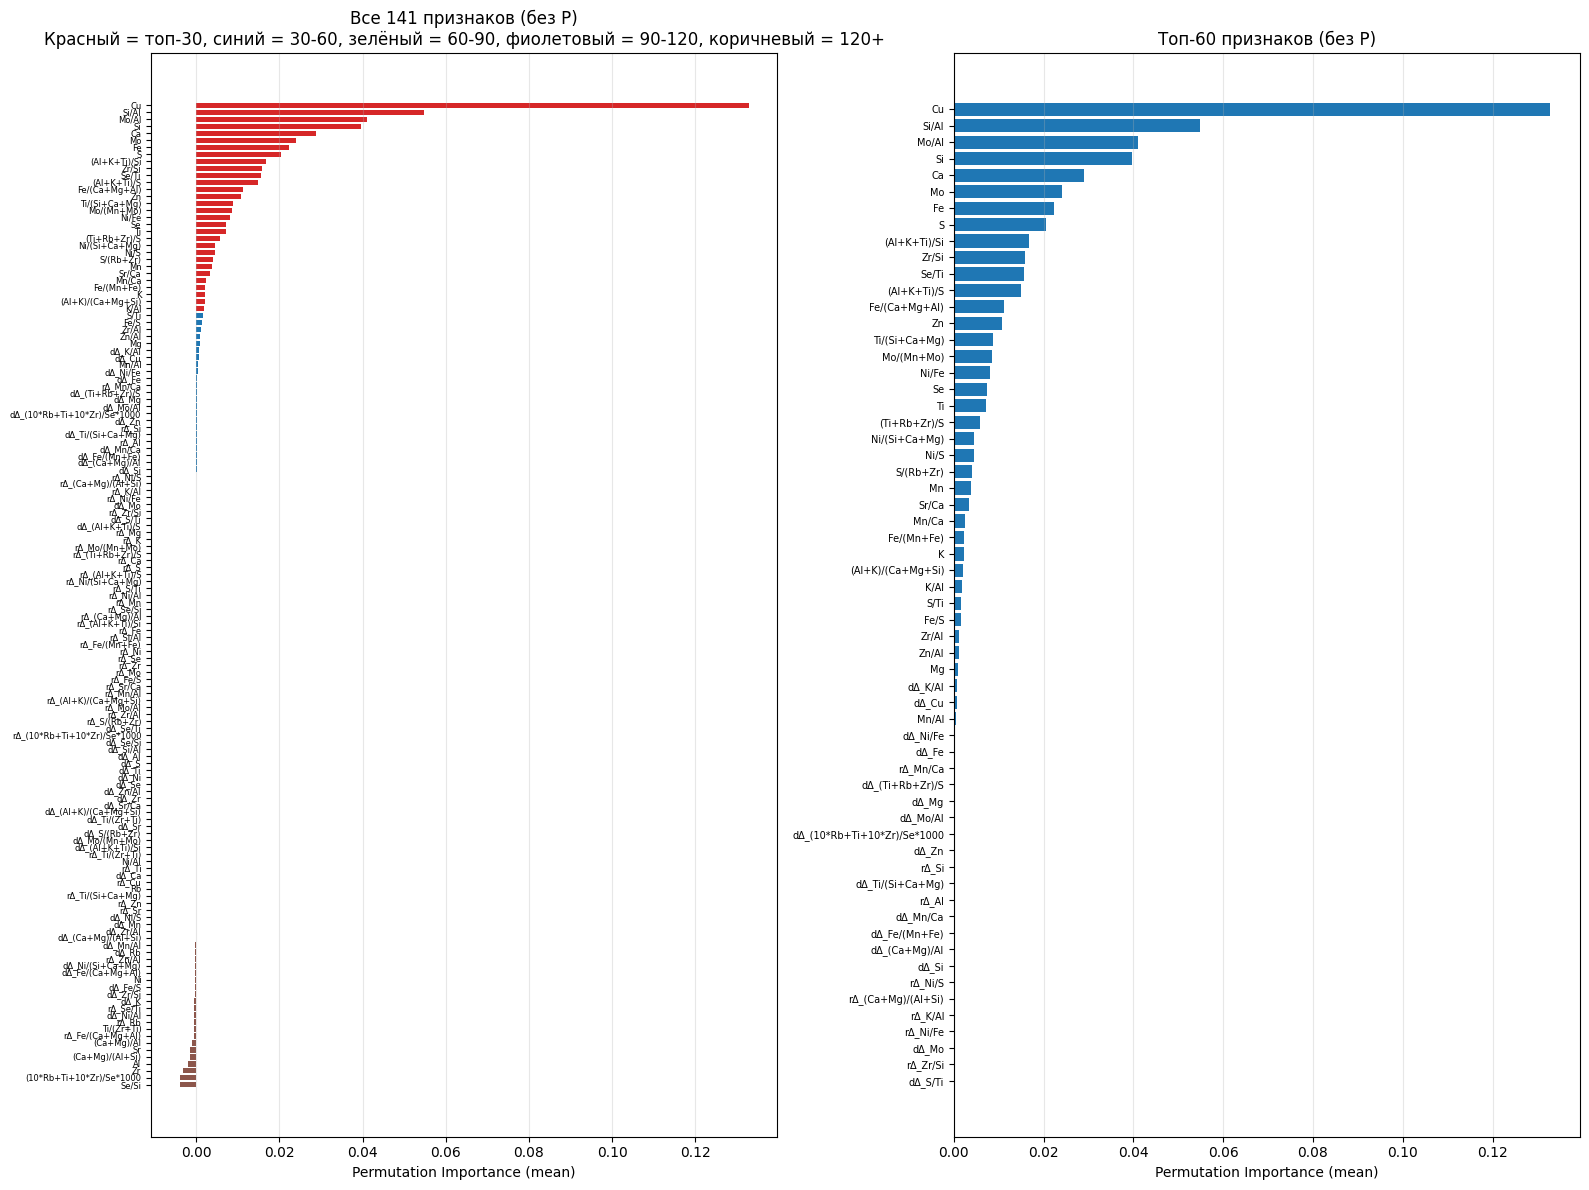

АНАЛИЗ «ЛОКТЯ» (где важность резко падает)
  1. Cu                                       0.132846
  2. Si/Al                                    0.054793
  3. Mo/Al                                    0.041002
  4. Si                                       0.039583
  5. Ca                                       0.028923
  6. Mo                                       0.024004
  7. Fe                                       0.022329
  8. S                                        0.020444
  9. (Al+K+Ti)/Si                             0.016834
 10. Zr/Si                                    0.015746
 11. Se/Ti                                    0.015536
 12. (Al+K+Ti)/S                              0.014842
 13. Fe/(Ca+Mg+Al)                            0.011239
 14. Zn                                       0.010784
 15. Ti/(Si+Ca+Mg)                            0.008819
 16. Mo/(Mn+Mo)                               0.008575
 17. Ni/Fe                                    0.008105
 18. Se               

In [42]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, classification_report
from sklearn.inspection import permutation_importance
from catboost import CatBoostClassifier

# ЗАГРУЗКА (без P)
elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

ratios = [
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al',
    'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'Ni/Fe',
    'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al',
    'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000'
]

synth_files = sorted(glob.glob("Result/Synthetic_slag_06_11/synthetic_slag_w*_*.csv"))
train_wells = ['A1', 'A3', 'A4', 'B1', 'C1', 'C4', 'C5', 'C6', 'D1']
val_wells = ['A2', 'E1']

all_synth = []
for f in synth_files:
    df = pd.read_csv(f)
    df = df[df['Well'].isin(train_wells + val_wells)]
    all_synth.append(df)

df_all = pd.concat(all_synth, ignore_index=True)

# ПРИЗНАКИ (без P)
def compute_all_features(df, elements, ratios, suffix='slag'):
    df = df.copy()
    for el in elements:
        if suffix is not None:
            df[el] = df[f'{el}_{suffix}']
    
    df['(Ca+Mg)/(Al+Si)'] = (df['Ca'] + df['Mg']) / (df['Al'] + df['Si'] + 1e-6)
    df['Sr/Ca'] = df['Sr'] / (df['Ca'] + 1e-6)
    df['Mn/Ca'] = df['Mn'] / (df['Ca'] + 1e-6)
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'] + 1e-6)
    df['Zr/Al'] = df['Zr'] / (df['Al'] + 1e-6)
    df['Zr/Si'] = df['Zr'] / (df['Si'] + 1e-6)
    df['K/Al'] = df['K'] / (df['Al'] + 1e-6)
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'] + 1e-6)
    df['Si/Al'] = df['Si'] / (df['Al'] + 1e-6)
    df['Ni/Fe'] = df['Ni'] / (df['Fe'] + 1e-6)
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'] + 1e-6)
    df['Mo/Al'] = df['Mo'] / (df['Al'] + 1e-6)
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'] + 1e-6)
    df['Mn/Al'] = df['Mn'] / (df['Al'] + 1e-6)
    df['Fe/S'] = df['Fe'] / (df['S'] + 1e-6)
    df['Ni/S'] = df['Ni'] / (df['S'] + 1e-6)
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'] + 1e-6)
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['Fe/(Mn+Fe)'] = df['Fe'] / (df['Mn'] + df['Fe'] + 1e-6)
    df['(Al+K+Ti)/Si'] = (df['Al'] + df['K'] + df['Ti']) / (df['Si'] + 1e-6)
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / (df['S'] + 1e-6)
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / (df['S'] + 1e-6)
    df['S/Ti'] = df['S'] / (df['Ti'] + 1e-6)
    df['Ni/Al'] = df['Ni'] / (df['Al'] + 1e-6)
    df['Zn/Al'] = df['Zn'] / (df['Al'] + 1e-6)
    df['Se/Si'] = df['Se'] / (df['Si'] + 1e-6)
    df['(Ca+Mg)/Al'] = (df['Ca'] + df['Mg']) / (df['Al'] + 1e-6)
    df['Se/Ti'] = df['Se'] / (df['Ti'] + 1e-6)
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / (df['Se'] + 1e-6) * 1000
    
    all_base = elements + ratios
    for well in df['Well'].unique():
        mask = df['Well'] == well
        df_well = df[mask].sort_values('Depth').reset_index(drop=True)
        for feat in all_base:
            if feat in df_well.columns:
                df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
                prev = df_well[feat].shift(1)
                df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
    return df

all_features = elements + ratios + \
               [f'dΔ_{f}' for f in elements + ratios] + \
               [f'rΔ_{f}' for f in elements + ratios]

print(f"Всего признаков: {len(all_features)}")

df_all_feat = compute_all_features(df_all, elements, ratios, suffix='slag')
df_all_feat = df_all_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_all_feat['Strat'] = df_all_feat['Strat'].astype(int)

df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})
df_real['Well'] = df_real['Well'].astype(str) + '_slag'
df_real_feat = compute_all_features(df_real, elements, ratios, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

# ОБУЧЕНИЕ И ВАЖНОСТЬ
X_tr = df_all_feat[all_features]
y_tr = df_all_feat['Strat']
X_vl = df_real_feat[all_features]
y_vl = df_real_feat['Strat']

present_classes = np.unique(y_vl)

fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0'
}

model_all = CatBoostClassifier(**fixed_params)
model_all.fit(X_tr, y_tr)

y_pred_all = model_all.predict(X_vl).ravel()
f1_all = f1_score(y_vl, y_pred_all, average='macro', labels=present_classes)
print(f"F1 macro (все {len(all_features)} признаков): {f1_all:.4f}")

# PERMUTATION IMPORTANCE (все признаки)
print(f"\nСчитаем Permutation Importance для {len(all_features)} признаков...")
perm_imp = permutation_importance(
    model_all, X_vl, y_vl,
    n_repeats=3, random_state=42, scoring='f1_macro'
)

imp_df = pd.DataFrame({
    'feature': all_features,
    'importance_mean': perm_imp.importances_mean,
    'importance_std': perm_imp.importances_std,
}).sort_values('importance_mean', ascending=False).reset_index(drop=True)

imp_df['rank'] = imp_df.index + 1
imp_df.to_csv('Result/permutation_importance_all_features_no_P.csv', index=False)

# ГИСТОГРАММА ВАЖНОСТИ
fig, axes = plt.subplots(1, 2, figsize=(16, 12))

# Все признаки (bar plot)
ax = axes[0]
colors = ['#d62728' if i < 30 else '#1f77b4' if i < 60 else '#2ca02c' if i < 90 else '#9467bd' if i < 120 else '#8c564b' for i in range(len(imp_df))]
ax.barh(imp_df['feature'][::-1], imp_df['importance_mean'][::-1], color=colors[::-1])
ax.set_xlabel('Permutation Importance (mean)')
ax.set_title(f'Все {len(imp_df)} признаков (без P)\nКрасный = топ-30, синий = 30-60, зелёный = 60-90, фиолетовый = 90-120, коричневый = 120+')
ax.grid(alpha=0.3, axis='x')
ax.tick_params(axis='y', labelsize=6)

# Только топ-60 (bar plot)
ax = axes[1]
top60 = imp_df.head(60)
ax.barh(top60['feature'][::-1], top60['importance_mean'][::-1], color='#1f77b4')
ax.set_xlabel('Permutation Importance (mean)')
ax.set_title('Топ-60 признаков (без P)')
ax.grid(alpha=0.3, axis='x')
ax.tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.savefig('Result/permutation_importance_histogram_no_P.png', dpi=150, bbox_inches='tight')
plt.show()
print("АНАЛИЗ «ЛОКТЯ» (где важность резко падает)")
# Печатаем топ-60 с важностью
for i in range(min(60, len(imp_df))):
    marker = " <-- топ-30" if i == 30 else ""
    print(f"{i+1:3d}. {imp_df.iloc[i]['feature']:<40} {imp_df.iloc[i]['importance_mean']:.6f}{marker}")

**Обучение с весами на синтетическом шламе**

In [43]:
elements = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

ratios = [
    '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al',
    'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'Ni/Fe',
    'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al',
    'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al',
    'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000'
]

synth_files = sorted(glob.glob("Result/Synthetic_slag_06_11/synthetic_slag_w*_*.csv"))
train_wells = ['A1', 'A3', 'A4', 'B1', 'C1', 'C4', 'C5', 'C6', 'D1']
val_wells = ['A2', 'E1']

all_synth = []
for f in synth_files:
    df = pd.read_csv(f)
    df = df[df['Well'].isin(train_wells + val_wells)]
    all_synth.append(df)

df_all = pd.concat(all_synth, ignore_index=True)

def compute_all_features(df, elements, ratios, suffix='slag'):
    df = df.copy()
    for el in elements:
        if suffix is not None:
            df[el] = df[f'{el}_{suffix}']
    
    df['(Ca+Mg)/(Al+Si)'] = (df['Ca'] + df['Mg']) / (df['Al'] + df['Si'] + 1e-6)
    df['Sr/Ca'] = df['Sr'] / (df['Ca'] + 1e-6)
    df['Mn/Ca'] = df['Mn'] / (df['Ca'] + 1e-6)
    df['(Al+K)/(Ca+Mg+Si)'] = (df['Al'] + df['K']) / (df['Ca'] + df['Mg'] + df['Si'] + 1e-6)
    df['Zr/Al'] = df['Zr'] / (df['Al'] + 1e-6)
    df['Zr/Si'] = df['Zr'] / (df['Si'] + 1e-6)
    df['K/Al'] = df['K'] / (df['Al'] + 1e-6)
    df['Ti/(Zr+Ti)'] = df['Ti'] / (df['Zr'] + df['Ti'] + 1e-6)
    df['Si/Al'] = df['Si'] / (df['Al'] + 1e-6)
    df['Ni/Fe'] = df['Ni'] / (df['Fe'] + 1e-6)
    df['Ni/(Si+Ca+Mg)'] = df['Ni'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['S/(Rb+Zr)'] = df['S'] / (df['Rb'] + df['Zr'] + 1e-6)
    df['Mo/Al'] = df['Mo'] / (df['Al'] + 1e-6)
    df['Mo/(Mn+Mo)'] = df['Mo'] / (df['Mn'] + df['Mo'] + 1e-6)
    df['Mn/Al'] = df['Mn'] / (df['Al'] + 1e-6)
    df['Fe/S'] = df['Fe'] / (df['S'] + 1e-6)
    df['Ni/S'] = df['Ni'] / (df['S'] + 1e-6)
    df['Fe/(Ca+Mg+Al)'] = df['Fe'] / (df['Ca'] + df['Mg'] + df['Al'] + 1e-6)
    df['Ti/(Si+Ca+Mg)'] = df['Ti'] / (df['Si'] + df['Ca'] + df['Mg'] + 1e-6)
    df['Fe/(Mn+Fe)'] = df['Fe'] / (df['Mn'] + df['Fe'] + 1e-6)
    df['(Al+K+Ti)/Si'] = (df['Al'] + df['K'] + df['Ti']) / (df['Si'] + 1e-6)
    df['(Al+K+Ti)/S'] = (df['Al'] + df['K'] + df['Ti']) / (df['S'] + 1e-6)
    df['(Ti+Rb+Zr)/S'] = (df['Ti'] + df['Rb'] + df['Zr']) / (df['S'] + 1e-6)
    df['S/Ti'] = df['S'] / (df['Ti'] + 1e-6)
    df['Ni/Al'] = df['Ni'] / (df['Al'] + 1e-6)
    df['Zn/Al'] = df['Zn'] / (df['Al'] + 1e-6)
    df['Se/Si'] = df['Se'] / (df['Si'] + 1e-6)
    df['(Ca+Mg)/Al'] = (df['Ca'] + df['Mg']) / (df['Al'] + 1e-6)
    df['Se/Ti'] = df['Se'] / (df['Ti'] + 1e-6)
    df['(10*Rb+Ti+10*Zr)/Se*1000'] = (10*df['Rb'] + df['Ti'] + 10*df['Zr']) / (df['Se'] + 1e-6) * 1000
    
    all_base = elements + ratios
    for well in df['Well'].unique():
        mask = df['Well'] == well
        df_well = df[mask].sort_values('Depth').reset_index(drop=True)
        for feat in all_base:
            if feat in df_well.columns:
                df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
                prev = df_well[feat].shift(1)
                df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
    return df

all_features = elements + ratios + \
               [f'dΔ_{f}' for f in elements + ratios] + \
               [f'rΔ_{f}' for f in elements + ratios]

df_all_feat = compute_all_features(df_all, elements, ratios, suffix='slag')
df_all_feat = df_all_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_all_feat['Strat'] = df_all_feat['Strat'].astype(int)

df_real = pd.read_csv("Data/data_slag_ALLratios_16_10.csv")
if 'Stratigraphy' in df_real.columns:
    df_real = df_real.rename(columns={'Stratigraphy': 'Strat'})
df_real['Well'] = df_real['Well'].astype(str) + '_slag'
df_real_feat = compute_all_features(df_real, elements, ratios, suffix=None)
df_real_feat = df_real_feat.dropna(subset=['Strat']).reset_index(drop=True)
df_real_feat['Strat'] = df_real_feat['Strat'].astype(int)

# CLASS WEIGHTS (обратно пропорционально частоте)
train_class_counts = df_all_feat['Strat'].value_counts()
print("Частота классов в train (синтетика):")
print(train_class_counts)

# Веса: len(train) / (n_classes * count) — стандартная формула
n_total = len(df_all_feat)
n_classes = len(train_class_counts)
class_weights = {cls: n_total / (n_classes * count) for cls, count in train_class_counts.items()}

print("\nВеса классов:")
for cls, w in class_weights.items():
    print(f"  Класс {cls}: вес = {w:.2f}")

# ОБУЧЕНИЕ С CLASS WEIGHTS
print("ОБУЧЕНИЕ С CLASS WEIGHTS (все 141 признак, без P)")

X_tr = df_all_feat[all_features]
y_tr = df_all_feat['Strat']
X_vl = df_real_feat[all_features]
y_vl = df_real_feat['Strat']

present_classes = np.unique(y_vl)

fixed_params = {
    'depth': 6, 'iterations': 500, 'learning_rate': 0.1,
    'l2_leaf_reg': 3, 'loss_function': 'MultiClass',
    'verbose': 0, 'random_seed': 42,
    'task_type': 'GPU', 'devices': '0',
    'class_weights': class_weights  # <-- ВЕСА
}

model_weighted = CatBoostClassifier(**fixed_params)
model_weighted.fit(X_tr, y_tr)

y_pred_weighted = model_weighted.predict(X_vl).ravel()
f1_weighted = f1_score(y_vl, y_pred_weighted, average='macro', labels=present_classes)
print(f"\nF1 macro (с class_weights): {f1_weighted:.4f}")

print(f"\nClassification Report (с class_weights):")
print(classification_report(y_vl, y_pred_weighted, labels=present_classes, digits=4, zero_division=0))

# СРАВНЕНИЕ С БЕЗ ВЕСОВ

print("СРАВНЕНИЕ")
# Без весов
fixed_params_no_weights = {k: v for k, v in fixed_params.items() if k != 'class_weights'}
model_no_weights = CatBoostClassifier(**fixed_params_no_weights)
model_no_weights.fit(X_tr, y_tr)

y_pred_no_weights = model_no_weights.predict(X_vl).ravel()
f1_no_weights = f1_score(y_vl, y_pred_no_weights, average='macro', labels=present_classes)

print(f"F1 macro (без весов):      {f1_no_weights:.4f}")
print(f"F1 macro (с весами):       {f1_weighted:.4f}")
print(f"Разница:                   {(f1_weighted - f1_no_weights)*100:+.1f} п.п.")

/tmp/ipykernel_18299/3265326388.py:70: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'rΔ_{feat}'] = (df_well[feat] / (prev + 1e-6)).fillna(1).values
/tmp/ipykernel_18299/3265326388.py:68: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df.loc[mask, f'dΔ_{feat}'] = df_well[feat].diff().fillna(0).values
/tmp/ipykernel_18299/3265326388.py:70: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

Частота классов в train (синтетика):
Strat
9     16096
0     15680
8     10912
10    10848
3      8608
11     6240
1      6192
2      6032
7      6000
4      5536
6      4240
5      3776
Name: count, dtype: int64

Веса классов:
  Класс 9: вес = 0.52
  Класс 0: вес = 0.53
  Класс 8: вес = 0.76
  Класс 10: вес = 0.77
  Класс 3: вес = 0.97
  Класс 11: вес = 1.34
  Класс 1: вес = 1.35
  Класс 2: вес = 1.38
  Класс 7: вес = 1.39
  Класс 4: вес = 1.51
  Класс 6: вес = 1.97
  Класс 5: вес = 2.21
ОБУЧЕНИЕ С CLASS WEIGHTS (все 141 признак, без P)

F1 macro (с class_weights): 0.5818

Classification Report (с class_weights):
              precision    recall  f1-score   support

           2     0.2712    0.6637    0.3851       226
           3     0.9580    0.8483    0.8998      4304
           4     0.7958    0.8629    0.8280      2123
           5     0.4651    0.3562    0.4035       393
           6     0.6093    0.8500    0.7098       200
           7     0.6183    0.4133    0.4954       196